<a href="https://colab.research.google.com/github/VRaca-Code/P2PCreditRiskValidation/blob/main/notebooks/P2PCreditRiskValidation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Performance, Complexity and Explanation Stability in P2P Credit-Risk Models

**What this notebook does.** It is a thin driver: all logic lives in `src/`, and each section below
calls one module and shows its output. In order it (1) sets up the configuration and a chronological
train / test split, (2) audits the data cleaning, (3) fits every model for every seed, (4) tests H1
(are models performance-equivalent?), (5) tests H2 and H3 (do explanations differ beyond seed noise?),
(6) checks calibration, (7) runs drift, stress and backtest checks, (8) compares runs with and without
the lender's own `int_rate` / `sub_grade`, and (9) builds the scorecard and trade-off plots.

Set `USE_SYNTHETIC = False` and place the LendingClub CSV in `data/raw/` (see `data/README.md`) for the
real analysis. With synthetic data the numbers only prove the pipeline runs.

**Hypotheses.** H1: model pairs are performance-equivalent (PR-AUC, TOST) or not. H2: explanations
shift between models by more than seed-to-seed variation. H3: some pair is equivalent in performance
but explained differently.

> **Five-model version.** This notebook selects Logistic Regression, Random Forest, XGBoost, DNN and KAN in the original configuration cell. Run cells from top to bottom to regenerate consistent tables and figures. Synthetic data is a pipeline demonstration, not real-world validation.


In [1]:
!git clone https://github.com/VRaca-Code/P2PCreditRiskValidation.git
%cd /content/P2PCreditRiskValidation

Cloning into 'P2PCreditRiskValidation'...
remote: Enumerating objects: 114, done.
remote: Counting objects: 100% (114/114), done.
remote: Compressing objects: 100% (99/99), done.
remote: Total 114 (delta 36), reused 66 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (114/114), 5.57 MiB | 7.17 MiB/s, done.
Resolving deltas: 100% (36/36), done.
/content/P2PCreditRiskValidation


In [2]:
!python -m compileall -q src
print("Python syntax check completed.")

Python syntax check completed.


In [3]:
!python -m src.experiments \
    --synthetic \
    --seeds 3 \
    --models "Logistic Regression" "Random Forest" \
    --explain-method permutation \
    --no-robustness \
    --no-figures \
    --out results/smoke_permutation

train 5,841 rows (default 14.35%) | test 1,601 rows (default 17.18%)
  Logistic Regression  seed 0   PR-AUC 0.2773  ROC-AUC 0.6559  fit   0.1s  expl=permutation
  Logistic Regression  seed 1   PR-AUC 0.2790  ROC-AUC 0.6526  fit   0.1s  expl=permutation
  Logistic Regression  seed 2   PR-AUC 0.2729  ROC-AUC 0.6443  fit   0.1s  expl=permutation
  Random Forest        seed 0   PR-AUC 0.3057  ROC-AUC 0.6543  fit   2.7s  expl=permutation
  Random Forest        seed 1   PR-AUC 0.2961  ROC-AUC 0.6578  fit   2.1s  expl=permutation
  Random Forest        seed 2   PR-AUC 0.2891  ROC-AUC 0.6500  fit   2.1s  expl=permutation
  H1 bootstrap Logistic Regression vs Random Forest

Model summary
                      roc_auc  pr_auc  ...  seed_std_pr_auc  explanation_stability
Model                                 ...                                        
Logistic Regression   0.6509  0.2764  ...           0.0031                 0.7779
Random Forest         0.6540  0.2970  ...           0.0083       

In [4]:
!python -m src.experiments \
    --synthetic \
    --seeds 3 \
    --models "Logistic Regression" "Random Forest" \
    --explain-method shap \
    --no-robustness \
    --no-figures \
    --out results/smoke_shap

train 5,841 rows (default 14.35%) | test 1,601 rows (default 17.18%)
  Logistic Regression  seed 0   PR-AUC 0.2773  ROC-AUC 0.6559  fit   0.1s  expl=shap
  Logistic Regression  seed 1   PR-AUC 0.2790  ROC-AUC 0.6526  fit   0.1s  expl=shap
  Logistic Regression  seed 2   PR-AUC 0.2729  ROC-AUC 0.6443  fit   0.1s  expl=shap
  Random Forest        seed 0   PR-AUC 0.3057  ROC-AUC 0.6543  fit   2.5s  expl=shap
  Random Forest        seed 1   PR-AUC 0.2961  ROC-AUC 0.6578  fit   3.7s  expl=shap
  Random Forest        seed 2   PR-AUC 0.2891  ROC-AUC 0.6500  fit   2.5s  expl=shap
  H1 bootstrap Logistic Regression vs Random Forest

Model summary
                      roc_auc  pr_auc  ...  seed_std_pr_auc  explanation_stability
Model                                 ...                                        
Logistic Regression   0.6509  0.2764  ...           0.0031                 0.8137
Random Forest         0.6540  0.2970  ...           0.0083                 0.9413

[2 rows x 7 columns]

H1

In [5]:
import pandas as pd

h2 = pd.read_csv("results/smoke_shap/h2_results.csv")
display(h2)

,Model_A,Model_B,kind,d_cross,d_within,theta,ci90_low,ci90_high,p_value,p_holm,Supported
0,Logistic Regression,Random Forest,membership,0.376068,0.227273,0.148796,0.042735,0.285159,0.000629,0.000629,True
1,Logistic Regression,Random Forest,ranking,0.292867,0.122530,0.170337,0.122216,0.224104,0.000629,0.000629,True


In [6]:

import numpy as np
import pandas as pd

from src.stats import explanation_shift_test

# Simulation settings
N_SIM = 100
N_SEEDS = 3
N_FEATURES = 20
N_BOOT = 300
ALPHA = 0.05

rng = np.random.default_rng(42)
results = []

for kind in ("membership", "ranking"):
    p_values = []
    positive_effects = []

    for simulation in range(N_SIM):
        # Both groups come from the SAME distribution.
        # Under this null, neither group has a model-specific
        # explanation pattern.
        baseline = rng.dirichlet(np.ones(N_FEATURES) * 2)

        A = rng.dirichlet(baseline * 100, size=N_SEEDS)
        B = rng.dirichlet(baseline * 100, size=N_SEEDS)

        columns = [f"feature_{i}" for i in range(N_FEATURES)]
        imp_a = pd.DataFrame(A, columns=columns)
        imp_b = pd.DataFrame(B, columns=columns)

        test = explanation_shift_test(
            imp_a,
            imp_b,
            kind=kind,
            k=10,
            n_boot=N_BOOT,
            alpha=ALPHA,
            seed=simulation,
        )

        p_values.append(test["p_value"])
        positive_effects.append(test["theta"] > 0)

    p_values = np.asarray(p_values)
    positive_effects = np.asarray(positive_effects)

    false_positive_rate = np.mean(
        (p_values < ALPHA) & positive_effects
    )

    results.append({
        "kind": kind,
        "simulations": N_SIM,
        "nominal_alpha": ALPHA,
        "false_positive_rate": false_positive_rate,
        "significant_cases": int(
            np.sum((p_values < ALPHA) & positive_effects)
        ),
    })

display(pd.DataFrame(results))


,kind,simulations,nominal_alpha,false_positive_rate,significant_cases
0,membership,100,0.05,0.05,5
1,ranking,100,0.05,0.06,6


In [ ]:

import numpy as np
import pandas as pd
from src.stats import explanation_shift_test

# Extended H2 validation
N_SIM = 500
N_BOOT = 300
ALPHA = 0.05
N_FEATURES = 20
SEED_COUNTS = [3, 5, 10]

rng = np.random.default_rng(42)
results = []

scenarios = {
    "distinct_features": 30,
    "moderate_overlap": 100,
    "near_tied_features": 500,
}

for scenario, concentration in scenarios.items():
    for n_seeds in SEED_COUNTS:
        for kind in ("membership", "ranking"):

            false_positives = 0
            invalid_tests = 0

            for simulation in range(N_SIM):
                # Both groups are generated from the same
                # distribution: no systematic model difference.
                if scenario == "near_tied_features":
                    baseline = np.ones(N_FEATURES) / N_FEATURES
                else:
                    baseline = rng.dirichlet(
                        np.ones(N_FEATURES) * 2
                    )

                A = rng.dirichlet(
                    baseline * concentration,
                    size=n_seeds
                )
                B = rng.dirichlet(
                    baseline * concentration,
                    size=n_seeds
                )

                columns = [
                    f"feature_{i}" for i in range(N_FEATURES)
                ]

                imp_a = pd.DataFrame(A, columns=columns)
                imp_b = pd.DataFrame(B, columns=columns)

                test = explanation_shift_test(
                    imp_a,
                    imp_b,
                    kind=kind,
                    k=10,
                    n_boot=N_BOOT,
                    alpha=ALPHA,
                    seed=simulation
                )

                if not np.isfinite(test["p_value"]):
                    invalid_tests += 1
                    continue

                if (
                    test["p_value"] < ALPHA
                    and test["theta"] > 0
                ):
                    false_positives += 1

            valid_tests = N_SIM - invalid_tests

            results.append({
                "scenario": scenario,
                "seeds": n_seeds,
                "kind": kind,
                "valid_tests": valid_tests,
                "false_positives": false_positives,
                "false_positive_rate": (
                    false_positives / valid_tests
                    if valid_tests else np.nan
                ),
            })

validation = pd.DataFrame(results)
display(validation)


In [ ]:

import numpy as np
import pandas as pd
from itertools import product

from src.stats import _pair_matrix, _mean_offdiag


def h2_paired_permutation_test(
    imp_a, imp_b, kind="membership", k=10
):
    """Exact paired-label randomization test.

    Requires the same seed labels in both DataFrames.
    Null: model labels are exchangeable within seed.
    """
    if not imp_a.index.equals(imp_b.index):
        raise ValueError("Models must have matching seed indices.")

    n = len(imp_a)
    if n < 2:
        raise ValueError("At least two seeds are required.")

    def statistic(A, B):
        aa = _pair_matrix(A, A, kind, k)
        bb = _pair_matrix(B, B, kind, k)
        ab = _pair_matrix(A, B, kind, k)

        within = 0.5 * (
            _mean_offdiag(aa) + _mean_offdiag(bb)
        )
        cross = np.nanmean(ab)
        return float(cross - within)

    observed = statistic(imp_a, imp_b)

    null_stats = []

    for swaps in product((False, True), repeat=n):
        A = imp_a.copy()
        B = imp_b.copy()

        for i, swap in enumerate(swaps):
            if swap:
                A.iloc[i] = imp_b.iloc[i].to_numpy()
                B.iloc[i] = imp_a.iloc[i].to_numpy()

        null_stats.append(statistic(A, B))

    null_stats = np.asarray(null_stats)

    p_value = np.mean(null_stats >= observed - 1e-12)

    return {
        "theta": observed,
        "p_value": float(p_value),
        "n_permutations": len(null_stats),
    }


In [10]:

imp = pd.read_csv("results/smoke_shap/importances.csv")

def importance_matrix(model):
    return (
        imp[imp["Model"] == model]
        .pivot(index="Seed", columns="Feature", values="Importance")
        .fillna(0.0)
        .sort_index()
    )

A = importance_matrix("Logistic Regression")
B = importance_matrix("Random Forest")

for kind in ("membership", "ranking"):
    result = h2_paired_permutation_test(
        A, B, kind=kind, k=10
    )
    print(kind, result)


membership {'theta': 0.14879564879564888, 'p_value': 0.25, 'n_permutations': 8}
ranking {'theta': 0.1703369094673443, 'p_value': 0.25, 'n_permutations': 8}


In [11]:
!python -m src.experiments \
    --synthetic \
    --seeds 10 \
    --models "Logistic Regression" "Random Forest" \
    --explain-method shap \
    --no-robustness \
    --no-figures \
    --out results/smoke_shap_10seeds

train 5,841 rows (default 14.35%) | test 1,601 rows (default 17.18%)
  Logistic Regression  seed 0   PR-AUC 0.2773  ROC-AUC 0.6559  fit   0.1s  expl=shap
  Logistic Regression  seed 1   PR-AUC 0.2790  ROC-AUC 0.6526  fit   0.1s  expl=shap
  Logistic Regression  seed 2   PR-AUC 0.2729  ROC-AUC 0.6443  fit   0.1s  expl=shap
  Logistic Regression  seed 3   PR-AUC 0.2801  ROC-AUC 0.6477  fit   0.1s  expl=shap
  Logistic Regression  seed 4   PR-AUC 0.2793  ROC-AUC 0.6516  fit   0.1s  expl=shap
  Logistic Regression  seed 5   PR-AUC 0.2787  ROC-AUC 0.6503  fit   0.1s  expl=shap
  Logistic Regression  seed 6   PR-AUC 0.2765  ROC-AUC 0.6490  fit   0.1s  expl=shap
  Logistic Regression  seed 7   PR-AUC 0.2705  ROC-AUC 0.6447  fit   0.1s  expl=shap
  Logistic Regression  seed 8   PR-AUC 0.2742  ROC-AUC 0.6488  fit   0.1s  expl=shap
  Logistic Regression  seed 9   PR-AUC 0.2789  ROC-AUC 0.6468  fit   0.1s  expl=shap
  Random Forest        seed 0   PR-AUC 0.3057  ROC-AUC 0.6543  fit   2.0s  expl=s

In [12]:
import pandas as pd

# Load explanations from the 10-seed experiment.
imp = pd.read_csv(
    "results/smoke_shap_10seeds/importances.csv"
)

# Uses the importance_matrix() and
# h2_paired_permutation_test() functions
# defined in your earlier Colab cells.
A = importance_matrix("Logistic Regression")
B = importance_matrix("Random Forest")

print("Number of seeds:", len(A))
print("Matched seed indices:", A.index.equals(B.index))

for kind in ("membership", "ranking"):
    result = h2_paired_permutation_test(
        A, B, kind=kind, k=10
    )
    print(kind, result)

Number of seeds: 10
Matched seed indices: True
membership {'theta': 0.17762237762237765, 'p_value': 0.001953125, 'n_permutations': 1024}
ranking {'theta': 0.21451408494886767, 'p_value': 0.001953125, 'n_permutations': 1024}


In [13]:

import numpy as np
import pandas as pd
from itertools import product
from src.stats import _pair_matrix

def fast_h2_permutation(A, B, kind="membership", k=10):
    n = len(A)

    # Calculate all distances only once.
    combined = pd.concat([A, B], ignore_index=True)
    D = _pair_matrix(combined, combined, kind, k)

    pairs = np.triu_indices(n, 1)
    base = np.arange(n)

    def theta(swap):
        ia = np.where(swap, base + n, base)
        ib = np.where(swap, base, base + n)

        within_a = np.nanmean(D[np.ix_(ia, ia)][pairs])
        within_b = np.nanmean(D[np.ix_(ib, ib)][pairs])
        cross = np.nanmean(D[np.ix_(ia, ib)])

        return cross - 0.5 * (within_a + within_b)

    observed = theta(np.zeros(n, dtype=bool))

    null = np.array([
        theta(np.array(swap, dtype=bool))
        for swap in product([False, True], repeat=n)
    ])

    return {
        "theta": observed,
        "p_value": float(np.mean(null >= observed - 1e-12))
    }


# Small calibration experiment
rng = np.random.default_rng(42)
N_SIM = 20
N_SEEDS = 10
false_positives = {"membership": 0, "ranking": 0}

for simulation in range(N_SIM):
    baseline = rng.dirichlet(np.ones(20) * 2)

    A = pd.DataFrame(
        rng.dirichlet(baseline * 100, size=N_SEEDS)
    )
    B = pd.DataFrame(
        rng.dirichlet(baseline * 100, size=N_SEEDS)
    )

    for kind in false_positives:
        result = fast_h2_permutation(A, B, kind=kind)

        if result["p_value"] < 0.05:
            false_positives[kind] += 1

print("Permutation calibration:")
for kind, count in false_positives.items():
    print(f"{kind}: {count}/{N_SIM} false positives")


Permutation calibration:
membership: 3/20 false positives
ranking: 1/20 false positives


In [16]:
import numpy as np

for kind in ("membership", "ranking"):
    original = h2_paired_permutation_test(A, B, kind=kind, k=10)
    optimized = fast_h2_permutation(A, B, kind=kind, k=10)

    print(f"\n{kind}")
    print("Original:", original)
    print("Optimized:", optimized)

    assert np.isclose(original["theta"], optimized["theta"])
    assert np.isclose(original["p_value"], optimized["p_value"])

print("\nBoth implementations agree.")


membership
Original: {'theta': -0.006108336108336276, 'p_value': 0.41015625, 'n_permutations': 1024}
Optimized: {'theta': np.float64(-0.006108336108336165), 'p_value': 0.41015625}

ranking
Original: {'theta': 0.015804511278195543, 'p_value': 0.14453125, 'n_permutations': 1024}
Optimized: {'theta': np.float64(0.015804511278195543), 'p_value': 0.14453125}

Both implementations agree.


In [15]:
import numpy as np
import pandas as pd
import time

# Uses fast_h2_permutation() from your previous cell.

N_SIM = 200
N_SEEDS = 10
N_FEATURES = 20
ALPHA = 0.05

rng = np.random.default_rng(2026)
results = []

start = time.time()

for kind in ("membership", "ranking"):
    false_positives = 0

    for sim in range(N_SIM):
        baseline = rng.dirichlet(np.ones(N_FEATURES) * 2)

        A = pd.DataFrame(
            rng.dirichlet(baseline * 100, size=N_SEEDS)
        )
        B = pd.DataFrame(
            rng.dirichlet(baseline * 100, size=N_SEEDS)
        )

        result = fast_h2_permutation(
            A, B, kind=kind, k=10
        )

        if result["p_value"] < ALPHA:
            false_positives += 1

    results.append({
        "kind": kind,
        "simulations": N_SIM,
        "false_positives": false_positives,
        "false_positive_rate": false_positives / N_SIM
    })

display(pd.DataFrame(results))
print(f"Elapsed time: {(time.time() - start):.1f} seconds")

,kind,simulations,false_positives,false_positive_rate
0,membership,200,17,0.085
1,ranking,200,11,0.055


Elapsed time: 175.4 seconds


In [17]:
import numpy as np

for kind in ("membership", "ranking"):
    original = h2_paired_permutation_test(A, B, kind=kind, k=10)
    optimized = fast_h2_permutation(A, B, kind=kind, k=10)

    print(f"\n{kind}")
    print("Original:", original)
    print("Optimized:", optimized)

    assert np.isclose(original["theta"], optimized["theta"])
    assert np.isclose(original["p_value"], optimized["p_value"])

print("\nBoth implementations agree.")


membership
Original: {'theta': -0.006108336108336276, 'p_value': 0.41015625, 'n_permutations': 1024}
Optimized: {'theta': np.float64(-0.006108336108336165), 'p_value': 0.41015625}

ranking
Original: {'theta': 0.015804511278195543, 'p_value': 0.14453125, 'n_permutations': 1024}
Optimized: {'theta': np.float64(0.015804511278195543), 'p_value': 0.14453125}

Both implementations agree.


In [18]:
import numpy as np

for kind in ("membership", "ranking"):
    original = h2_paired_permutation_test(A, B, kind=kind, k=10)
    optimized = fast_h2_permutation(A, B, kind=kind, k=10)

    print(f"\n{kind}")
    print("Original:", original)
    print("Optimized:", optimized)

    assert np.isclose(original["theta"], optimized["theta"])
    assert np.isclose(original["p_value"], optimized["p_value"])

print("\nBoth implementations agree.")


membership
Original: {'theta': -0.006108336108336276, 'p_value': 0.41015625, 'n_permutations': 1024}
Optimized: {'theta': np.float64(-0.006108336108336165), 'p_value': 0.41015625}

ranking
Original: {'theta': 0.015804511278195543, 'p_value': 0.14453125, 'n_permutations': 1024}
Optimized: {'theta': np.float64(0.015804511278195543), 'p_value': 0.14453125}

Both implementations agree.


In [19]:
imp = pd.read_csv("results/smoke_shap_10seeds/importances.csv")

A = importance_matrix("Logistic Regression")
B = importance_matrix("Random Forest")

for kind in ("membership", "ranking"):
    result = fast_h2_permutation(A, B, kind=kind, k=10)
    print(kind, result)

membership {'theta': np.float64(0.17762237762237762), 'p_value': 0.001953125}
ranking {'theta': np.float64(0.21451408494886764), 'p_value': 0.001953125}


In [20]:

import numpy as np
import pandas as pd
import time

N_SIM = 200
N_SEEDS = 10
N_FEATURES = 20
ALPHA = 0.05

rng = np.random.default_rng(2026)
results = []
start = time.time()

for kind in ("membership", "ranking"):
    false_positives = 0
    p_values = []

    for sim in range(N_SIM):
        baseline = rng.dirichlet(
            np.ones(N_FEATURES) * 2
        )

        # Shared seed-specific effects
        seed_centers = rng.dirichlet(
            baseline * 100,
            size=N_SEEDS
        )

        A = np.array([
            rng.dirichlet(center * 200)
            for center in seed_centers
        ])

        B = np.array([
            rng.dirichlet(center * 200)
            for center in seed_centers
        ])

        # Randomly exchange labels within matched pairs.
        swaps = rng.integers(0, 2, N_SEEDS).astype(bool)

        A_original = A.copy()
        A[swaps] = B[swaps]
        B[swaps] = A_original[swaps]

        columns = [
            f"feature_{i}" for i in range(N_FEATURES)
        ]

        imp_a = pd.DataFrame(A, columns=columns)
        imp_b = pd.DataFrame(B, columns=columns)

        result = fast_h2_permutation(
            imp_a,
            imp_b,
            kind=kind,
            k=10
        )

        p_values.append(result["p_value"])

        if result["p_value"] < ALPHA:
            false_positives += 1

    results.append({
        "kind": kind,
        "simulations": N_SIM,
        "false_positives": false_positives,
        "false_positive_rate": false_positives / N_SIM,
        "mean_p_value": np.mean(p_values)
    })

display(pd.DataFrame(results))
print(f"Elapsed time: {time.time() - start:.1f} seconds")


,kind,simulations,false_positives,false_positive_rate,mean_p_value
0,membership,200,8,0.040,0.487568
1,ranking,200,13,0.065,0.464541


Elapsed time: 156.3 seconds


In [21]:

import numpy as np
import pandas as pd
import time

rng = np.random.default_rng(2027)

N_SIM = 30
N_SEEDS = 10
N_FEATURES = 20

results = []
start = time.time()

for scenario in ("null", "alternative"):
    for kind in ("membership", "ranking"):
        significant = 0
        effects = []

        for sim in range(N_SIM):
            baseline_a = np.ones(N_FEATURES) * 2
            baseline_b = baseline_a.copy()

            if scenario == "alternative":
                # Model B emphasizes features 10-19
                # rather than features 0-9.
                baseline_a[:10] = 5
                baseline_a[10:] = 1

                baseline_b[:10] = 1
                baseline_b[10:] = 5

            A = pd.DataFrame(
                rng.dirichlet(
                    baseline_a * 10,
                    size=N_SEEDS
                )
            )

            B = pd.DataFrame(
                rng.dirichlet(
                    baseline_b * 10,
                    size=N_SEEDS
                )
            )

            result = fast_h2_permutation(
                A, B, kind=kind, k=10
            )

            effects.append(result["theta"])

            if result["p_value"] < 0.05:
                significant += 1

        results.append({
            "scenario": scenario,
            "kind": kind,
            "significant": significant,
            "simulations": N_SIM,
            "rejection_rate": significant / N_SIM,
            "mean_theta": np.mean(effects)
        })

display(pd.DataFrame(results))

print(
    f"Elapsed time: {time.time() - start:.1f} seconds"
)


,scenario,kind,significant,simulations,rejection_rate,mean_theta
0,null,membership,0,30,0.0,-0.003447
1,null,ranking,0,30,0.0,-0.004425
2,alternative,membership,30,30,1.0,1.000000
3,alternative,ranking,30,30,1.0,1.504885


Elapsed time: 49.4 seconds


In [22]:

import numpy as np
import pandas as pd
import time

rng = np.random.default_rng(2028)

N_SIM = 30
N_SEEDS = 10
N_FEATURES = 20

results = []
start = time.time()

for shift in (0.0, 0.5, 1.0, 2.0):
    for kind in ("membership", "ranking"):
        significant = 0
        effects = []

        for sim in range(N_SIM):
            baseline_a = np.ones(N_FEATURES) * 2
            baseline_b = baseline_a.copy()

            # Moderate differences in feature emphasis
            baseline_a[:10] += shift
            baseline_b[10:] += shift

            A = pd.DataFrame(
                rng.dirichlet(
                    baseline_a * 10,
                    size=N_SEEDS
                )
            )

            B = pd.DataFrame(
                rng.dirichlet(
                    baseline_b * 10,
                    size=N_SEEDS
                )
            )

            result = fast_h2_permutation(
                A, B, kind=kind, k=10
            )

            effects.append(result["theta"])

            if result["p_value"] < 0.05:
                significant += 1

        results.append({
            "shift": shift,
            "kind": kind,
            "rejections": significant,
            "rejection_rate": significant / N_SIM,
            "mean_theta": np.mean(effects)
        })

display(pd.DataFrame(results))
print(f"Elapsed: {time.time() - start:.1f} seconds")


,shift,kind,rejections,rejection_rate,mean_theta
0,0.0,membership,0,0.000000,0.001534
1,0.0,ranking,4,0.133333,0.006691
2,0.5,membership,30,1.000000,0.149690
3,0.5,ranking,30,1.000000,0.438464
4,1.0,membership,30,1.000000,0.454130
5,1.0,ranking,30,1.000000,1.061528
6,2.0,membership,30,1.000000,0.890808
7,2.0,ranking,30,1.000000,1.477440


Elapsed: 98.2 seconds


In [23]:

import numpy as np
import pandas as pd

from src.stats import _pair_matrix

imp = pd.read_csv(
    "results/smoke_shap_10seeds/importances.csv"
)

models = sorted(imp["Model"].unique())
rows = []

for model in models:
    matrix = (
        imp[imp["Model"] == model]
        .pivot(
            index="Seed",
            columns="Feature",
            values="Importance"
        )
        .fillna(0)
        .sort_index()
    )

    for kind in ("membership", "ranking"):
        distances = _pair_matrix(
            matrix, matrix, kind=kind, k=10
        )

        # Unique pairs of distinct seeds
        upper = distances[
            np.triu_indices(len(matrix), k=1)
        ]

        rows.append({
            "model": model,
            "kind": kind,
            "n_seeds": len(matrix),
            "mean_instability": np.nanmean(upper),
            "sd_pairwise_distance": np.nanstd(
                upper, ddof=1
            )
        })

stability = pd.DataFrame(rows)

display(
    stability.sort_values(
        ["kind", "mean_instability"]
    )
)


,model,kind,n_seeds,mean_instability,sd_pairwise_distance
0,Logistic Regression,membership,10,0.220202,0.092592
2,Random Forest,membership,10,0.269308,0.108369
3,Random Forest,ranking,10,0.095966,0.043435
1,Logistic Regression,ranking,10,0.139105,0.041972


In [24]:

import numpy as np
import pandas as pd
from src.stats import _pair_matrix

imp = pd.read_csv(
    "results/smoke_shap_10seeds/importances.csv"
)

def get_importance_matrix(model):
    return (
        imp[imp["Model"] == model]
        .pivot(index="Seed", columns="Feature", values="Importance")
        .fillna(0)
        .sort_index()
    )

A = get_importance_matrix("Logistic Regression")
B = get_importance_matrix("Random Forest")

assert A.index.equals(B.index)
assert A.columns.equals(B.columns)

rng = np.random.default_rng(2030)
N_BOOT = 2000
results = []

for kind in ("membership", "ranking"):
    D_a = _pair_matrix(A, A, kind=kind, k=10)
    D_b = _pair_matrix(B, B, kind=kind, k=10)

    n = len(A)
    upper = np.triu_indices(n, k=1)

    # Positive = Random Forest is less stable.
    observed = np.mean(D_b[upper] - D_a[upper])

    boot = []

    for _ in range(N_BOOT):
        indices = rng.integers(0, n, size=n)

        # Retain comparisons between distinct original seeds.
        i, j = np.triu_indices(n, k=1)
        valid = indices[i] != indices[j]

        if not np.any(valid):
            continue

        differences = (
            D_b[indices[i[valid]], indices[j[valid]]]
            - D_a[indices[i[valid]], indices[j[valid]]]
        )

        boot.append(np.mean(differences))

    boot = np.asarray(boot)

    results.append({
        "kind": kind,
        "difference_RF_minus_LR": observed,
        "ci95_low": np.percentile(boot, 2.5),
        "ci95_high": np.percentile(boot, 97.5),
        "bootstrap_samples": len(boot)
    })

display(pd.DataFrame(results))


,kind,difference_RF_minus_LR,ci95_low,ci95_high,bootstrap_samples
0,membership,0.049106,-0.034116,0.122611,2000
1,ranking,-0.043139,-0.085519,0.000811,2000


In [25]:

import numpy as np
import pandas as pd
from src.stats import _pair_matrix

rows = []

for kind in ("membership", "ranking"):
    D_a = _pair_matrix(A, A, kind=kind, k=10)
    D_b = _pair_matrix(B, B, kind=kind, k=10)

    for omitted_seed in range(len(A)):
        keep = np.array([
            i for i in range(len(A))
            if i != omitted_seed
        ])

        upper = np.triu_indices(len(keep), k=1)

        instability_a = np.mean(
            D_a[np.ix_(keep, keep)][upper]
        )

        instability_b = np.mean(
            D_b[np.ix_(keep, keep)][upper]
        )

        rows.append({
            "kind": kind,
            "omitted_seed": A.index[omitted_seed],
            "difference_RF_minus_LR": (
                instability_b - instability_a
            )
        })

sensitivity = pd.DataFrame(rows)

summary = (
    sensitivity.groupby("kind")["difference_RF_minus_LR"]
    .agg(["min", "max", "mean"])
    .reset_index()
)

display(summary)
display(sensitivity)


,kind,min,max,mean
0,membership,0.019749,0.075499,0.049106
1,ranking,-0.059289,-0.032248,-0.043139


,kind,omitted_seed,difference_RF_minus_LR
0,membership,0,0.040145
1,membership,1,0.054455
2,membership,2,0.075499
3,membership,3,0.041634
4,membership,4,0.047915
5,membership,5,0.019749
6,membership,6,0.052966
7,membership,7,0.052966
8,membership,8,0.048563
9,membership,9,0.057174


In [30]:

from pathlib import Path

path = Path("src/stats.py")
source = path.read_text()

new_code = '''

# ----------------------------------------------------------------------------- H2a
def explanation_stability_test(
    imp_a: pd.DataFrame,
    imp_b: pd.DataFrame,
    kind: str = "membership",
    k: int = 10,
    n_boot: int = 2000,
    alpha: float = 0.05,
    seed: int = 0,
) -> dict:
    """Compare within-model explanation instability across matched seeds.

    Difference = instability(B) - instability(A).
    Bootstrap intervals are exploratory; coverage is not calibrated.
    """
    if not imp_a.index.equals(imp_b.index):
        raise ValueError("Model seed indices must match in the same order.")
    if not imp_a.columns.equals(imp_b.columns):
        raise ValueError("Feature columns must match in the same order.")
    if len(imp_a) < 3:
        raise ValueError("At least three matched seeds are required.")
    if n_boot < 1:
        raise ValueError("n_boot must be positive.")
    if not 0 < alpha < 1:
        raise ValueError("alpha must be between 0 and 1.")

    D_a = _pair_matrix(imp_a, imp_a, kind, k)
    D_b = _pair_matrix(imp_b, imp_b, kind, k)

    instability_a = _mean_offdiag(D_a)
    instability_b = _mean_offdiag(D_b)
    difference = instability_b - instability_a

    rng = np.random.default_rng(seed)
    n = len(imp_a)
    boot = []

    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        a = _mean_offdiag(D_a, idx)
        b = _mean_offdiag(D_b, idx)
        if np.isfinite(a) and np.isfinite(b):
            boot.append(b - a)

    if not boot:
        raise ValueError("No valid bootstrap resamples.")

    ci_low, ci_high = np.quantile(
        boot, [alpha / 2, 1 - alpha / 2]
    )

    loo = []
    for omitted in range(n):
        keep = np.delete(np.arange(n), omitted)
        loo.append(
            _mean_offdiag(D_b, keep)
            - _mean_offdiag(D_a, keep)
        )

    return {
        "kind": kind,
        "n_seeds": n,
        "instability_a": float(instability_a),
        "instability_b": float(instability_b),
        "difference_b_minus_a": float(difference),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "alpha": float(alpha),
        "n_boot_valid": len(boot),
        "loo_min": float(np.min(loo)),
        "loo_max": float(np.max(loo)),
        "loo_same_direction": bool(
            all(x > 0 for x in loo)
            if difference > 0
            else all(x < 0 for x in loo)
            if difference < 0
            else all(x == 0 for x in loo)
        ),
    }
'''

if "def explanation_stability_test(" in source:
    print("Function already exists; no changes made.")
else:
    path.write_text(source + new_code)
    print("H2a function added successfully.")

# Check Python syntax
import py_compile
py_compile.compile(str(path), doraise=True)
print("Syntax check passed.")


H2a function added successfully.
Syntax check passed.


In [31]:

import importlib
import numpy as np
import pandas as pd
import src.stats as stats

# Reload the updated module
importlib.reload(stats)

# Load the saved SHAP explanations
imp = pd.read_csv(
    "results/smoke_shap_10seeds/importances.csv"
)

def get_importance_matrix(model):
    return (
        imp[imp["Model"] == model]
        .pivot(
            index="Seed",
            columns="Feature",
            values="Importance"
        )
        .fillna(0)
        .sort_index()
    )

A = get_importance_matrix("Logistic Regression")
B = get_importance_matrix("Random Forest")

# Run both H2a stability comparisons
results = []

for kind in ("membership", "ranking"):
    result = stats.explanation_stability_test(
        A,
        B,
        kind=kind,
        k=10,
        n_boot=2000,
        alpha=0.05,
        seed=42
    )
    results.append(result)

summary = pd.DataFrame(results)

display(summary[[
    "kind",
    "instability_a",
    "instability_b",
    "difference_b_minus_a",
    "ci_low",
    "ci_high",
    "loo_min",
    "loo_max",
    "loo_same_direction"
]])

# Verify previously observed point estimates
expected = {
    "membership": (0.220202, 0.269308, 0.049106),
    "ranking": (0.139105, 0.095966, -0.043139),
}

for _, row in summary.iterrows():
    target = expected[row["kind"]]
    actual = (
        row["instability_a"],
        row["instability_b"],
        row["difference_b_minus_a"]
    )
    assert np.allclose(actual, target, atol=1e-5), (
        f"Mismatch for {row['kind']}: {actual}"
    )

assert summary["loo_same_direction"].all()

print("All point-estimate and sensitivity checks passed.")


,kind,instability_a,instability_b,difference_b_minus_a,ci_low,ci_high,loo_min,loo_max,loo_same_direction
0,membership,0.220202,0.269308,0.049106,-0.033590,0.125538,0.019749,0.075499,True
1,ranking,0.139105,0.095966,-0.043139,-0.086967,-0.000039,-0.059289,-0.032248,True


All point-estimate and sensitivity checks passed.


In [32]:

from pathlib import Path

path = Path("src/experiments.py")
lines = path.read_text().splitlines()

print("Total lines:", len(lines))

print("\nIMPORTS:")
for i, line in enumerate(lines[:75], start=1):
    print(f"{i:4d}: {line}")

print("\nHYPOTHESIS-RELATED LINES:")
keywords = (
    "explanation_shift_test",
    "joint_verdict",
    "importances",
    "h2_results",
    "H2",
    "holm_adjust",
)

matches = [
    i for i, line in enumerate(lines)
    if any(keyword in line for keyword in keywords)
]

shown = set()
for match in matches:
    start = max(0, match - 5)
    end = min(len(lines), match + 9)

    for i in range(start, end):
        if i not in shown:
            print(f"{i+1:4d}: {lines[i]}")
            shown.add(i)

    print("----")


Total lines: 461

IMPORTS:
   1: """Experiment runner: multi-seed model grid, hypothesis tests H1-H3, tables, and the command line.
   2: 
   3: What this file does
   4: -------------------
   5: This is the main entry point that ties every other module together:
   6: 
   7: 1. ``load_splits``     - read the data (real CSV or synthetic), clean it, split chronologically,
   8:                          and drop features observed for too few training loans.
   9: 2. ``run_seed_grid``   - fit every model for every seed on a different training subsample,
  10:                          score the SAME test rows, and compute a global importance vector
  11:                          (SHAP or permutation) on the SAME explanation rows.
  12: 3. ``run_hypothesis_tests`` - H1 (PR-AUC equivalence, bootstrap + TOST), H2 (explanations
  13:                          differ more than seeds alone explain), H3 (equivalent performance but
  14:                          different explanations), all with H

In [33]:

from pathlib import Path
import py_compile

path = Path("src/experiments.py")
source = path.read_text()
original = source

# 1. Import the new H2a function
old_import = "    explanation_shift_test,\n"
new_import = (
    "    explanation_shift_test,\n"
    "    explanation_stability_test,\n"
)

if "    explanation_stability_test,\n" not in source:
    assert source.count(old_import) == 1
    source = source.replace(old_import, new_import, 1)

# 2. Add H2a analysis before existing H2
marker = "    # H2: explanation shift beyond seed variation"

h2a_code = '''    # H2a: within-model explanation stability (exploratory CIs)
    h2a = []
    imps_h2a = {
        m: _importance_matrix(grid["importances"], m)
        .sort_index()
        .sort_index(axis=1)
        for m in models
    }

    for i, (a, b) in enumerate(pairs):
        for kind in ("membership", "ranking"):
            res = explanation_stability_test(
                imps_h2a[a],
                imps_h2a[b],
                kind=kind,
                k=cfg.top_k,
                n_boot=cfg.n_boot_explain,
                alpha=cfg.alpha,
                seed=cfg.seeds[0] + i,
            )
            h2a.append({
                "Model_A": a,
                "Model_B": b,
                **res,
            })

    h2a = pd.DataFrame(h2a)

'''

if "# H2a: within-model explanation stability" not in source:
    assert source.count(marker) == 1
    source = source.replace(marker, h2a_code + marker, 1)

# 3. Include H2a in returned results
old_return = 'return {"h1": h1, "h2": h2, "h3": pd.DataFrame(h3)}'
new_return = (
    'return {"h1": h1, "h2": h2, '
    '"h3": pd.DataFrame(h3), "h2a": h2a}'
)

if '"h2a": h2a' not in source:
    assert source.count(old_return) == 1
    source = source.replace(old_return, new_return, 1)

# 4. Export H2a alongside existing CSVs
old_keys = 'for key in ("h1", "h2", "h3"):'
new_keys = 'for key in ("h1", "h2", "h3", "h2a"):'

if new_keys not in source:
    assert source.count(old_keys) == 1
    source = source.replace(old_keys, new_keys, 1)

# 5. Use a descriptive filename
old_save = 'tests[key].to_csv(out_dir / f"{key}_results.csv", index=False)'
new_save = '''filename = (
            "h2a_stability.csv"
            if key == "h2a"
            else f"{key}_results.csv"
        )
        tests[key].to_csv(out_dir / filename, index=False)'''

if 'if key == "h2a"' not in source:
    assert source.count(old_save) == 1
    source = source.replace(old_save, new_save, 1)

# Validate before writing
compile(source, str(path), "exec")
path.write_text(source)

py_compile.compile(str(path), doraise=True)

print("H2a integration added successfully.")
print("Syntax check passed.")
print("File changed:", source != original)

print("\nH2a integration checks:")
print("Import:", "    explanation_stability_test," in source)
print("Analysis:", "# H2a: within-model explanation stability" in source)
print("Return value:", '"h2a": h2a' in source)
print("CSV export:", '"h2a_stability.csv"' in source)


H2a integration added successfully.
Syntax check passed.
File changed: True

H2a integration checks:
Import: True
Analysis: True
Return value: True
CSV export: True


In [34]:

import pandas as pd
from pathlib import Path
from types import SimpleNamespace

from src.experiments import run_hypothesis_tests, save_tables
from src.config import ExperimentConfig

# Reuse saved 10-seed results
source_dir = Path("results/smoke_shap_10seeds")
importances = pd.read_csv(source_dir / "importances.csv")
seed_metrics = pd.read_csv(source_dir / "seed_metrics.csv")

models = ["Logistic Regression", "Random Forest"]
seeds = sorted(importances["Seed"].unique().tolist())

print("Models:", models)
print("Seeds:", seeds)
print("Explanation methods:", importances["Method"].unique().tolist())

# Confirm that both models have all matched seeds
for model in models:
    observed = sorted(
        importances.loc[importances["Model"] == model, "Seed"].unique()
    )
    assert observed == seeds, f"Missing seeds for {model}"

# Run the new H2a function using the same input structure
# as the experiment runner, without retraining.
from src.experiments import _importance_matrix
from src.stats import explanation_stability_test

rows = []
for kind in ("membership", "ranking"):
    A = _importance_matrix(importances, models[0]).sort_index().sort_index(axis=1)
    B = _importance_matrix(importances, models[1]).sort_index().sort_index(axis=1)

    result = explanation_stability_test(
        A, B,
        kind=kind,
        k=10,
        n_boot=2000,
        alpha=0.05,
        seed=42
    )
    rows.append({
        "Model_A": models[0],
        "Model_B": models[1],
        **result
    })

h2a = pd.DataFrame(rows)

# Verify expected results
expected = {"membership": 0.049106, "ranking": -0.043139}
for _, row in h2a.iterrows():
    assert abs(row["difference_b_minus_a"] - expected[row["kind"]]) < 1e-5

# Save and reload the H2a output
output = source_dir / "h2a_stability.csv"
h2a.to_csv(output, index=False)

reloaded = pd.read_csv(output)
assert len(reloaded) == 2
assert set(reloaded["kind"]) == {"membership", "ranking"}

print("\nH2a output:")
display(reloaded[[
    "Model_A", "Model_B", "kind",
    "difference_b_minus_a",
    "ci_low", "ci_high",
    "loo_same_direction"
]])

print("\nCSV created:", output)
print("CSV read-back check passed.")


Models: ['Logistic Regression', 'Random Forest']
Seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Explanation methods: ['shap']

H2a output:


,Model_A,Model_B,kind,difference_b_minus_a,ci_low,ci_high,loo_same_direction
0,Logistic Regression,Random Forest,membership,0.049106,-0.033590,0.125538,True
1,Logistic Regression,Random Forest,ranking,-0.043139,-0.086967,-0.000039,True



CSV created: results/smoke_shap_10seeds/h2a_stability.csv
CSV read-back check passed.


In [35]:

import inspect
import pandas as pd
from pathlib import Path

from src.experiments import run_hypothesis_tests, save_tables
from src.config import ExperimentConfig

source_dir = Path("results/smoke_shap_10seeds")

print("ExperimentConfig signature:")
print(inspect.signature(ExperimentConfig))

print("\nrun_hypothesis_tests signature:")
print(inspect.signature(run_hypothesis_tests))

print("\nsave_tables signature:")
print(inspect.signature(save_tables))

print("\nSaved experiment files:")
for path in sorted(source_dir.glob("*.csv")):
    print(f"  {path.name}")

print("\nAvailable prediction files:")
for path in sorted(source_dir.glob("*prob*")):
    print(f"  {path.name}")


ExperimentConfig signature:
(csv_path: 'Path' = None, sample_size: 'int | None' = 200000, max_issue_year: 'int | None' = 2016, test_fraction: 'float' = 0.2, drop_lender_assigned: 'bool' = True, min_feature_coverage: 'float' = 0.7, models: 'tuple' = ('Logistic Regression', 'Random Forest', 'XGBoost'), seeds: 'tuple' = (0, 1, 2, 3, 4, 5, 6, 7, 8, 9), seed_train_frac: 'float' = 0.8, seed_train_size: 'int | None' = 50000, class_weight: 'str | None' = None, explanation_method: 'str' = 'shap', explain_size: 'int' = 2000, background_size: 'int' = 200, top_k: 'int' = 10, pr_auc_margin: 'float' = 0.01, alpha: 'float' = 0.05, n_boot: 'int' = 500, n_boot_explain: 'int' = 2000, run_robustness: 'bool' = True, robustness_rows: 'int' = 2000, sensitivity_features: 'tuple' = ('annual_inc', 'dti', 'revol_util'), backtest_first_year: 'int' = 2014, backtest_min_train: 'int' = 3000, backtest_min_test: 'int' = 500, backtest_max_train: 'int | None' = 50000, output_dir: 'Path' = PosixPath('/content/P2PCreditR

In [36]:

from pathlib import Path
import numpy as np
import pandas as pd
from dataclasses import replace

from src.config import ExperimentConfig
from src.experiments import run_hypothesis_tests, save_tables

source_dir = Path("results/smoke_shap_10seeds")
test_dir = Path("results/h2a_integration_test")

importances = pd.read_csv(source_dir / "importances.csv")
seed_metrics = pd.read_csv(source_dir / "seed_metrics.csv")

models = ["Logistic Regression", "Random Forest"]
seeds = tuple(range(10))

# Deterministic mock predictions, used ONLY to exercise H1.
rng = np.random.default_rng(123)
y_test = np.array([0, 1] * 50)

probs = {}
for model in models:
    base = np.where(y_test == 1, 0.65, 0.35)
    probs[model] = np.vstack([
        np.clip(base + rng.normal(0, 0.08, len(y_test)), 0.01, 0.99)
        for _ in seeds
    ])

cfg = replace(
    ExperimentConfig(),
    models=tuple(models),
    seeds=seeds,
    n_boot=50,
    n_boot_explain=100,
    explanation_method="shap",
)

grid = {
    "models": models,
    "importances": importances,
    "seed_metrics": seed_metrics,
    "probs": probs,
    "y_test": y_test,
}

# Test the actual hypothesis runner
tests = run_hypothesis_tests(grid, cfg, verbose=False)

assert set(tests) == {"h1", "h2", "h3", "h2a"}
assert len(tests["h2a"]) == 2

expected = {
    "membership": 0.049106,
    "ranking": -0.043139,
}

for _, row in tests["h2a"].iterrows():
    assert np.isclose(
        row["difference_b_minus_a"],
        expected[row["kind"]],
        atol=1e-5
    )

print("Hypothesis runner passed.")

# Exercise the actual CSV export function.
# Other tables are placeholders because this test targets H2a.
save_grid = {
    **grid,
    "complexity": pd.DataFrame(),
}

save_tables(
    test_dir,
    save_grid,
    tests,
    summary=pd.DataFrame(),
    scorecard=pd.DataFrame(),
)

output = test_dir / "h2a_stability.csv"
assert output.exists()

saved = pd.read_csv(output)
assert len(saved) == 2

print("CSV export passed.")
print("Output:", output)

display(saved[[
    "Model_A",
    "Model_B",
    "kind",
    "difference_b_minus_a",
    "ci_low",
    "ci_high",
    "loo_same_direction",
]])

print("\nFULL H2a INTEGRATION TEST PASSED")


Hypothesis runner passed.
CSV export passed.
Output: results/h2a_integration_test/h2a_stability.csv


,Model_A,Model_B,kind,difference_b_minus_a,ci_low,ci_high,loo_same_direction
0,Logistic Regression,Random Forest,membership,0.049106,-0.030050,0.142254,True
1,Logistic Regression,Random Forest,ranking,-0.043139,-0.079426,0.003477,True



FULL H2a INTEGRATION TEST PASSED


In [37]:

import subprocess

def git(*args):
    result = subprocess.run(
        ["git", *args],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)
    return result.returncode

print("=== GIT STATUS ===")
git("status", "--short")

print("\n=== CHANGED FILE SUMMARY ===")
git("diff", "--stat")

print("\n=== SOURCE CODE DIFF ===")
git("diff", "--", "src/stats.py", "src/experiments.py")

print("\n=== WHITESPACE VALIDATION ===")
code = git("diff", "--check")

if code == 0:
    print("Whitespace check passed.")
else:
    print("Whitespace issues detected.")


=== GIT STATUS ===
 M src/experiments.py
 M src/stats.py
?? results/


=== CHANGED FILE SUMMARY ===
 src/experiments.py | 40 +++++++++++++++++++++++++--
 src/stats.py       | 81 ++++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 118 insertions(+), 3 deletions(-)


=== SOURCE CODE DIFF ===
diff --git a/src/experiments.py b/src/experiments.py
index 9e17233..e17aa18 100644
--- a/src/experiments.py
+++ b/src/experiments.py
@@ -55,6 +55,7 @@ from .stats import (
     bootstrap_p_value,
     crossed_bootstrap_diff,
     explanation_shift_test,
+    explanation_stability_test,
     holm_adjust,
     joint_verdict,
     spearman_rank,
@@ -302,6 +303,34 @@ def run_hypothesis_tests(grid: dict, cfg: ExperimentConfig, verbose: bool = True
     h1 = pd.DataFrame(h1)
     h1["p_holm"] = holm_adjust(h1["p_value"])
 
+    # H2a: within-model explanation stability (exploratory CIs)
+    h2a = []
+    imps_h2a = {
+        m: _importance_matrix(grid["importances"], m)
+        .sor

In [ ]:

import subprocess

git_name = input("Enter your GitHub commit name: ").strip()
git_email = input("Enter your GitHub commit email: ").strip()

assert git_name, "Name cannot be empty."
assert "@" in git_email, "Enter a valid email address."

subprocess.run(
    ["git", "config", "--local", "user.name", git_name],
    check=True
)
subprocess.run(
    ["git", "config", "--local", "user.email", git_email],
    check=True
)

print("\nGit identity configured successfully.")

staged = subprocess.check_output(
    ["git", "diff", "--cached", "--name-only"],
    text=True
).splitlines()

print("Staged files:", staged)

assert set(staged) == {
    "src/stats.py",
    "src/experiments.py"
}, "Unexpected staged files detected."


print("Ready to commit.")


In [26]:
import os
import sys

REPO = "/content/P2PCreditRiskValidation"

if not os.path.isdir(REPO):
    !git clone https://github.com/VRaca-Code/P2PCreditRiskValidation.git

os.chdir(REPO)
sys.path.insert(0, REPO)

print("Repository loaded:", os.getcwd())

Repository loaded: /content/P2PCreditRiskValidation


In [27]:
import os

path = "results/smoke_shap_10seeds/importances.csv"
print("File exists:", os.path.exists(path))

File exists: True


In [28]:

import numpy as np
import pandas as pd
from src.stats import _pair_matrix

# Load saved SHAP explanations
imp = pd.read_csv(
    "results/smoke_shap_10seeds/importances.csv"
)

def get_importance_matrix(model):
    return (
        imp[imp["Model"] == model]
        .pivot(
            index="Seed",
            columns="Feature",
            values="Importance"
        )
        .fillna(0)
        .sort_index()
    )

A = get_importance_matrix("Logistic Regression")
B = get_importance_matrix("Random Forest")

assert A.index.equals(B.index)
assert A.columns.equals(B.columns)
assert len(A) == 10

rows = []

for kind in ("membership", "ranking"):
    D_a = _pair_matrix(A, A, kind=kind, k=10)
    D_b = _pair_matrix(B, B, kind=kind, k=10)

    for omitted_position in range(len(A)):
        keep = np.array([
            i for i in range(len(A))
            if i != omitted_position
        ])

        upper = np.triu_indices(len(keep), k=1)

        instability_a = np.mean(
            D_a[np.ix_(keep, keep)][upper]
        )

        instability_b = np.mean(
            D_b[np.ix_(keep, keep)][upper]
        )

        rows.append({
            "kind": kind,
            "omitted_seed": A.index[omitted_position],
            "difference_RF_minus_LR": (
                instability_b - instability_a
            )
        })

sensitivity = pd.DataFrame(rows)

summary = (
    sensitivity.groupby("kind")["difference_RF_minus_LR"]
    .agg(["min", "max", "mean"])
    .reset_index()
)

print("SUMMARY")
display(summary)

print("INDIVIDUAL SEED RESULTS")
display(sensitivity)


SUMMARY


,kind,min,max,mean
0,membership,0.019749,0.075499,0.049106
1,ranking,-0.059289,-0.032248,-0.043139


INDIVIDUAL SEED RESULTS


,kind,omitted_seed,difference_RF_minus_LR
0,membership,0,0.040145
1,membership,1,0.054455
2,membership,2,0.075499
3,membership,3,0.041634
4,membership,4,0.047915
5,membership,5,0.019749
6,membership,6,0.052966
7,membership,7,0.052966
8,membership,8,0.048563
9,membership,9,0.057174


In [29]:

from pathlib import Path

path = Path("src/stats.py")

print("File exists:", path.exists())
print("Total lines:", len(path.read_text().splitlines()))

print("\nCURRENT FUNCTIONS:")
for line_number, line in enumerate(
    path.read_text().splitlines(), start=1
):
    if line.startswith("def "):
        print(f"{line_number:4d}: {line.strip()}")

print("\nLAST 100 LINES:")
lines = path.read_text().splitlines()

for i, line in enumerate(
    lines[-100:],
    start=max(1, len(lines) - 99)
):
    print(f"{i:4d}: {line}")


File exists: True
Total lines: 202

CURRENT FUNCTIONS:
  32: def crossed_bootstrap_diff(y, probs_a, probs_b, metric: str = "pr_auc",
  61: def bootstrap_p_value(boot: np.ndarray, null: float = 0.0) -> float:
  67: def tost_equivalence(boot, margin, alpha=0.05):
 104: def holm_adjust(p_values) -> np.ndarray:
 118: def _align(a: pd.Series, b: pd.Series) -> tuple[pd.Series, pd.Series]:
 123: def top_k_features(importance: pd.Series, k: int) -> list:
 129: def jaccard_topk(a: pd.Series, b: pd.Series, k: int = 10) -> float:
 136: def spearman_rank(a: pd.Series, b: pd.Series) -> float:
 144: def _distance(a: pd.Series, b: pd.Series, kind: str, k: int) -> float:
 153: def _pair_matrix(A: pd.DataFrame, B: pd.DataFrame, kind: str, k: int) -> np.ndarray:
 158: def _mean_offdiag(D: np.ndarray, rows: np.ndarray | None = None) -> float:
 166: def explanation_shift_test(imp_a: pd.DataFrame, imp_b: pd.DataFrame, kind: str = "membership",
 200: def joint_verdict(h1_equivalent: bool, h2_membership: boo

### 0. Setup
Imports the package, silences warnings and chooses synthetic or real data.

In [ ]:
import sys, warnings
from dataclasses import replace
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import ExperimentConfig, USECOLS, ALL_MODELS
from src.experiments import (load_frame, load_splits, run_seed_grid, run_hypothesis_tests, summarise,
                             save_tables, run_feature_set_comparison)
from src.models import available_models

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

USE_SYNTHETIC = True        # True = generated data (pipeline check only); False = real LendingClub CSV
COMPARE_FEATURE_SETS = True # section 7 re-runs everything twice; set False to skip on large real runs
print("Models available in this environment:", available_models())

Models available in this environment: ['Logistic Regression', 'Random Forest', 'XGBoost', 'DNN', 'KAN']


### 1. Configuration and chronological split
Builds the settings object, then cleans the data and splits it by origination date (train = earlier months, test = latest months).

In [ ]:
cfg = replace(ExperimentConfig(), models=ALL_MODELS)
if USE_SYNTHETIC:
    cfg = replace(cfg, seeds=tuple(range(4)), seed_train_size=3_000, explain_size=400,
                  n_boot=100, n_boot_explain=300, top_k=5,
                  output_dir=ROOT / "outputs" / "tables" / "synthetic_demo")

splits = load_splits(cfg, synthetic=USE_SYNTHETIC)
X_train, y_train, X_test, y_test = splits
print(f"lender score dropped: {cfg.drop_lender_assigned}")
print(f"train {len(X_train):,} rows, default rate {y_train.mean():.2%}")
print(f"test  {len(X_test):,} rows, default rate {y_test.mean():.2%}  (later origination months)")

lender score dropped: True
train 5,841 rows, default rate 14.35%
test  1,601 rows, default rate 17.18%  (later origination months)


### 2. Data-quality audit
Shows how many loans survive each cleaning step, which loan statuses were dropped, the default rate by issue year (a sharp fall in the latest years means right-censoring) and the most-missing features. See `docs/data_cleaning.md` for the reasons.

In [ ]:
from src.data_quality import data_quality_report
from src.synthetic import make_synthetic_lendingclub

raw = (make_synthetic_lendingclub(8_000, seed=0) if USE_SYNTHETIC
       else pd.read_csv(cfg.csv_path, usecols=USECOLS, low_memory=False))
report = data_quality_report(raw, cfg, verbose=False)
display(report["attrition"])
display(report["status_breakdown"])
display(report["default_rate_by_year"])
display(report["missingness"].head(10))

,Step,Rows,Rows_removed,Default_rate,Note
0,Raw rows,8000,NaN,NaN,as loaded from the CSV
1,Resolved loans only,7442,558.0,0.149557,Fully Paid / Charged Off / Default kept; Curre...
2,After stratified sample,7442,0.0,0.149557,sample_size=200000; default rate preserved
3,Valid issue date,7442,0.0,0.149557,0 rows with unparseable issue_d removed
4,Issued <= 2016,7442,0.0,0.149557,later vintages are right-censored (most have n...
5,Training set (earlier months),5841,NaN,0.143469,fits models and preprocessors
6,Test set (latest months),1601,NaN,0.171768,never used for fitting


,Raw_status,Rows,Kept,Encoded_as,Share
0,Fully Paid,6329,True,0.0,0.791125
1,Charged Off,1113,True,1.0,0.139125
2,Current,474,False,NaN,0.059250
3,Late (31-120 days),84,False,NaN,0.010500


,Issue_year,Loans,Default_rate
0,2012,1527,0.134250
1,2013,1451,0.135768
2,2014,1524,0.149606
3,2015,1462,0.159371
4,2016,1478,0.169147


,dtype,missing_count,missing_rate,n_unique
mort_acc,float64,498,0.085259,6
emp_length,float64,281,0.048108,6
revol_util,float64,57,0.009759,5704
installment,float64,0,0.000000,5841
term,float64,0,0.000000,2
loan_amnt,float64,0,0.000000,69
annual_inc,float64,0,0.000000,5841
home_ownership,object,0,0.000000,4
addr_state,object,0,0.000000,10
verification_status,object,0,0.000000,3


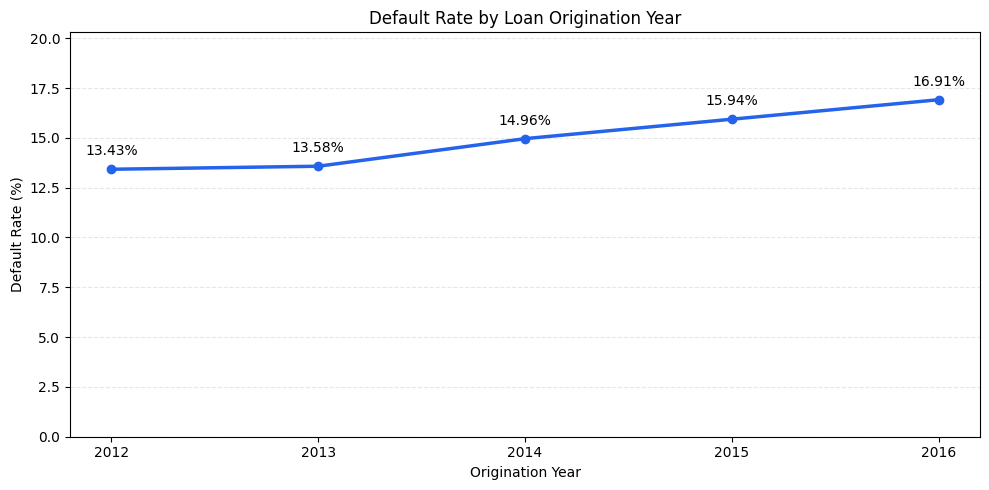

,Issue_year,Loans,Default_rate
0,2012,1527,0.134250
1,2013,1451,0.135768
2,2014,1524,0.149606
3,2015,1462,0.159371
4,2016,1478,0.169147


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def plot_default_rate_by_year(
    df,
    date_col="issue_d",
    status_col="loan_status",
    save_path="outputs/figures/default_rate_by_year.png"
):
    # Keep only resolved loan outcomes
    data = df.loc[
        df[status_col].isin(
            ["Fully Paid", "Charged Off", "Default"]
        ),
        [date_col, status_col]
    ].copy()

    # Convert origination dates
    data[date_col] = pd.to_datetime(
        data[date_col], errors="coerce"
    )

    # Remove invalid dates and apply study cutoff
    data = data.dropna(subset=[date_col])
    data = data[data[date_col].dt.year <= 2016]

    # Binary outcome: 1 = default, 0 = fully paid
    data["default_target"] = (
        data[status_col].isin(["Charged Off", "Default"])
    ).astype(int)

    # Aggregate automatically by origination year
    yearly = (
        data.groupby(data[date_col].dt.year)
        .agg(
            Loans=("default_target", "size"),
            Default_rate=("default_target", "mean")
        )
        .reset_index()
        .rename(columns={date_col: "Issue_year"})
    )

    if yearly.empty:
        raise ValueError("No eligible resolved loans found.")

    # Plot
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        yearly["Issue_year"],
        yearly["Default_rate"] * 100,
        marker="o",
        linewidth=2.5,
        color="#2563EB"
    )

    for _, row in yearly.iterrows():
        ax.annotate(
            f"{row['Default_rate']:.2%}",
            (row["Issue_year"], row["Default_rate"] * 100),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_title("Default Rate by Loan Origination Year")
    ax.set_xlabel("Origination Year")
    ax.set_ylabel("Default Rate (%)")
    ax.set_xticks(yearly["Issue_year"])
    ax.set_ylim(0, max(5, yearly["Default_rate"].max() * 120))
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()

    # Save figure
    path = Path(save_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return yearly


# RUN THE FUNCTION ON YOUR ACTUAL DATAFRAME
yearly_summary = plot_default_rate_by_year(raw)

display(yearly_summary)


### 2b. Data-cleaning figures and exploratory analysis of the portfolio
First draws the cleaning figures (loans left after each step, loan statuses kept vs dropped, feature coverage, censoring by year). Then describes who borrows and where defaults concentrate before any model is fitted: default rate by group with 95% intervals, tests reported with effect sizes, a hand-made risk rule checked against real defaults, interest charged vs defaults realised, and whether missingness is itself a signal. It also shows how much the label definition alone changes the default rate. Methods come from public LendingClub and Bondora notebooks (see `docs/eda.md`).

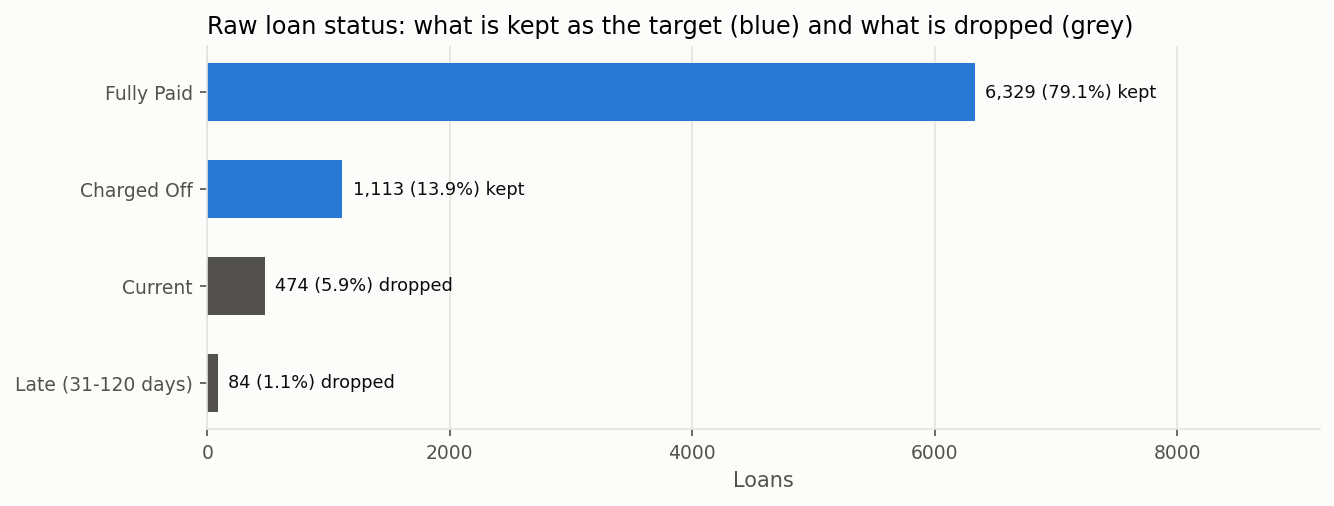

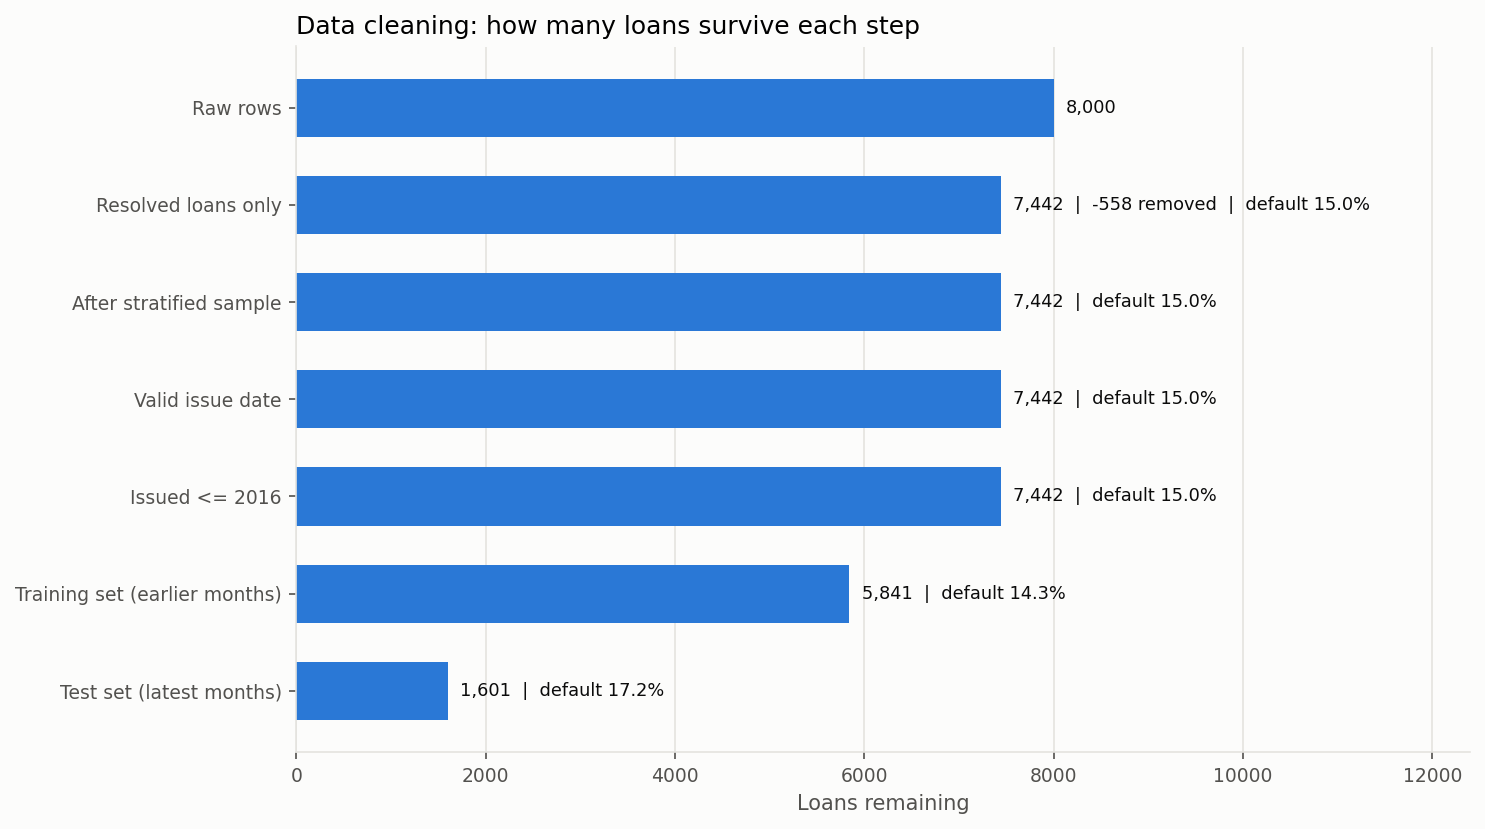

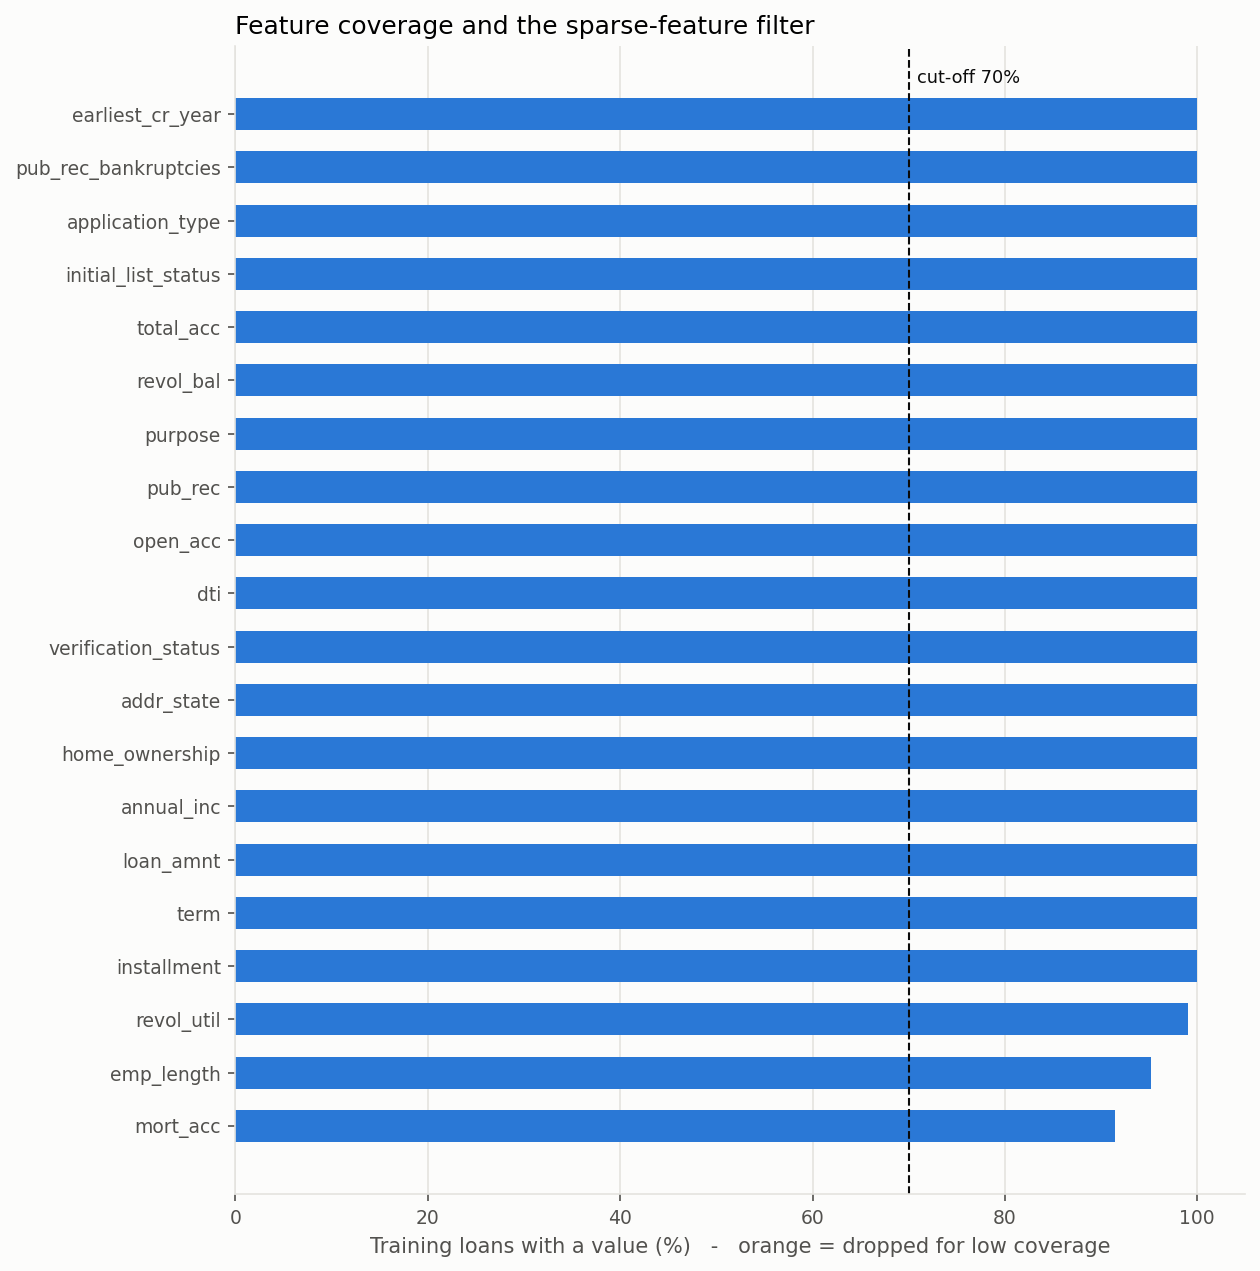

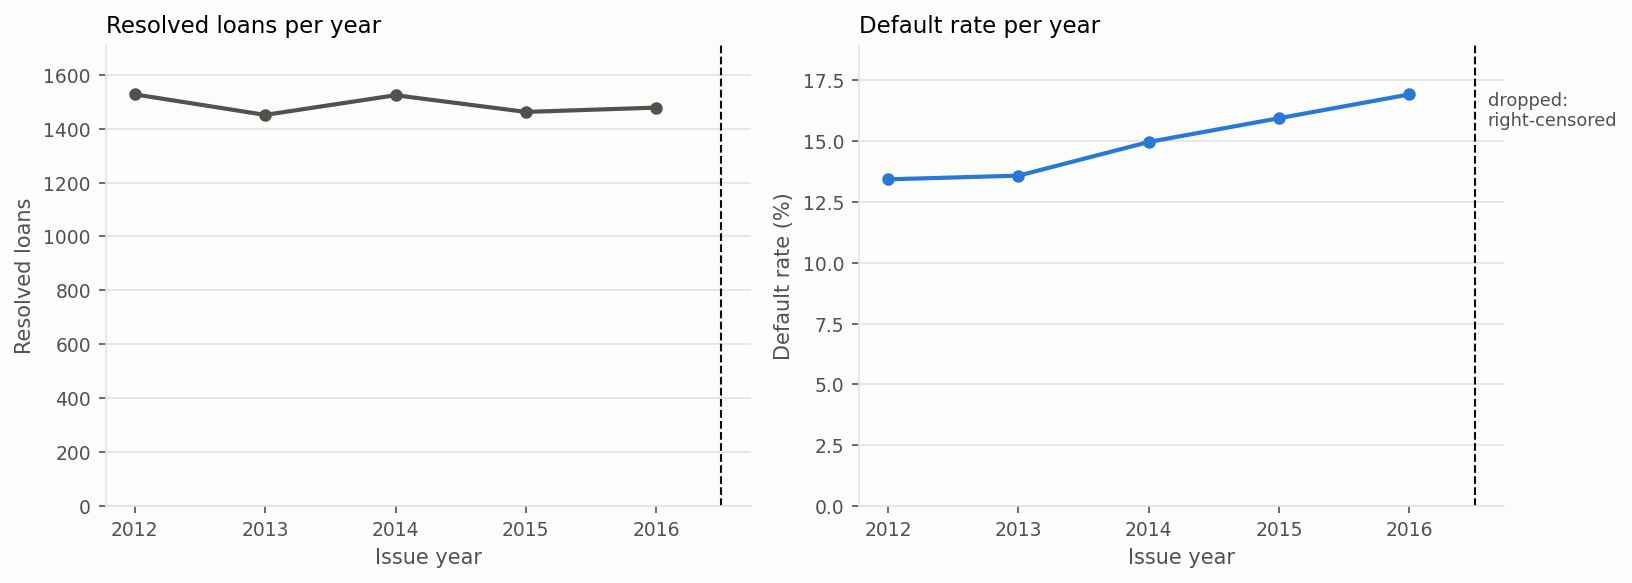


=== label_definitions ===


,Definition,Loans,Default_rate,Rule,Unresolved_loans_in_sample
0,This repo: resolved loans only,7442,0.150,Fully Paid = 0; Charged Off / Default = 1; eve...,0
1,"Notebook style: all loans, unresolved counted",8000,0.150,Current = good; Late / Grace Period / Charged ...,558
2,"Notebook style, Current excluded",7526,0.159,late loans still labelled bad before they resolve,84



=== hypothesis_tests ===


,Test,Variable,Statistic,p_value,Effect_size,Effect_measure,Effect_label,Mean_defaulted,Mean_paid
0,Welch t (defaulted - paid),int_rate,18.256,0.000,0.607,Cohen's d,medium,14.700,13.223
1,Welch t (defaulted - paid),loan_amnt,0.297,0.767,0.010,Cohen's d,negligible,17970.350,17872.413
2,Welch t (defaulted - paid),dti,8.546,0.000,0.281,Cohen's d,small,19.631,17.594
3,Welch t (defaulted - paid),annual_inc,-11.700,0.000,-0.323,Cohen's d,small,57760.649,70314.197
4,Welch t (defaulted - paid),revol_util,10.143,0.000,0.329,Cohen's d,small,56.460,49.184
5,Welch t (defaulted - paid),fico_score,-16.797,0.000,-0.496,Cohen's d,small,690.877,707.108
6,Chi-square (default vs group),term_months,39.014,0.000,0.072,Cramer's V,negligible,NaN,NaN
7,Chi-square (default vs group),purpose,8.929,0.063,0.035,Cramer's V,negligible,NaN,NaN
8,Chi-square (default vs group),grade,359.795,0.000,0.220,Cramer's V,small,NaN,NaN
9,Chi-square (default vs group),home_ownership,8.655,0.034,0.034,Cramer's V,negligible,NaN,NaN



=== risk_rule_validation ===


,Rule,Flagged_share,Default_rate_flagged,Default_rate_not_flagged,Lift,Precision,Recall,AUC_of_flag,Base_default_rate
0,Loan > 35% of income AND employed <= 1y,0.059,0.165,0.149,1.104,0.165,0.065,0.504,0.15
1,Loan > 35% of income,0.381,0.181,0.130,1.209,0.181,0.460,0.547,0.15
2,Employed <= 1y,0.164,0.130,0.153,0.868,0.130,0.142,0.487,0.15
3,Instalment burden > 25% of income,0.120,0.198,0.143,1.325,0.198,0.159,0.523,0.15


... (2 outputs left out)


=== missingness_informativeness ===


,Feature,Missing_share,Default_rate_missing,Default_rate_observed,Gap_pct_points,Missing_ci95_low,Missing_ci95_high
0,emp_title,0.200,0.172,0.144,2.839,0.154,0.192
1,mort_acc,0.084,0.135,0.151,-1.631,0.110,0.164
2,revol_util,0.010,0.141,0.150,-0.880,0.078,0.240
3,title,0.334,0.146,0.151,-0.505,0.133,0.161
4,emp_length,0.047,0.151,0.150,0.106,0.117,0.192



=== outlier_summary ===


,Feature,Outside_1.5_IQR_share,Above_p99.9_share,Max,Median,Max_over_median,Skewness
0,revol_bal,0.077,0.001,702044.580,10898.322,64.418,7.334
1,annual_inc,0.035,0.001,667504.606,59847.487,11.153,2.347
2,int_rate,0.008,0.001,23.439,13.400,1.749,0.019
3,revol_util,0.004,0.001,120.000,50.263,2.387,0.082
4,fico_score,0.003,0.001,847.000,702.000,1.207,0.570
5,dti,0.003,0.001,45.000,17.827,2.524,0.066
6,installment,0.000,0.001,1274.816,535.741,2.380,0.192
7,loan_amnt,0.000,0.000,35000.000,17500.000,2.000,0.009
8,open_acc,0.000,0.000,29.000,16.000,1.812,-0.002
9,total_acc,0.000,0.000,59.000,31.000,1.903,0.007


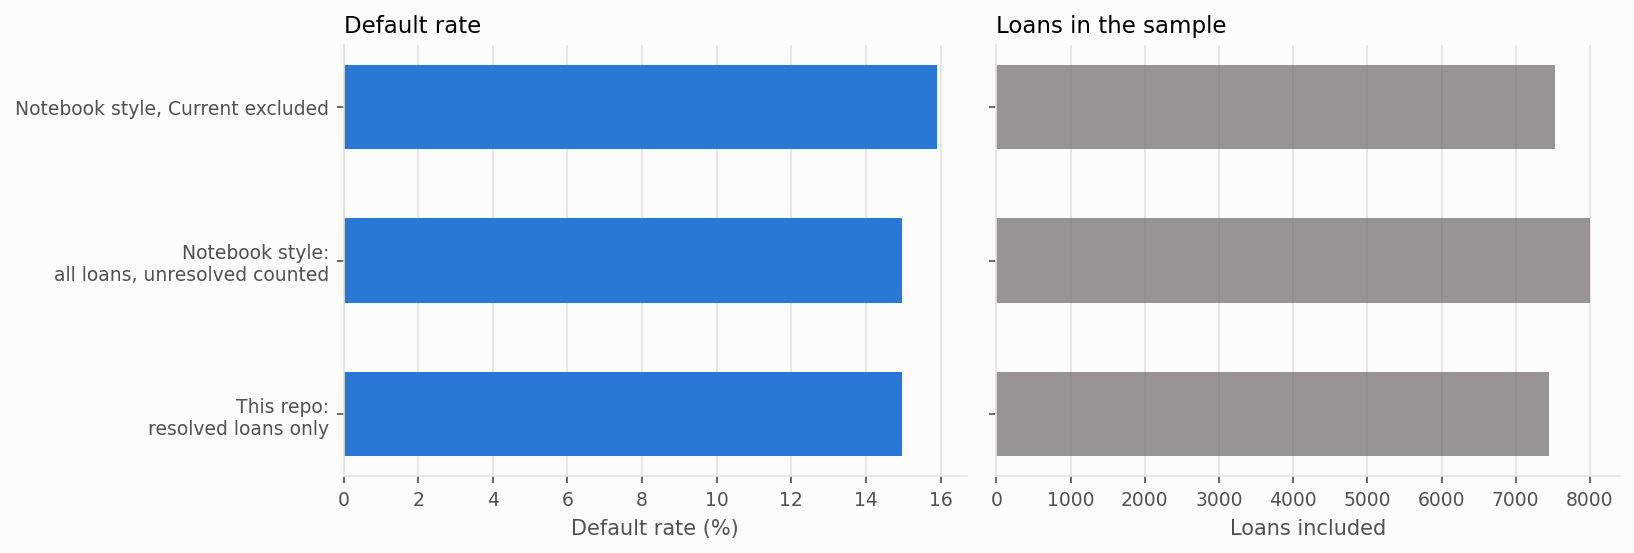

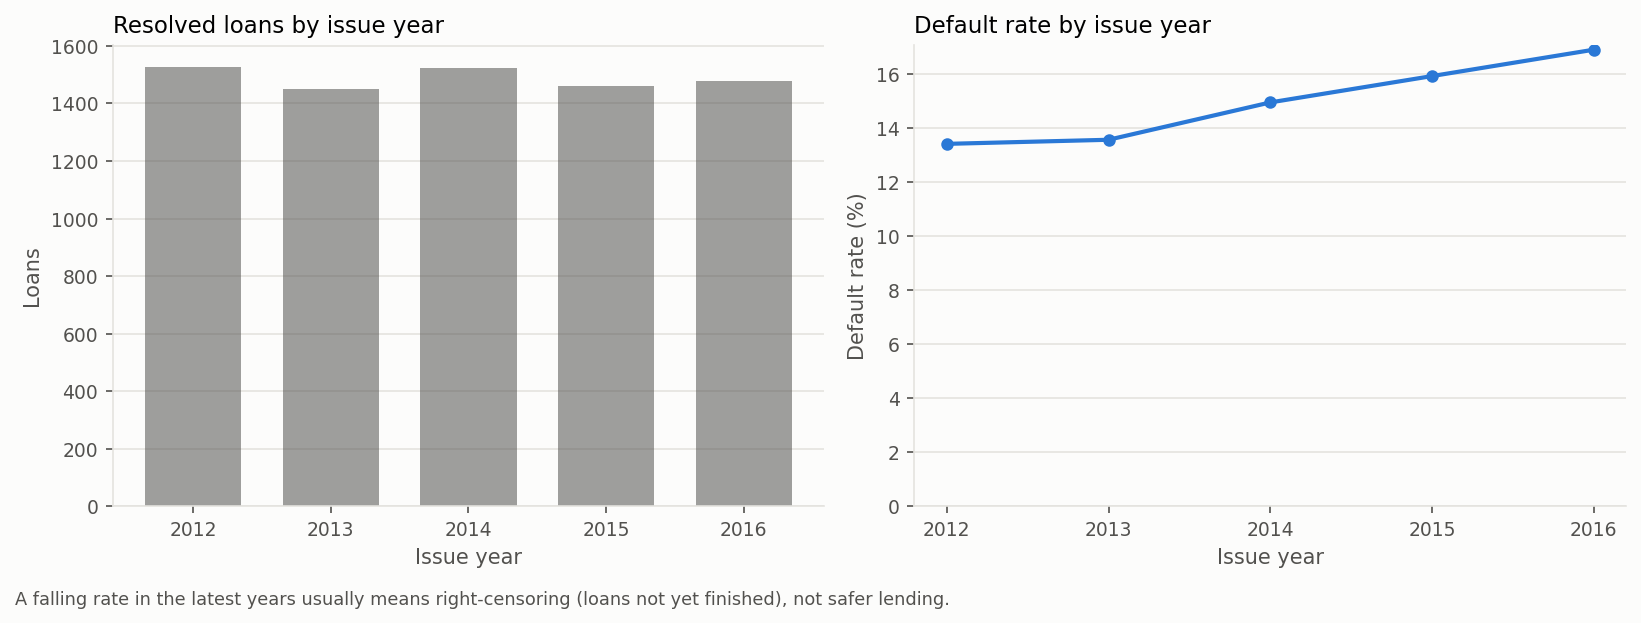

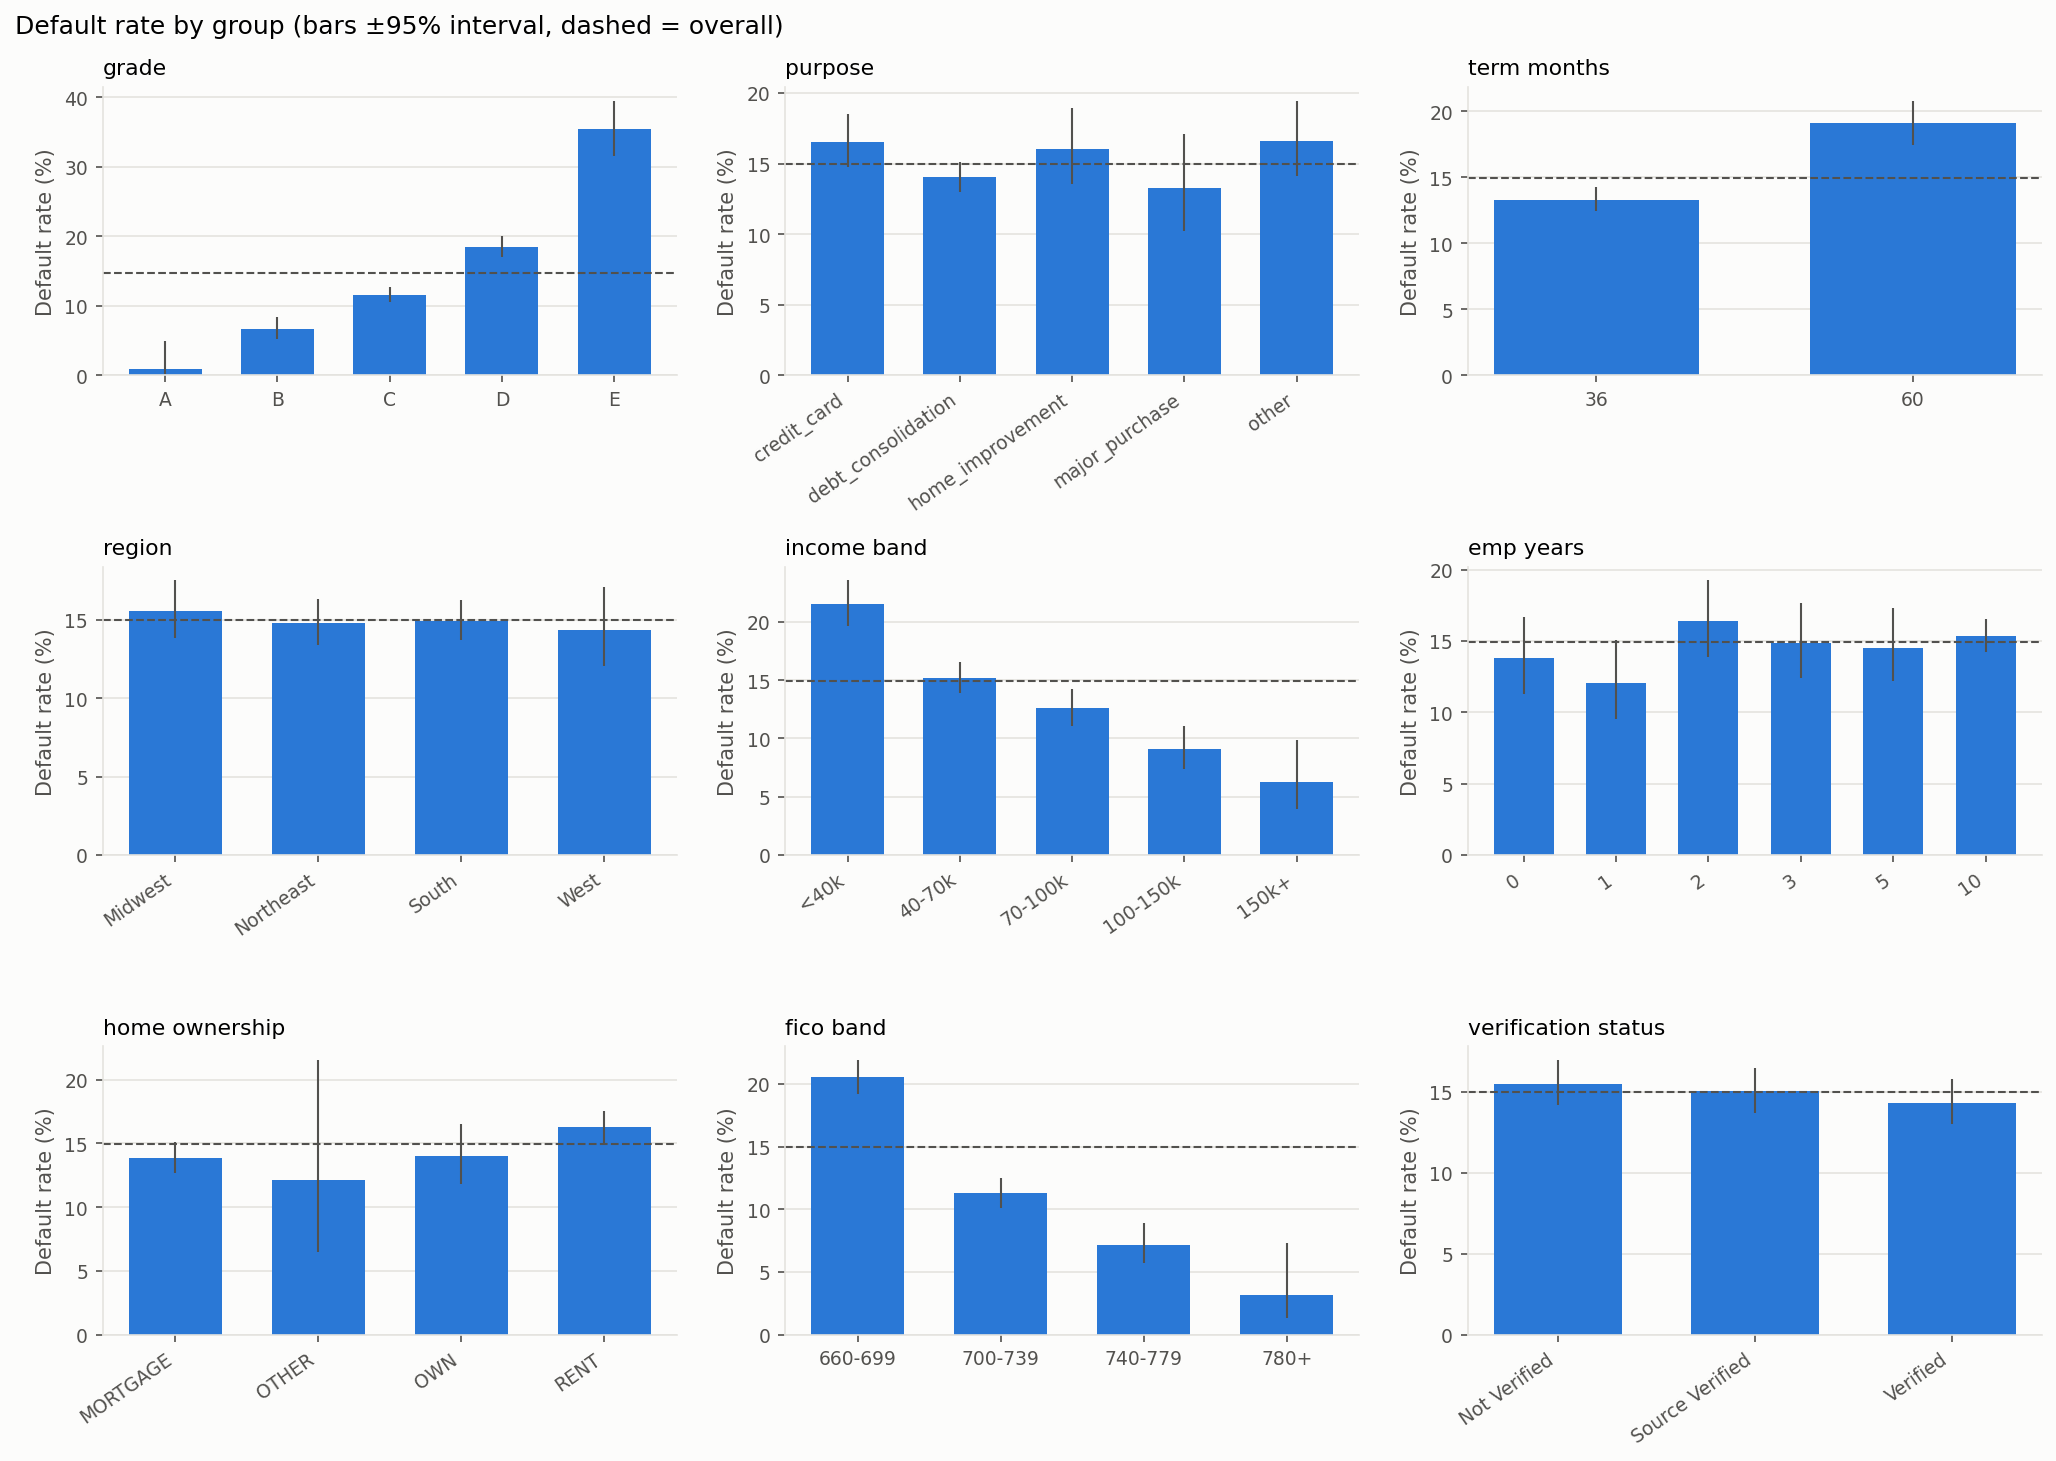

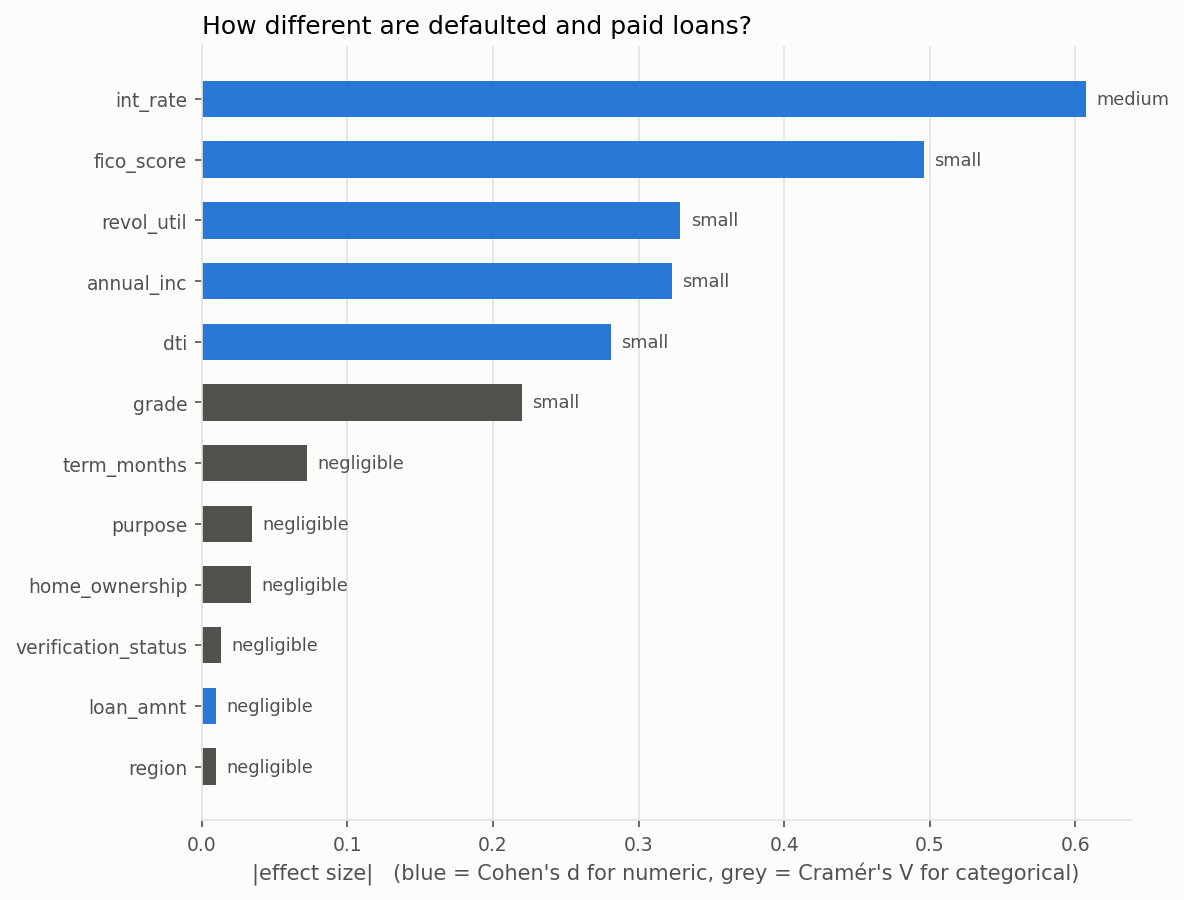

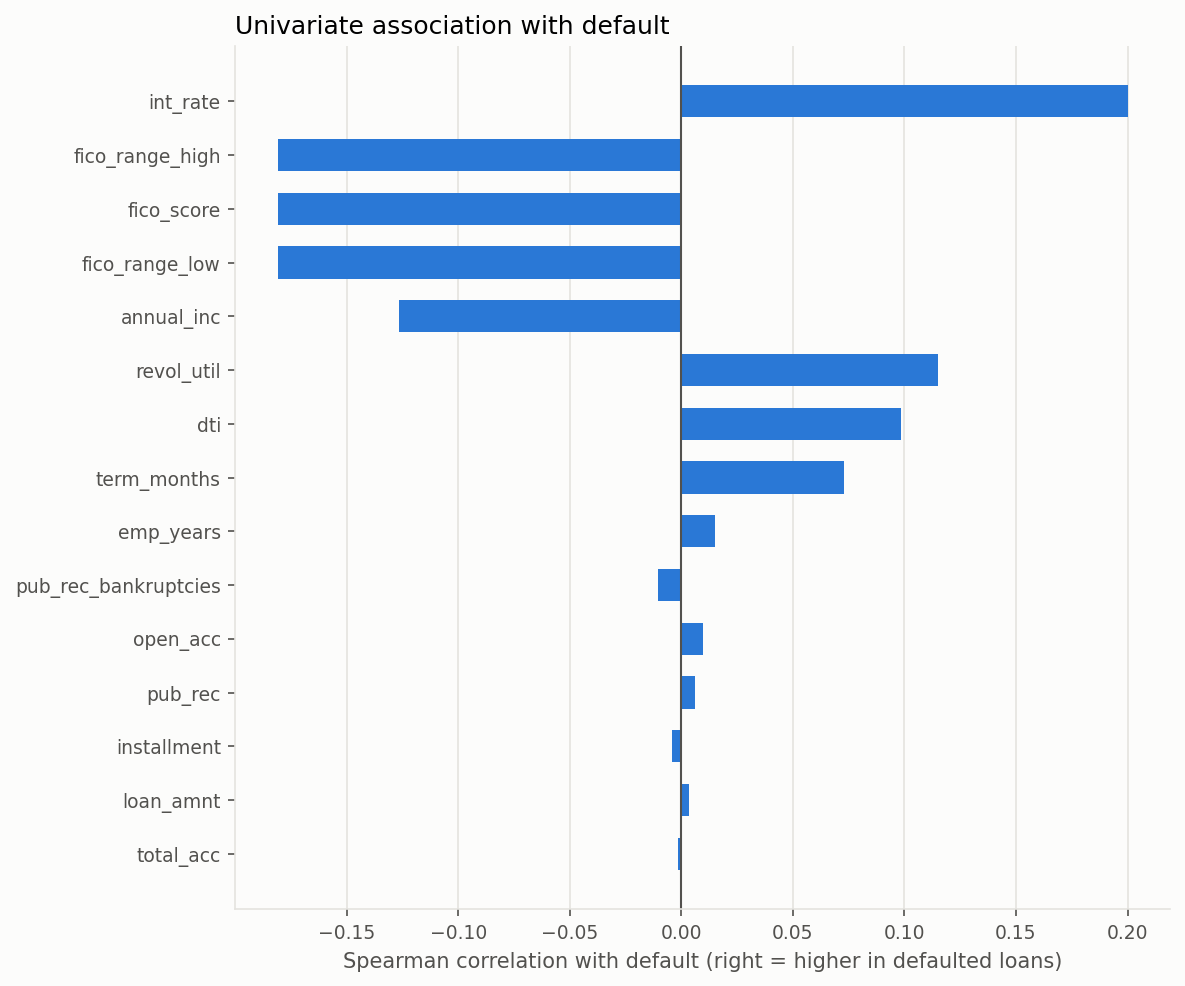

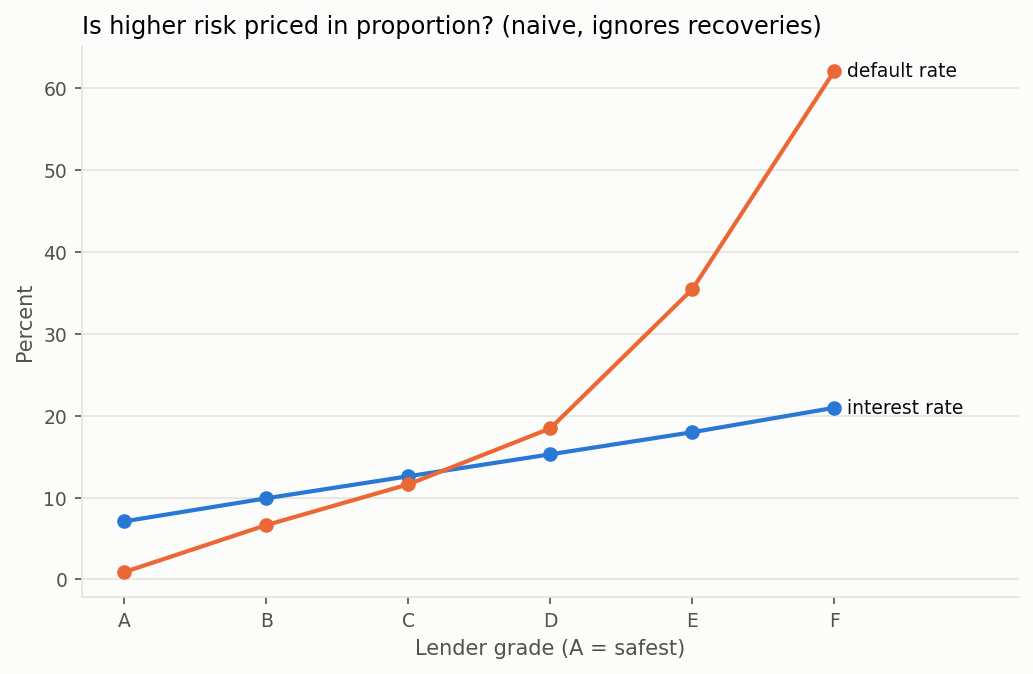

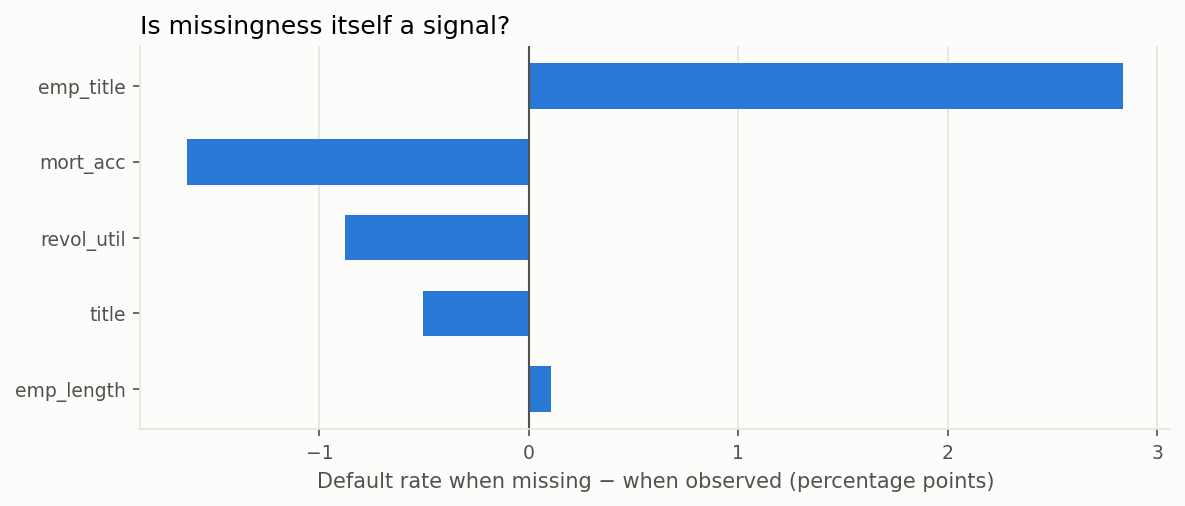

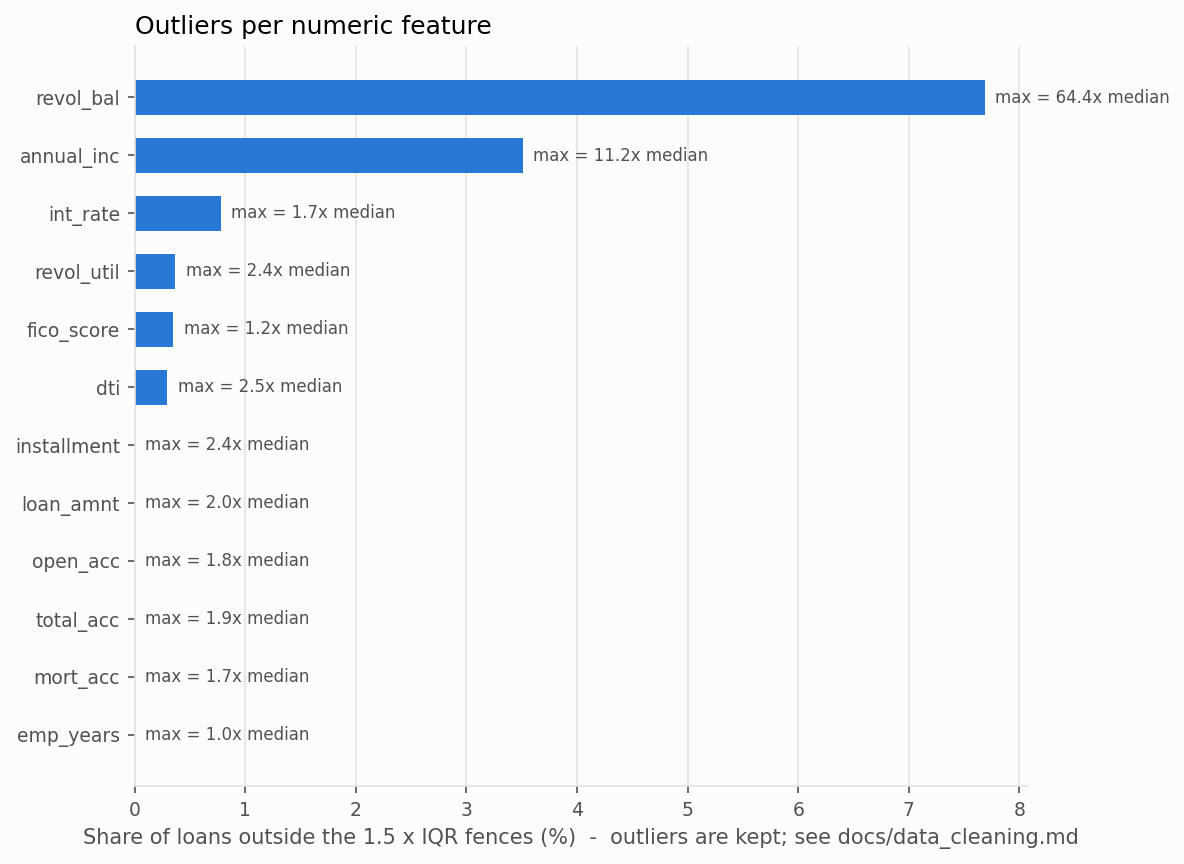

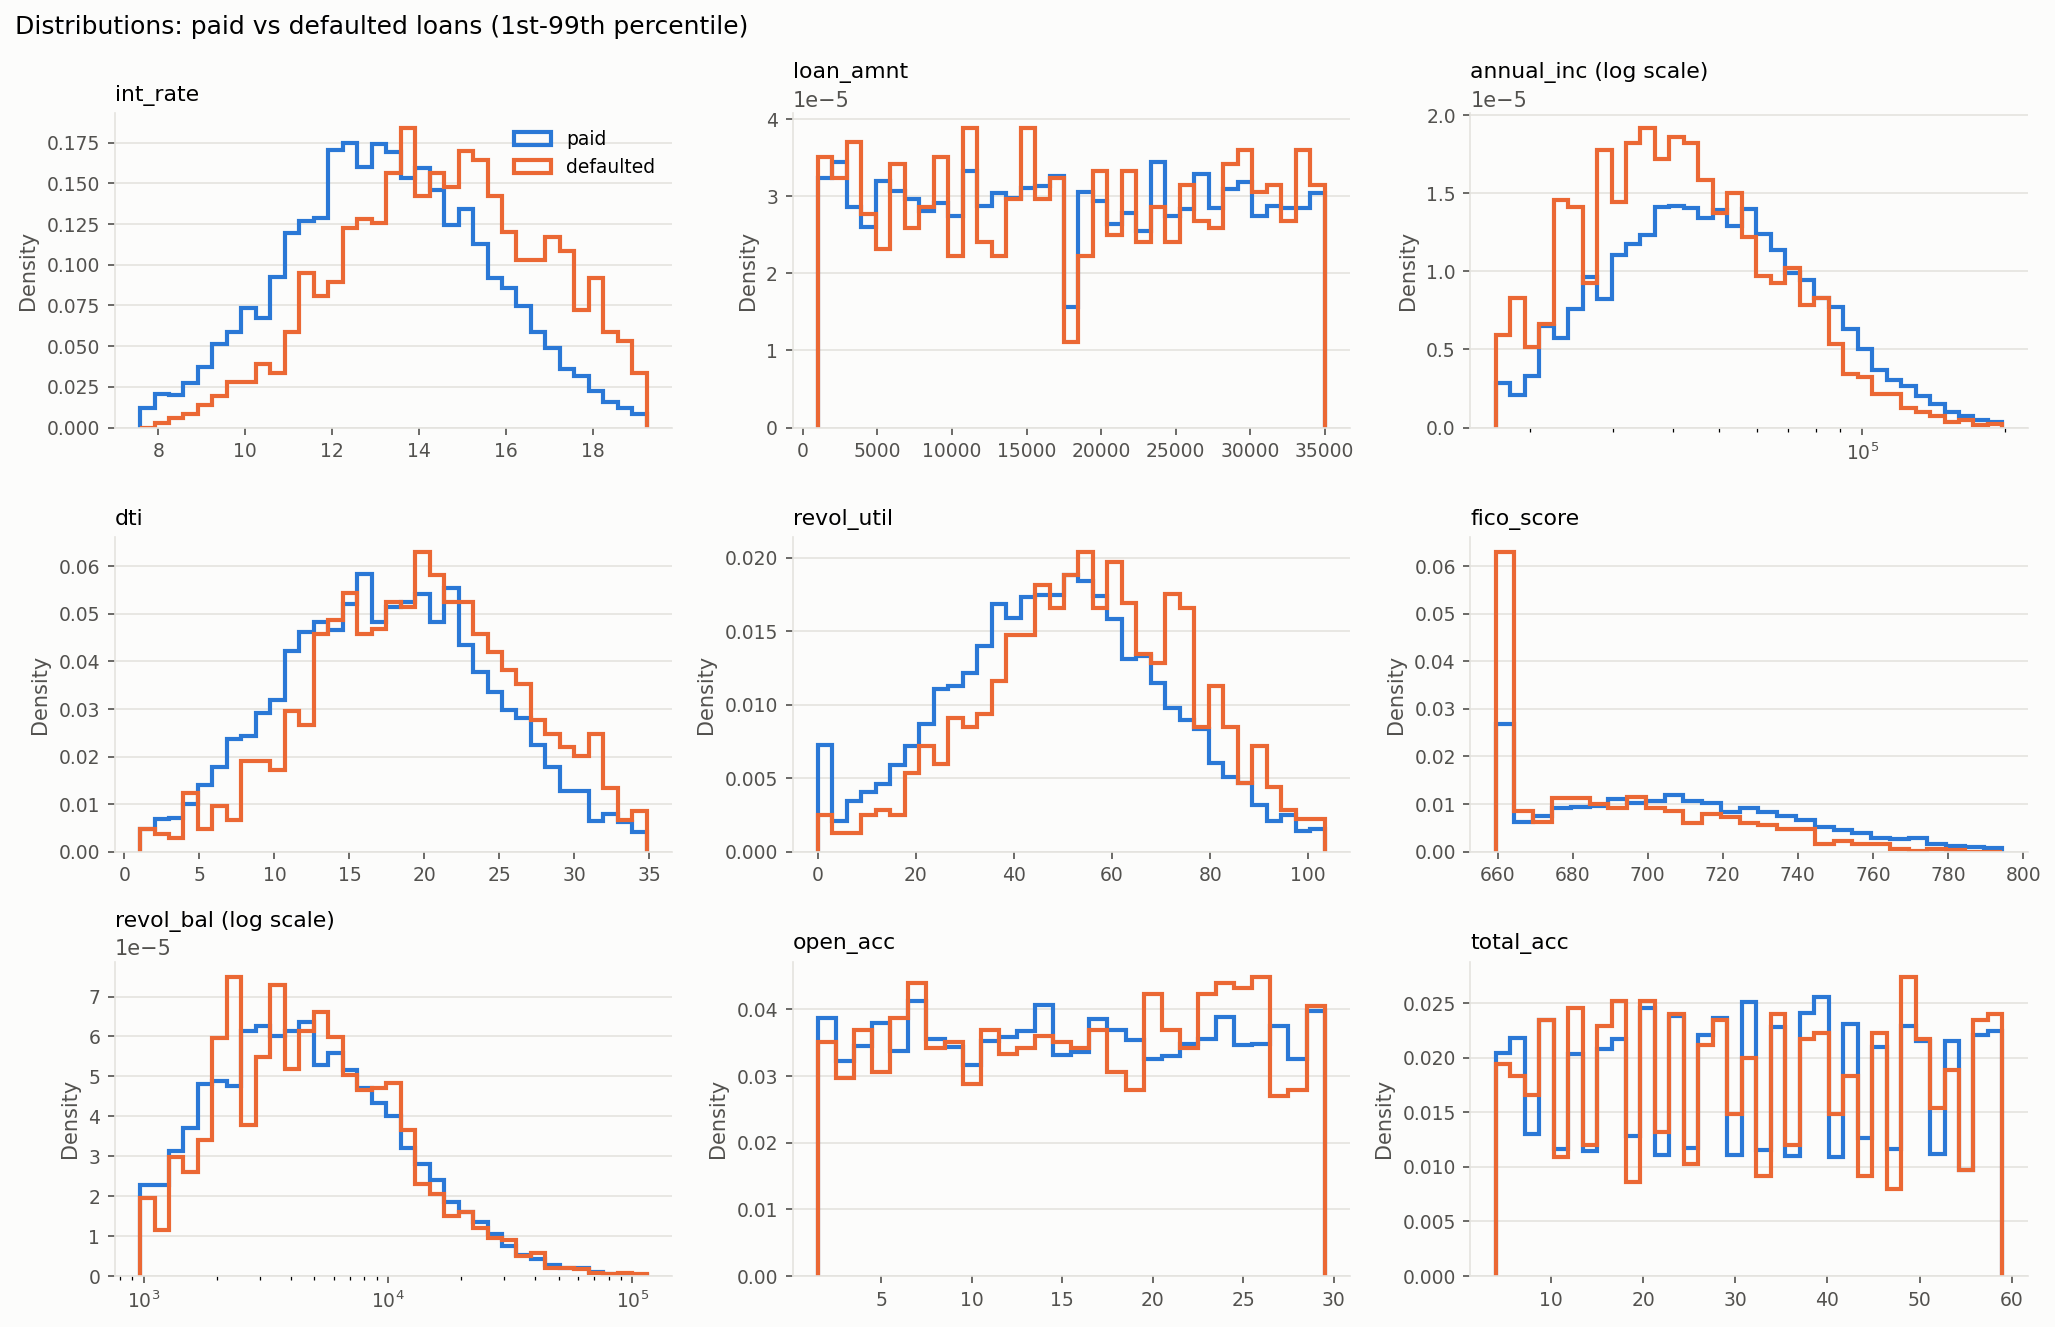

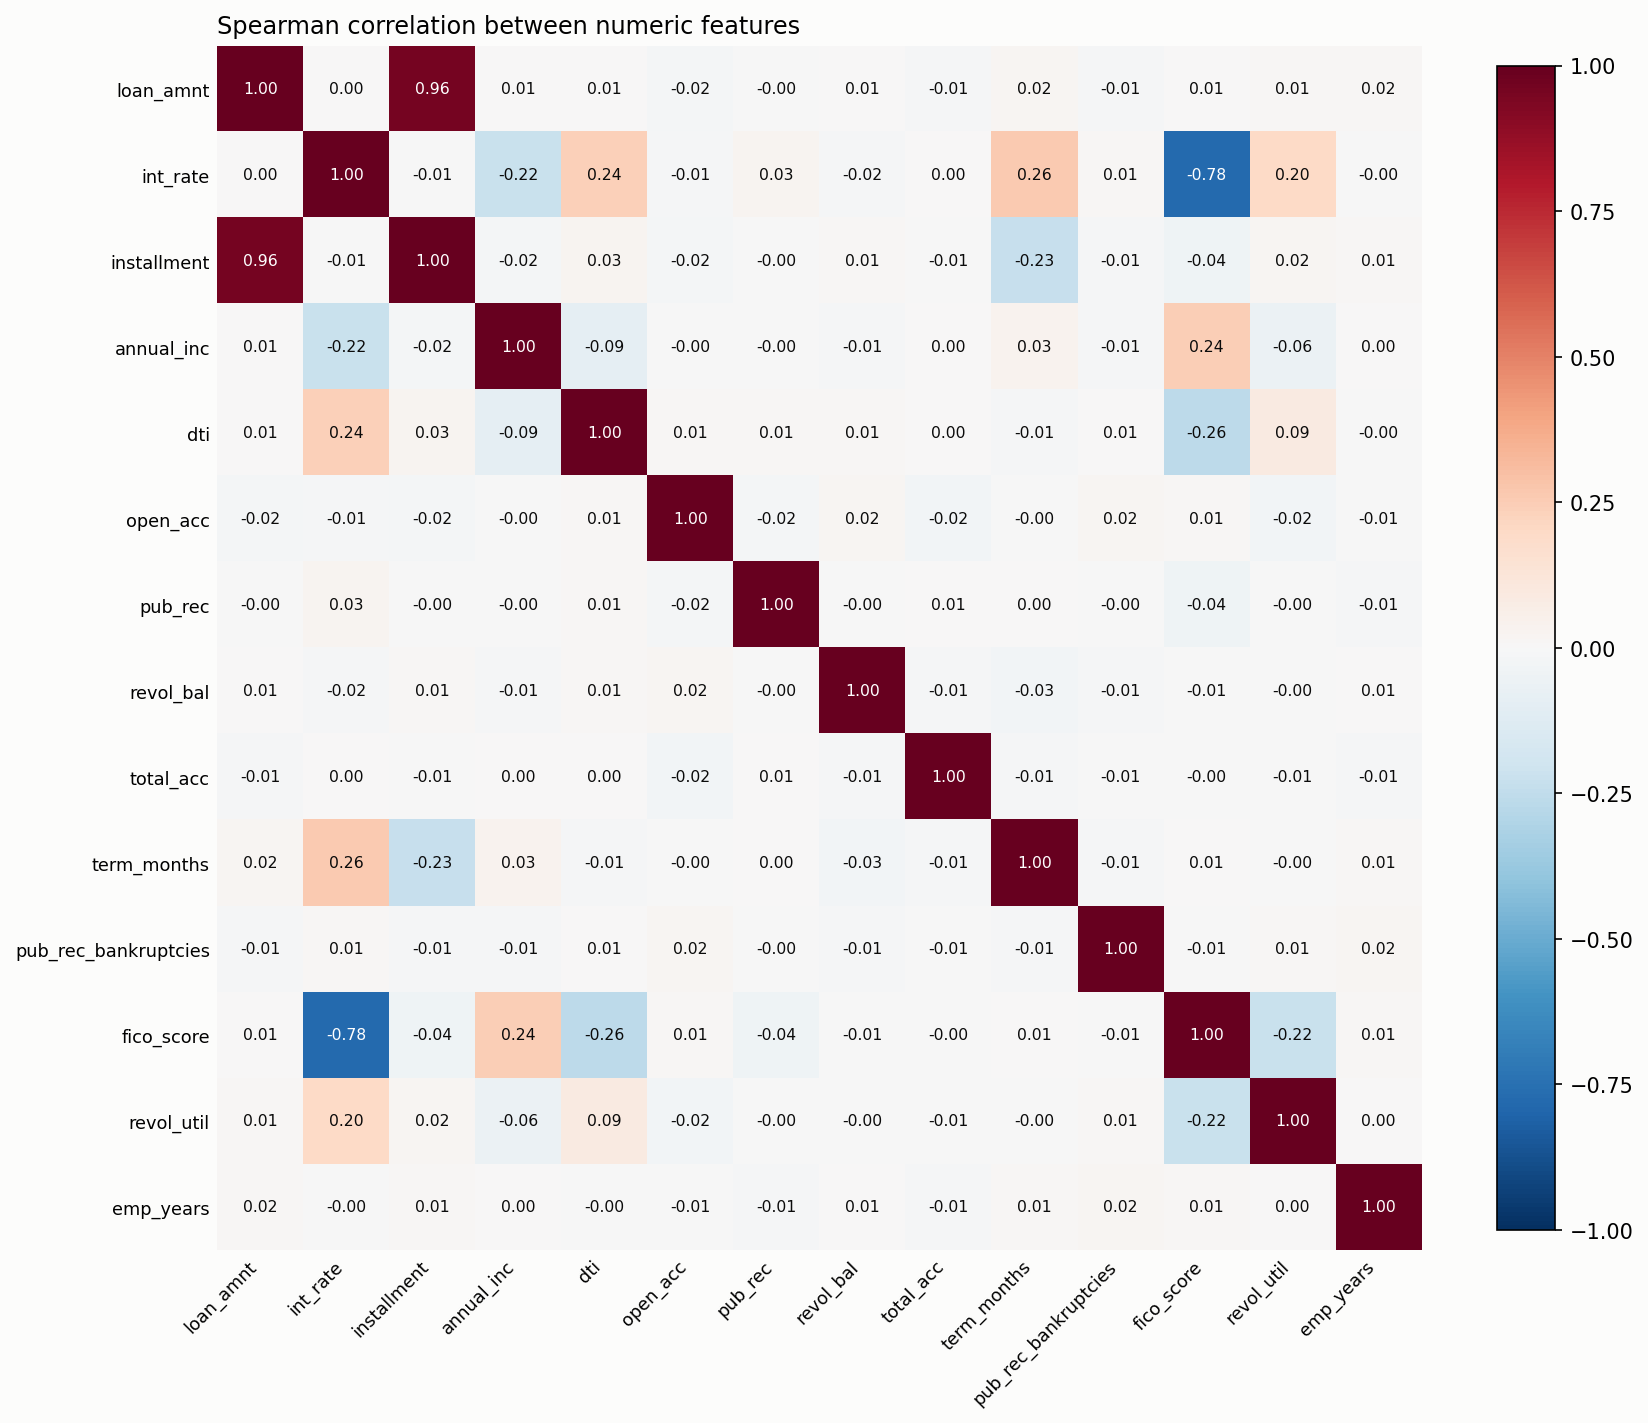

In [ ]:
from src.eda import eda_report
from src.visualization import save_eda_figures

from src.data_quality import data_quality_report
from src.visualization import save_data_quality_figures
dq = data_quality_report(raw, cfg, verbose=False)
dq_paths = save_data_quality_figures(dq, ROOT / "outputs" / "figures" / "data_quality", cfg.max_issue_year, cfg.min_feature_coverage)
from IPython.display import Image as _Img
for p in dq_paths:
    display(_Img(filename=str(p), width=800))

eda = eda_report(raw, cfg, verbose=False)
for name in ("label_definitions", "hypothesis_tests", "risk_rule_validation", "pricing_vs_realised_risk", "missingness_informativeness", "outlier_summary"):
    print(f"\n=== {name} ===")
    display(eda[name].round(3))
eda_paths = save_eda_figures(eda, ROOT / "outputs" / "figures" / "eda")
from IPython.display import Image
for p in eda_paths:
    display(Image(filename=str(p), width=800))

### 3. Seed grid
Fits every model for every seed on a different training subsample, scores the same test rows and computes one global importance vector per fit. Then summarises mean performance, calibration, generalization gap and explanation stability per model, and the structural size of each model.

In [ ]:
grid = run_seed_grid(splits, cfg, verbose=False)
summary = summarise(grid)
display(summary.round(4))
display(grid["complexity"])

,roc_auc,pr_auc,brier,ece,generalization_gap,seed_std_pr_auc,explanation_stability
Model,,,,,,,
Logistic Regression,0.6463,0.2791,0.1372,0.0315,0.0643,0.0063,0.7350
Random Forest,0.6495,0.2942,0.1366,0.0248,0.2512,0.0066,0.8223
XGBoost,0.6152,0.2611,0.1427,0.0626,0.3760,0.0110,0.7841
DNN,0.6436,0.2702,0.1377,0.0292,0.0794,0.0092,0.7301
KAN,0.6359,0.2713,0.1379,0.0271,0.0770,0.0075,0.7378


,Structural_Units,Structural_Measure,Train_Time_Seconds,Predict_Time_Seconds
Model,,,,
Logistic Regression,43,coefficients + intercept,0.394569,0.092284
Random Forest,38306,total tree nodes,1.739428,0.115412
XGBoost,9046,total boosted-tree nodes,0.441656,0.028799
DNN,15873,trainable parameters,3.691526,0.018594
KAN,3096,trainable parameters,4.817855,0.037181


### 4. H1 - performance equivalence
For every model pair, bootstraps the PR-AUC difference (resampling seeds and test rows) and compares its 90% interval with the equivalence margin. Verdicts: *equivalent*, *different* or *inconclusive* (data cannot tell).

,Model_A,Model_B,PR_AUC_diff,ci90_low,ci90_high,p_value,Verdict,Equivalent,Margin,p_holm
0,Logistic Regression,Random Forest,-0.0151,-0.0381,0.0059,0.2178,inconclusive,False,0.01,1.0000
1,Logistic Regression,XGBoost,0.0181,-0.0067,0.0458,0.2970,inconclusive,False,0.01,1.0000
2,Logistic Regression,DNN,0.0089,-0.0040,0.0221,0.2574,inconclusive,False,0.01,1.0000
3,Logistic Regression,KAN,0.0078,-0.0055,0.0213,0.3762,inconclusive,False,0.01,1.0000
4,Random Forest,XGBoost,0.0332,0.0139,0.0567,0.0396,different,False,0.01,0.3960
5,Random Forest,DNN,0.0241,0.0017,0.0430,0.0990,inconclusive,False,0.01,0.7921
6,Random Forest,KAN,0.0230,0.0012,0.0438,0.0594,inconclusive,False,0.01,0.5347
7,XGBoost,DNN,-0.0091,-0.0338,0.0136,0.5149,inconclusive,False,0.01,1.0000
8,XGBoost,KAN,-0.0102,-0.0355,0.0152,0.4752,inconclusive,False,0.01,1.0000
9,DNN,KAN,-0.0011,-0.0160,0.0145,0.8119,inconclusive,False,0.01,1.0000


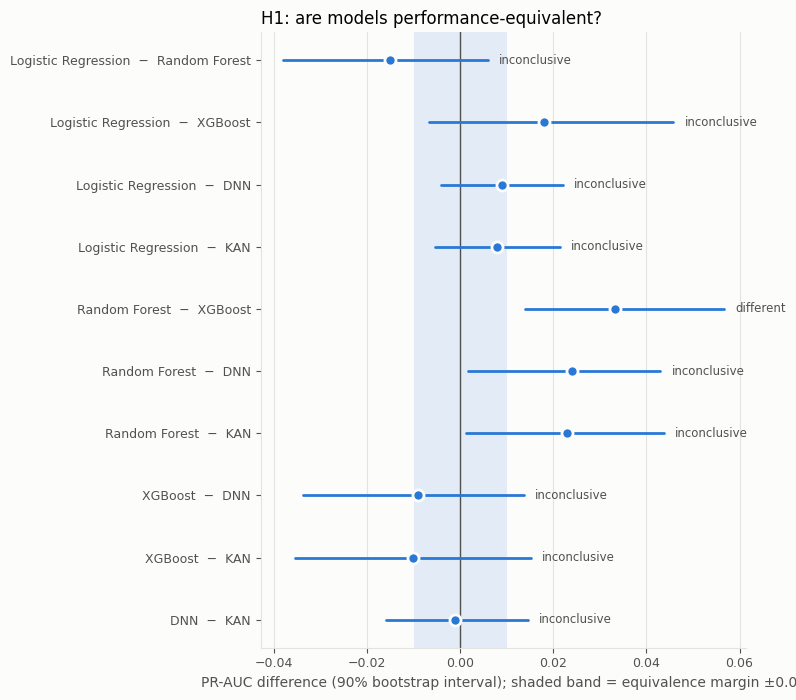

In [ ]:
tests = run_hypothesis_tests(grid, cfg, verbose=False)
display(tests["h1"].round(4))

from src.visualization import plot_equivalence_forest
plot_equivalence_forest(tests["h1"]); plt.show()

### 5. H2 and H3 - explanations
H2 asks whether two models' explanations (top-k membership and ranking) differ more than the same model's explanations differ across seeds. H3 flags pairs that are performance-equivalent but explained differently.

,Model_A,Model_B,kind,d_cross,d_within,theta,ci90_low,ci90_high,p_value,p_holm,Supported
0,Logistic Regression,Random Forest,membership,0.4159,0.3492,0.0667,-0.1250,0.2262,0.2881,1.0000,False
1,Logistic Regression,Random Forest,ranking,0.4230,0.2213,0.2017,0.1104,0.3047,0.0034,0.0339,True
2,Logistic Regression,XGBoost,membership,0.4256,0.4643,-0.0387,-0.1468,0.1262,0.7197,1.0000,False
3,Logistic Regression,XGBoost,ranking,0.4905,0.2404,0.2501,0.1530,0.3694,0.0035,0.0339,True
4,Logistic Regression,DNN,membership,0.3899,0.3492,0.0407,-0.1170,0.1857,0.3860,1.0000,False
5,Logistic Regression,DNN,ranking,0.4572,0.2675,0.1898,0.0908,0.2947,0.0035,0.0339,True
6,Logistic Regression,KAN,membership,0.4368,0.4722,-0.0355,-0.1369,0.0814,0.7079,1.0000,False
7,Logistic Regression,KAN,ranking,0.3919,0.2636,0.1283,0.0672,0.1900,0.0103,0.0339,True
8,Random Forest,XGBoost,membership,0.2679,0.2817,-0.0139,-0.1083,0.1071,0.5952,1.0000,False
9,Random Forest,XGBoost,ranking,0.2241,0.1968,0.0273,-0.0364,0.0945,0.3322,0.6644,False


,Model_A,Model_B,H1_equivalent,H2_membership,H2_ranking,H3_supported
0,Logistic Regression,Random Forest,False,False,True,False
1,Logistic Regression,XGBoost,False,False,True,False
2,Logistic Regression,DNN,False,False,True,False
3,Logistic Regression,KAN,False,False,True,False
4,Random Forest,XGBoost,False,False,False,False
5,Random Forest,DNN,False,False,True,False
6,Random Forest,KAN,False,False,True,False
7,XGBoost,DNN,False,False,True,False
8,XGBoost,KAN,False,False,True,False
9,DNN,KAN,False,False,False,False


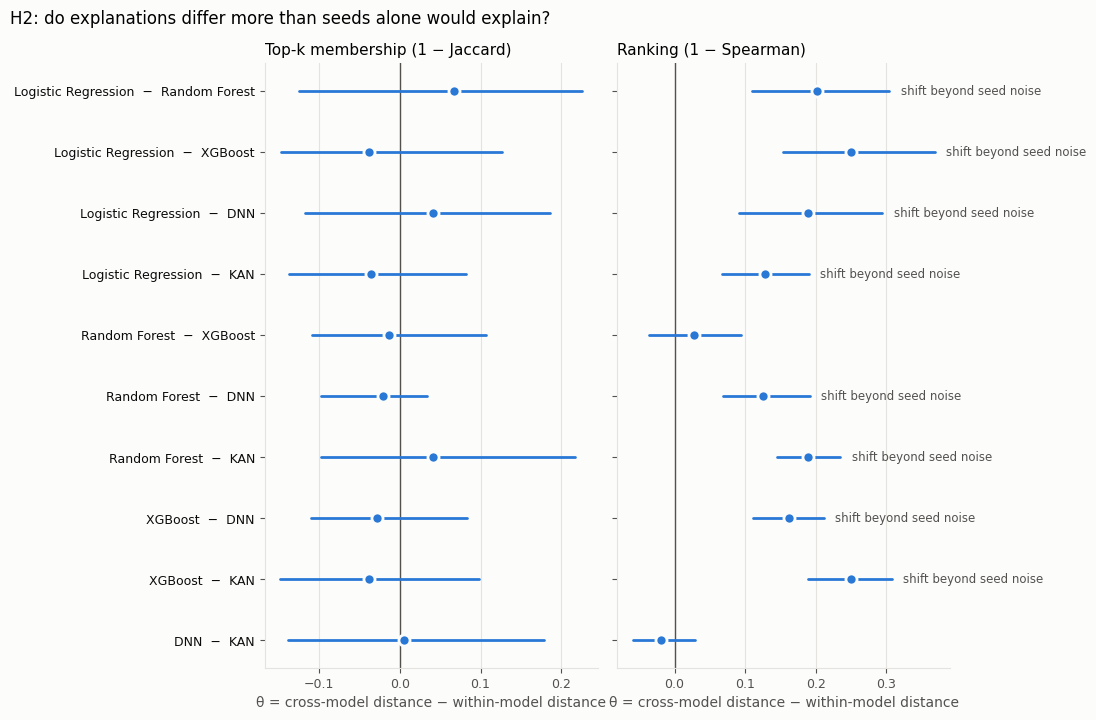

In [ ]:
display(tests["h2"].round(4))
display(tests["h3"])

from src.visualization import plot_explanation_shift
plot_explanation_shift(tests["h2"]); plt.show()

### 6. Calibration
Compares Brier score and ECE before and after isotonic recalibration, and draws the reliability curves (closer to the diagonal is better).

,Model,Method,ROC_AUC,Brier,ECE
0,Logistic Regression,none,0.6553,0.1361,0.0283
1,Logistic Regression,isotonic,0.6491,0.1373,0.0298
2,Random Forest,none,0.6532,0.1358,0.0226
3,Random Forest,isotonic,0.6512,0.1360,0.0298
4,XGBoost,none,0.6196,0.1420,0.0594
5,XGBoost,isotonic,0.6318,0.1387,0.0317
6,DNN,none,0.6585,0.1364,0.0298
7,DNN,isotonic,0.6472,0.1377,0.0315
8,KAN,none,0.6441,0.1367,0.0194
9,KAN,isotonic,0.6426,0.1385,0.0311


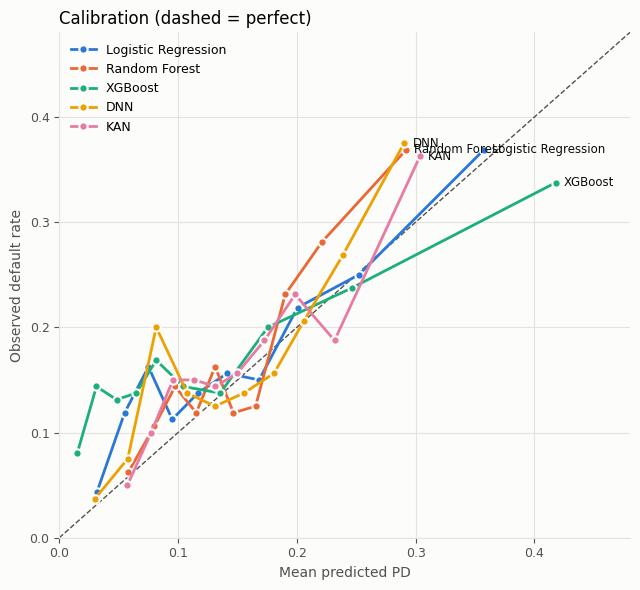

In [ ]:
from src.calibration import compare_calibration
from src.visualization import plot_calibration

sub = X_train.sample(min(len(X_train), 20_000), random_state=0)
calib = compare_calibration(grid["fitted"], sub, y_train.loc[sub.index], X_test, y_test, methods=("isotonic",))
display(calib.round(4))
plot_calibration(grid["probs"], grid["y_test"]); plt.show()

### 7. Robustness
PSI measures how far each feature drifted between train and test; the stress table shows mean predicted PD under worse income / DTI / utilisation (it should rise); the backtest trains on earlier years and tests on each later year.

In [ ]:
from src.robustness import feature_psi, stress_test

display(feature_psi(X_train, X_test).head(10).round(4))

stress = {}
for name, pipe in grid["fitted"].items():
    stress[name] = stress_test(lambda d, p=pipe: p.predict_proba(d)[:, 1], X_test.head(2_000)) \
        .set_index("Scenario")["Average_PD"]
display(pd.DataFrame(stress).round(4))

,Feature,PSI
0,revol_bal,0.0190
1,total_acc,0.0107
2,earliest_cr_year,0.0084
3,mort_acc,0.0058
4,fico_score,0.0056
5,open_acc,0.0055
6,earliest_cr_month,0.0047
7,emp_length,0.0042
8,revol_util,0.0040
9,pub_rec,0.0036


,Logistic Regression,Random Forest,XGBoost,DNN,KAN
Scenario,,,,,
Baseline,0.1493,0.1497,0.1320,0.1478,0.1531
Moderate stress,0.1698,0.1651,0.1498,0.1626,0.1755
Severe stress,0.1910,0.1787,0.1664,0.1763,0.1971


In [ ]:
from src.robustness import chronological_backtest
from src.models import make_pipeline
from src.preprocessing import prepare_frame

# The backtest needs the dated frame (the split above removed the dates), so rebuild it.
frame = prepare_frame(raw, sample_size=None if USE_SYNTHETIC else cfg.sample_size,
                      max_issue_year=cfg.max_issue_year, drop_lender_assigned=cfg.drop_lender_assigned)
bt = chronological_backtest(lambda X, y: make_pipeline("Logistic Regression", X), frame,
                            first_test_year=2014, min_train=500 if USE_SYNTHETIC else 3_000,
                            min_test=200 if USE_SYNTHETIC else 500)
display(bt.round(4))

,Test_Year,Observations,Observed_Default_Rate,Average_Predicted_PD,ROC_AUC,PR_AUC,Brier
0,2014,1524,0.1496,0.1308,0.6712,0.2650,0.1216
1,2015,1462,0.1594,0.1413,0.6782,0.2795,0.1269
2,2016,1478,0.1691,0.1448,0.6470,0.2726,0.1356


### 8. With vs without the lender's own score
Runs the whole experiment twice - without and with `int_rate` / `sub_grade` - to show how much of each model's performance is just LendingClub's own underwriting score.

In [ ]:
if COMPARE_FEATURE_SETS:
    both = run_feature_set_comparison(cfg, synthetic=USE_SYNTHETIC, verbose=False)
    display(both["comparison"][["roc_auc", "pr_auc", "brier", "ece", "explanation_stability"]].round(4))
else:
    print("Skipped (COMPARE_FEATURE_SETS = False).")

roc_auc  pr_auc   brier     ece  explanation_stability
Feature_set       Model                                                                      
no_lender_score   Logistic Regression   0.6463  0.2791  0.1372  0.0315                 0.7350
                  Random Forest         0.6495  0.2942  0.1366  0.0248                 0.8223
                  XGBoost               0.6152  0.2611  0.1427  0.0626                 0.7841
                  DNN                   0.6436  0.2702  0.1377  0.0292                 0.7239
                  KAN                   0.6359  0.2713  0.1379  0.0271                 0.7378
with_lender_score Logistic Regression   0.6498  0.2986  0.1362  0.0326                 0.7635
                  Random Forest         0.6570  0.3137  0.1352  0.0248                 0.8419
                  XGBoost               0.6178  0.2594  0.1435  0.0649                 0.7259
                  DNN                   0.6568  0.2989  0.1361  0.0219                 0.7255
                  KAN                   0.6546  0.3073  0.1351  0.0250                 0.7203

### 9. Scorecard and trade-offs
Turns the measured results into relative 0-100 scores per model (radar chart), plots performance against complexity, and lists Pareto-dominated models. Keep the raw tables above next to these scores: they only rank the compared models against each other.

,Performance,Calibration,Generalization,Efficiency,Robustness,Explanation_Stability
Model,,,,,,
Logistic Regression,72.5,87.3,100.0,88.6,100.0,5.3
Random Forest,100.0,100.0,40.0,24.4,93.2,100.0
XGBoost,0.0,0.0,0.0,58.7,0.0,58.6
DNN,55.1,84.7,95.2,30.4,38.7,0.0
KAN,45.6,84.8,95.9,30.6,75.0,8.4


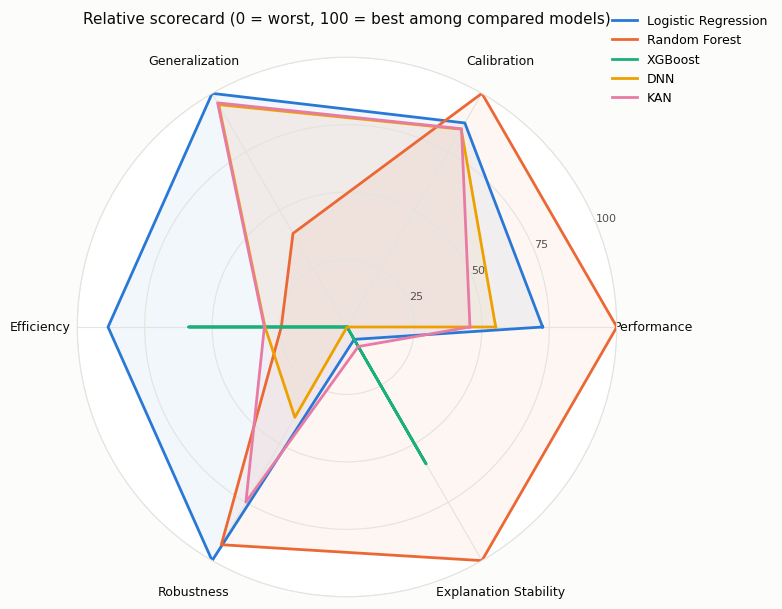

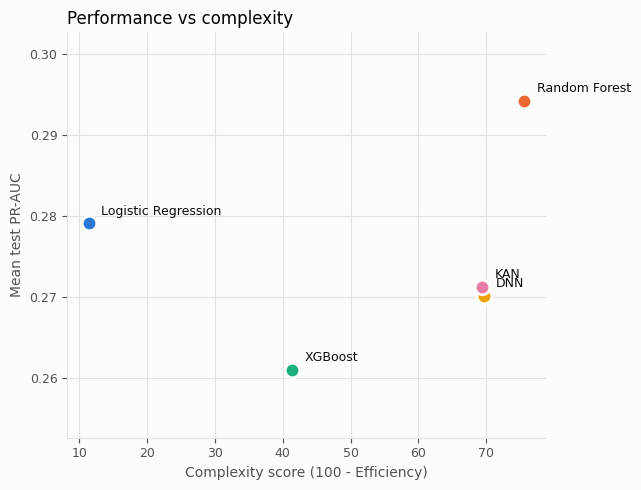

{'Logistic Regression': [], 'Random Forest': [], 'XGBoost': [], 'DNN': ['Logistic Regression', 'KAN'], 'KAN': []}


In [ ]:
from src.scoring import build_scorecard, complexity_score, find_dominated_models
from src.visualization import plot_radar, plot_tradeoff

scorecard = build_scorecard(summary, grid["complexity"])
display(scorecard.round(1))
plot_radar(scorecard); plt.show()

table = summary.join(scorecard)
table["Complexity_Score"] = complexity_score(scorecard)
plot_tradeoff(table, "Complexity_Score", "pr_auc", "Complexity score (100 - Efficiency)",
              "Mean test PR-AUC", "Performance vs complexity", min_y_span=0.05); plt.show()

print(find_dominated_models(table, maximize=["pr_auc", "explanation_stability"], minimize=["Complexity_Score"]))
save_tables(cfg.output_dir, grid, tests, summary, scorecard)

### 10. Robustness and the full figure set
Runs drift (PSI), sensitivity, stress and the chronological backtest, then draws every remaining figure (ROC, confusion matrices, threshold trade-off, importance bars, seed boxplots, rank agreement, robustness charts, trade-off dashboard) and saves them to `outputs/figures/`. Sensitivity and stress shocks are illustrative, not macro-calibrated.

Features where a one-at-a-time ranking and the model explanation disagree most:


,Model,Feature,Spearman_with_default,Univariate_rank,Model_importance,Model_rank,Rank_gap
54,Random Forest,pub_rec_bankruptcies,-0.011,7.0,0.005,16.0,-9.0
62,Random Forest,revol_bal,0.001,15.0,0.028,6.0,9.0
78,XGBoost,revol_bal,0.001,15.0,0.055,6.0,9.0
70,XGBoost,pub_rec_bankruptcies,-0.011,7.0,0.008,16.0,-9.0
69,XGBoost,emp_length,0.015,6.0,0.025,14.0,-8.0
53,Random Forest,emp_length,0.015,6.0,0.014,13.0,-7.0
9,DNN,installment,-0.004,10.0,0.016,16.0,-6.0
27,KAN,loan_amnt,0.003,12.0,0.029,6.0,6.0


Wrote 19 figures to outputs/figures/


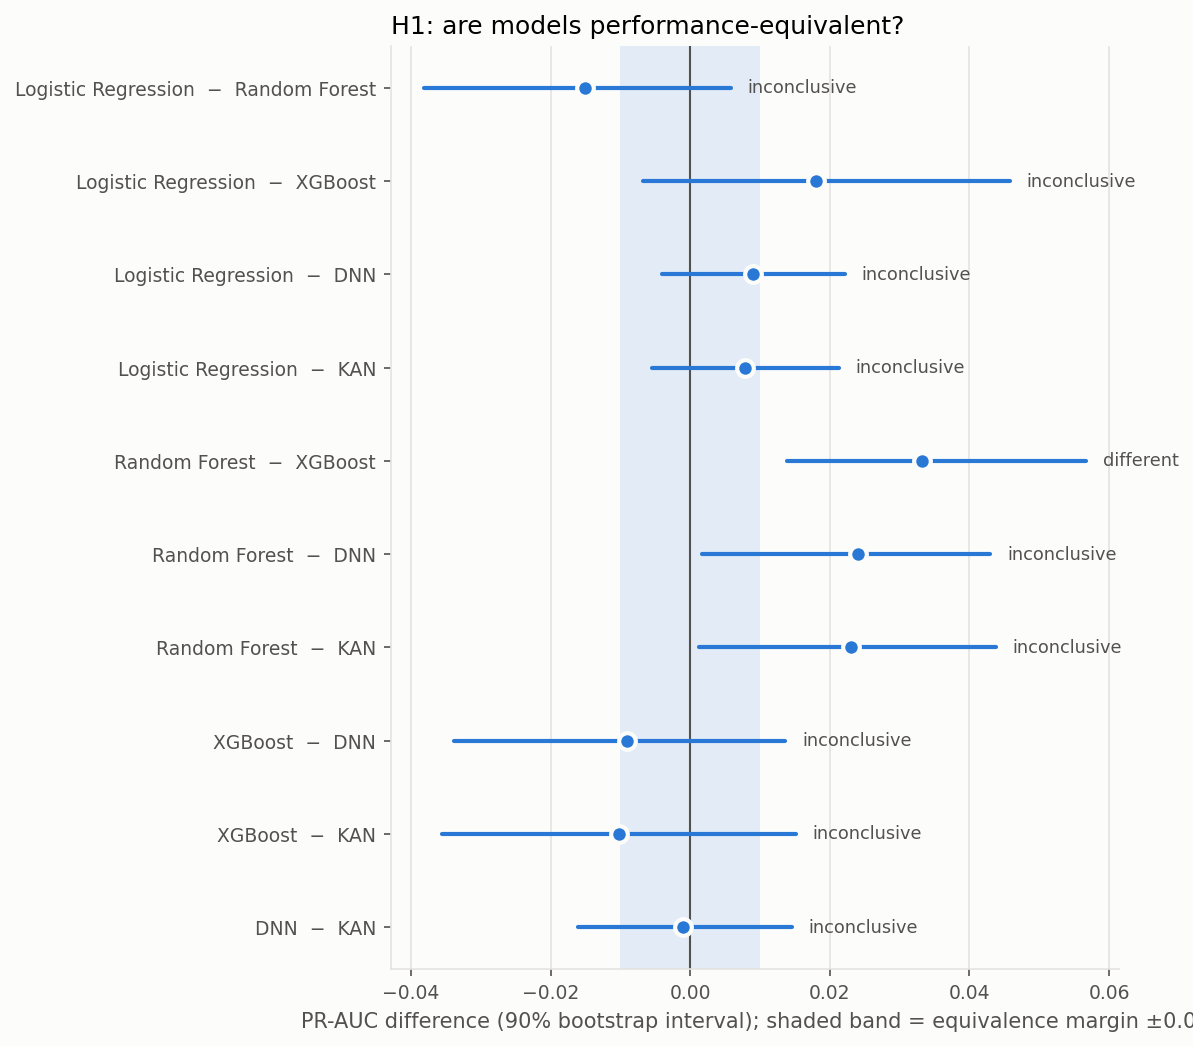

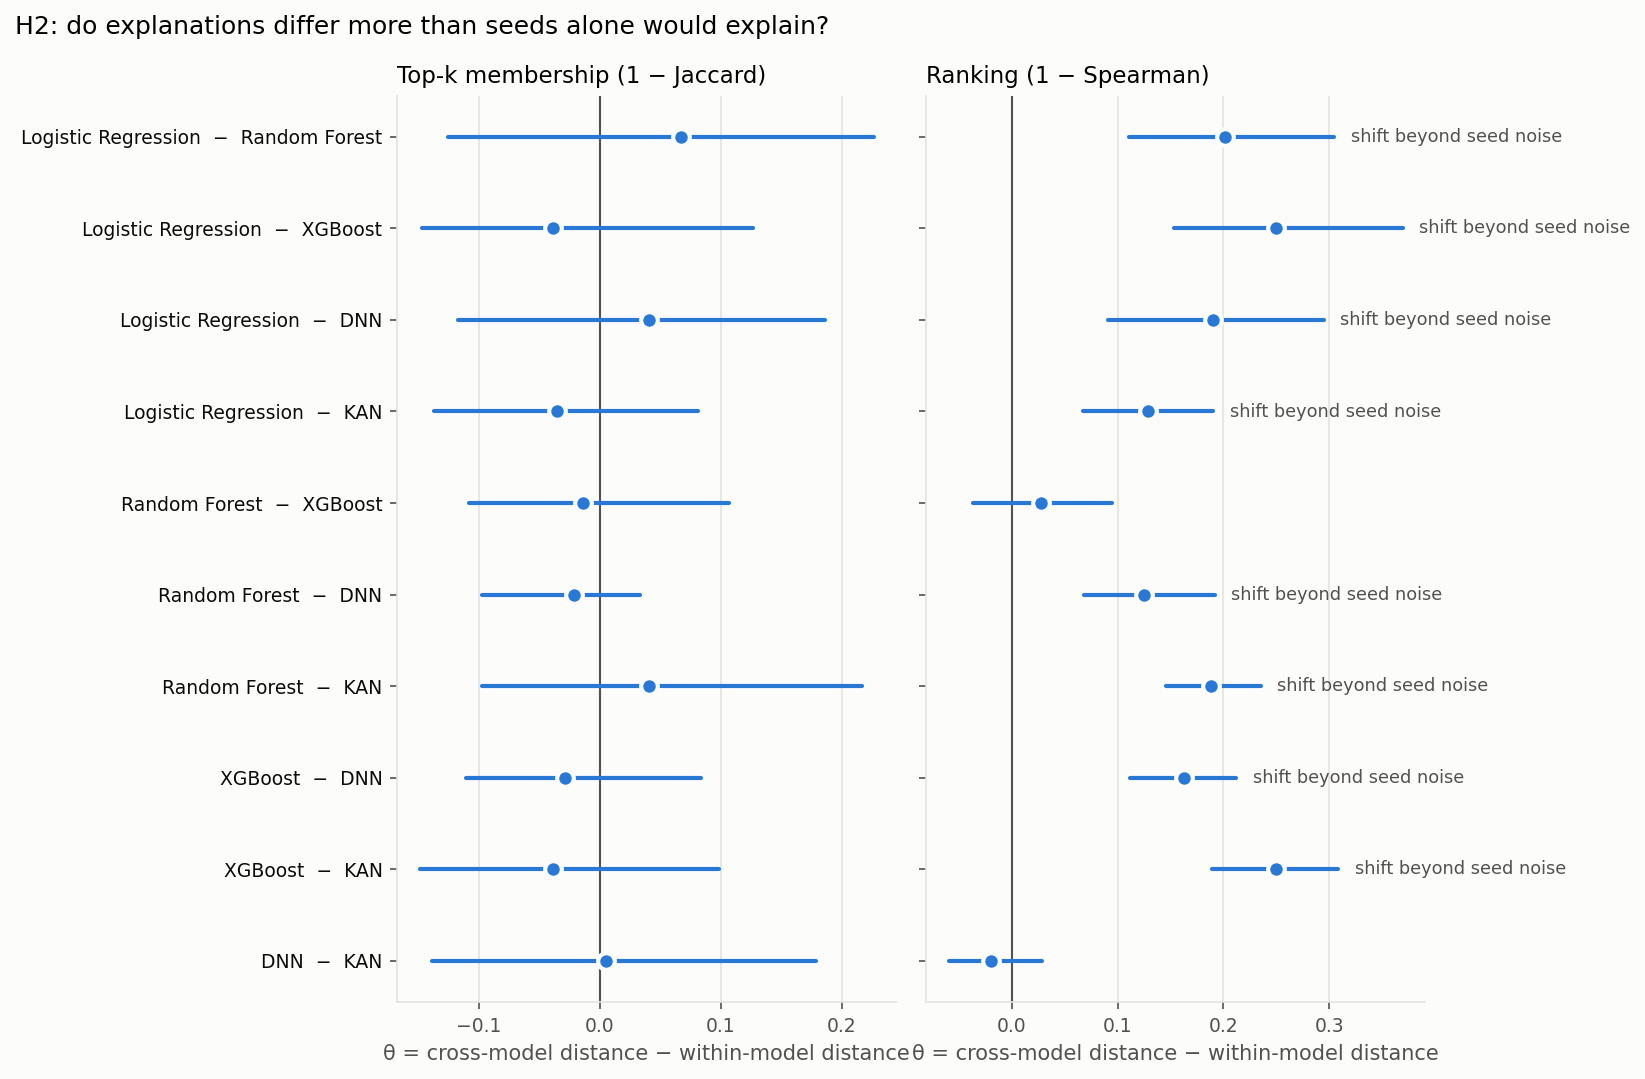

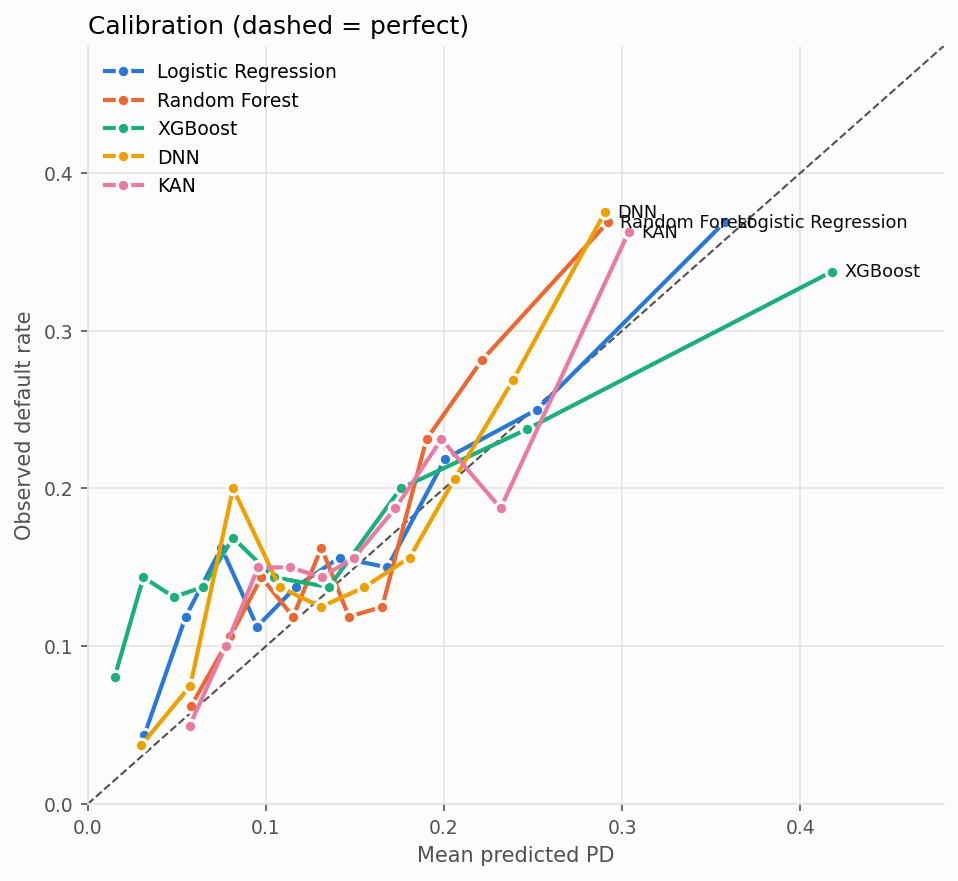

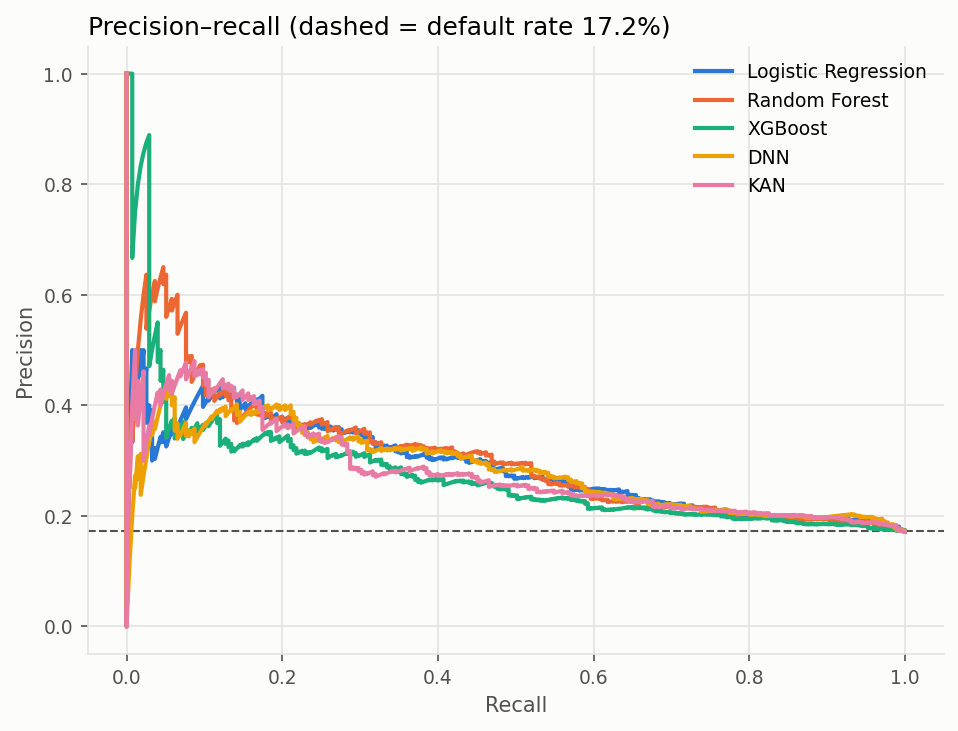

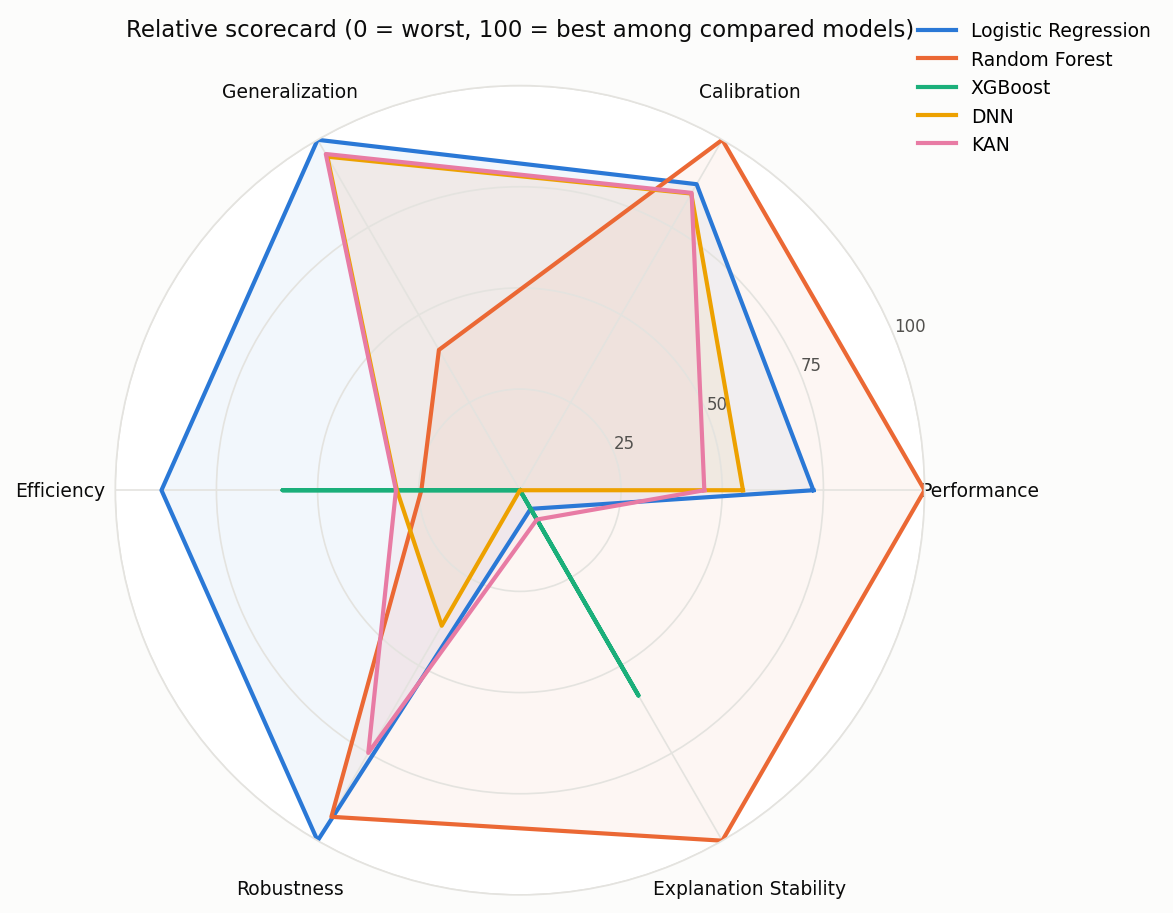

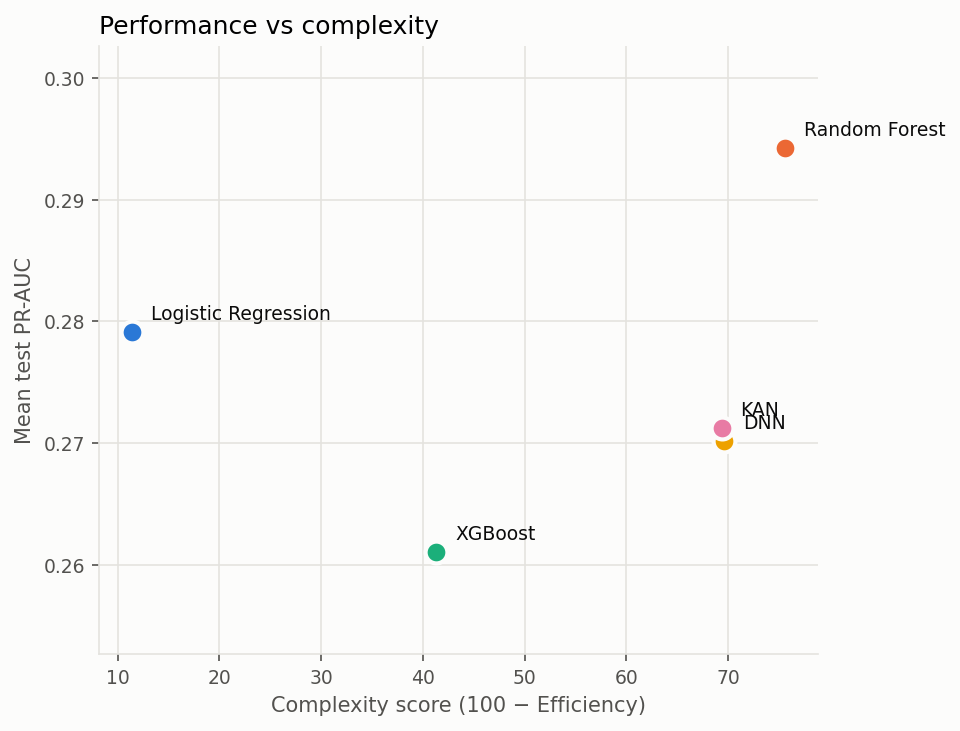

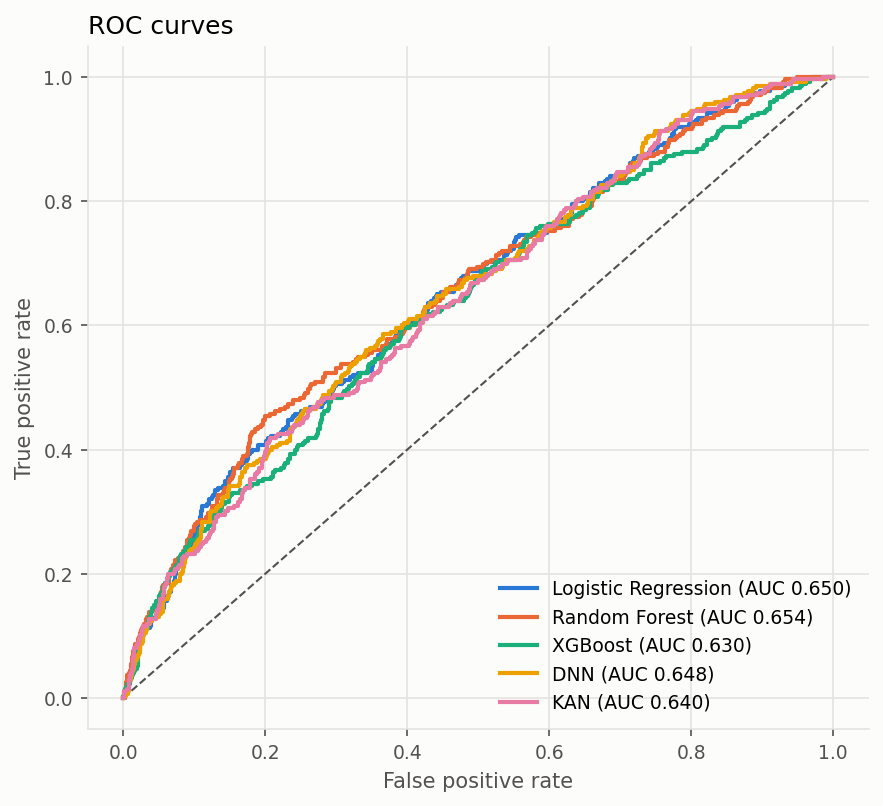

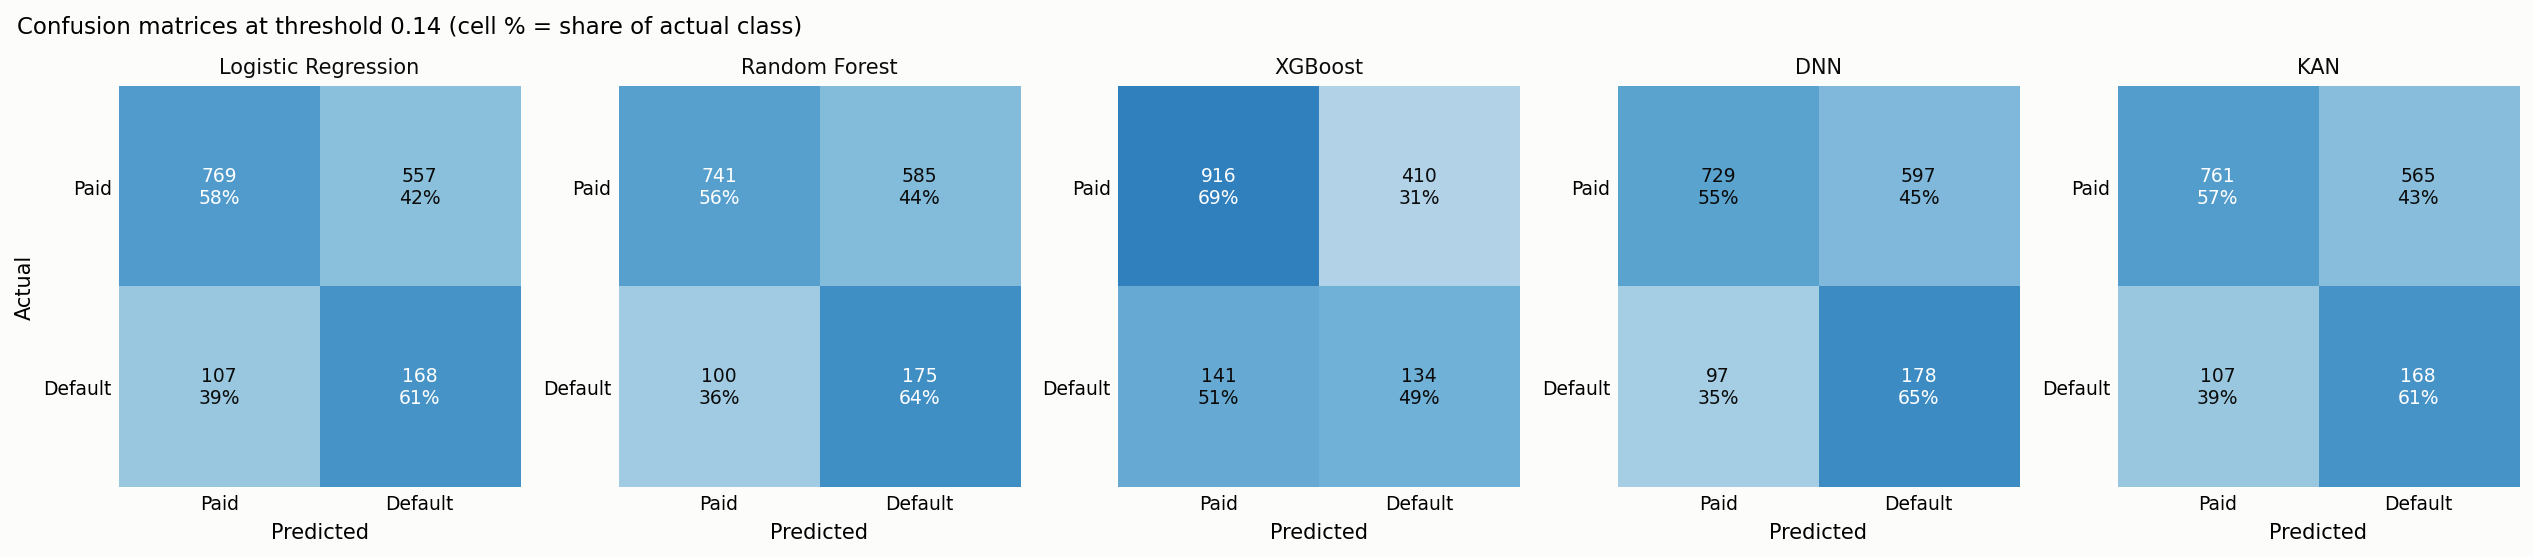

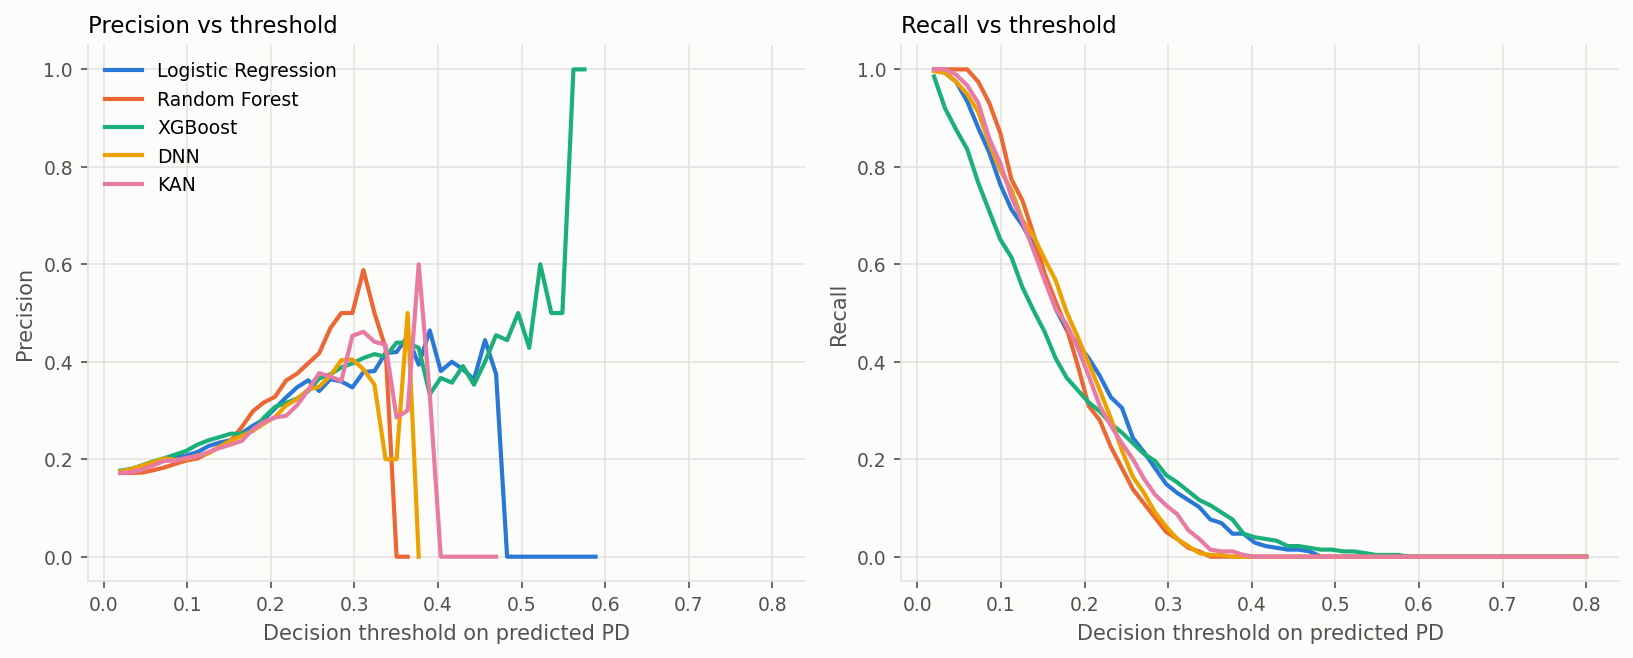

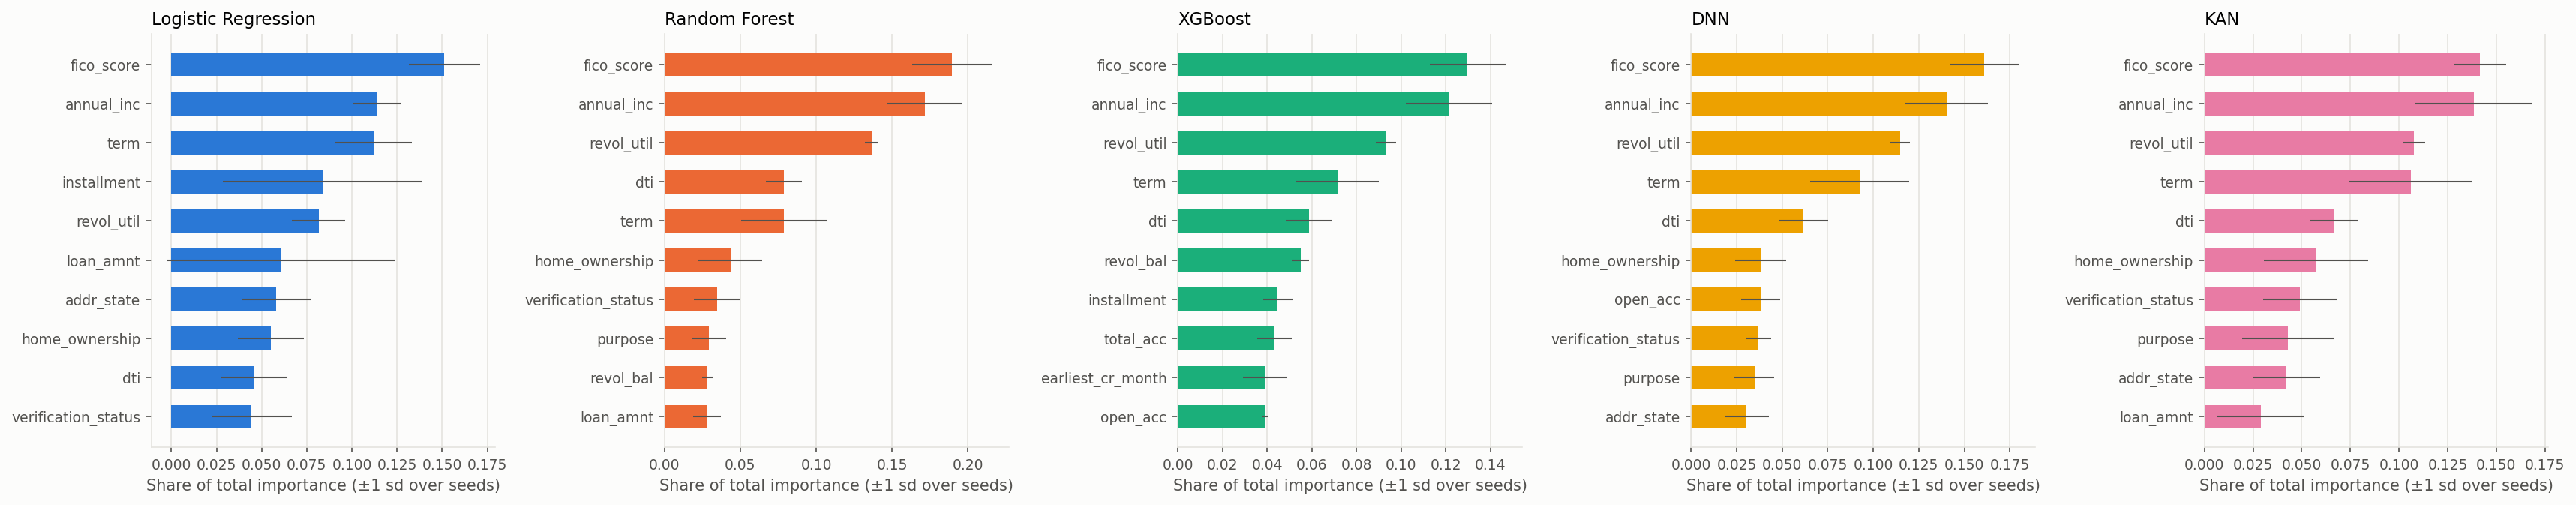

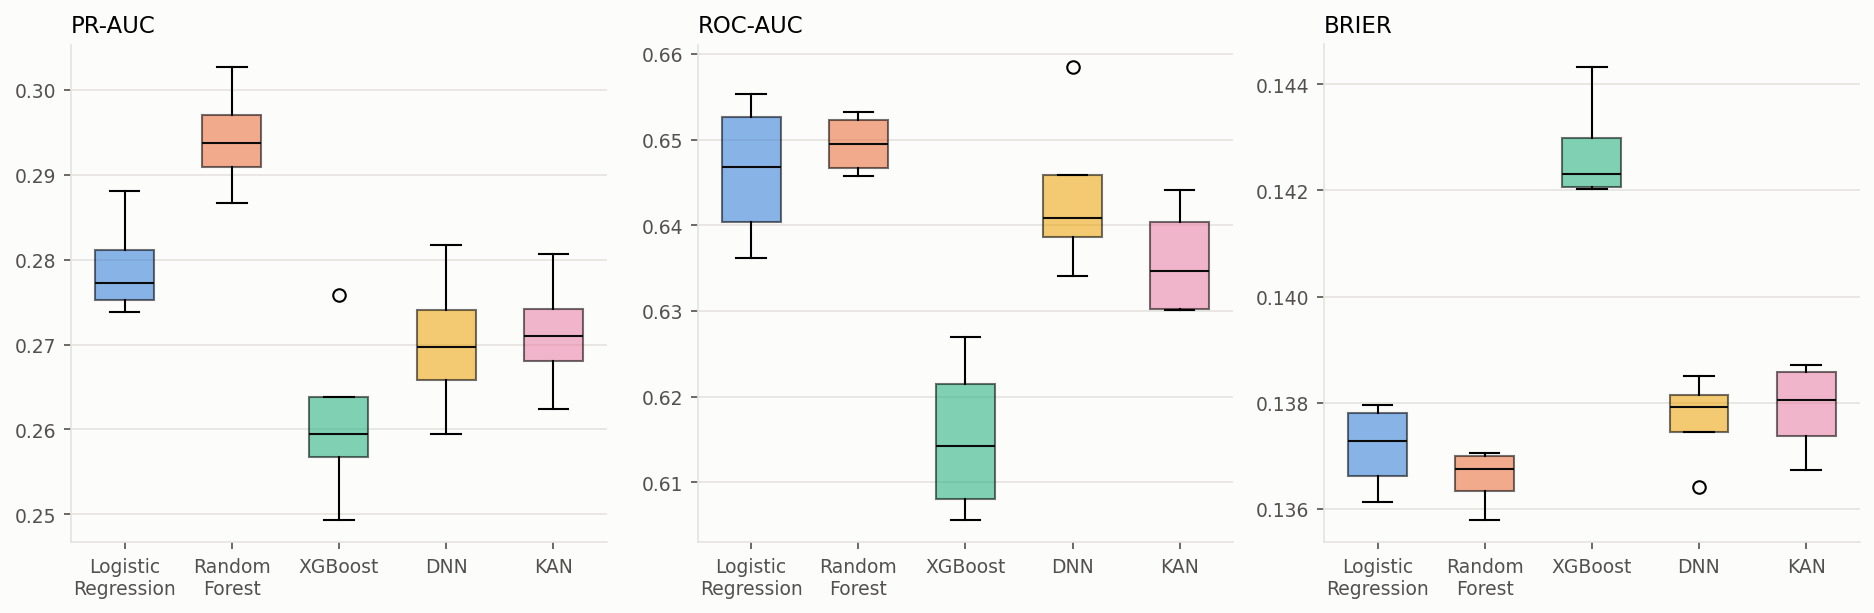

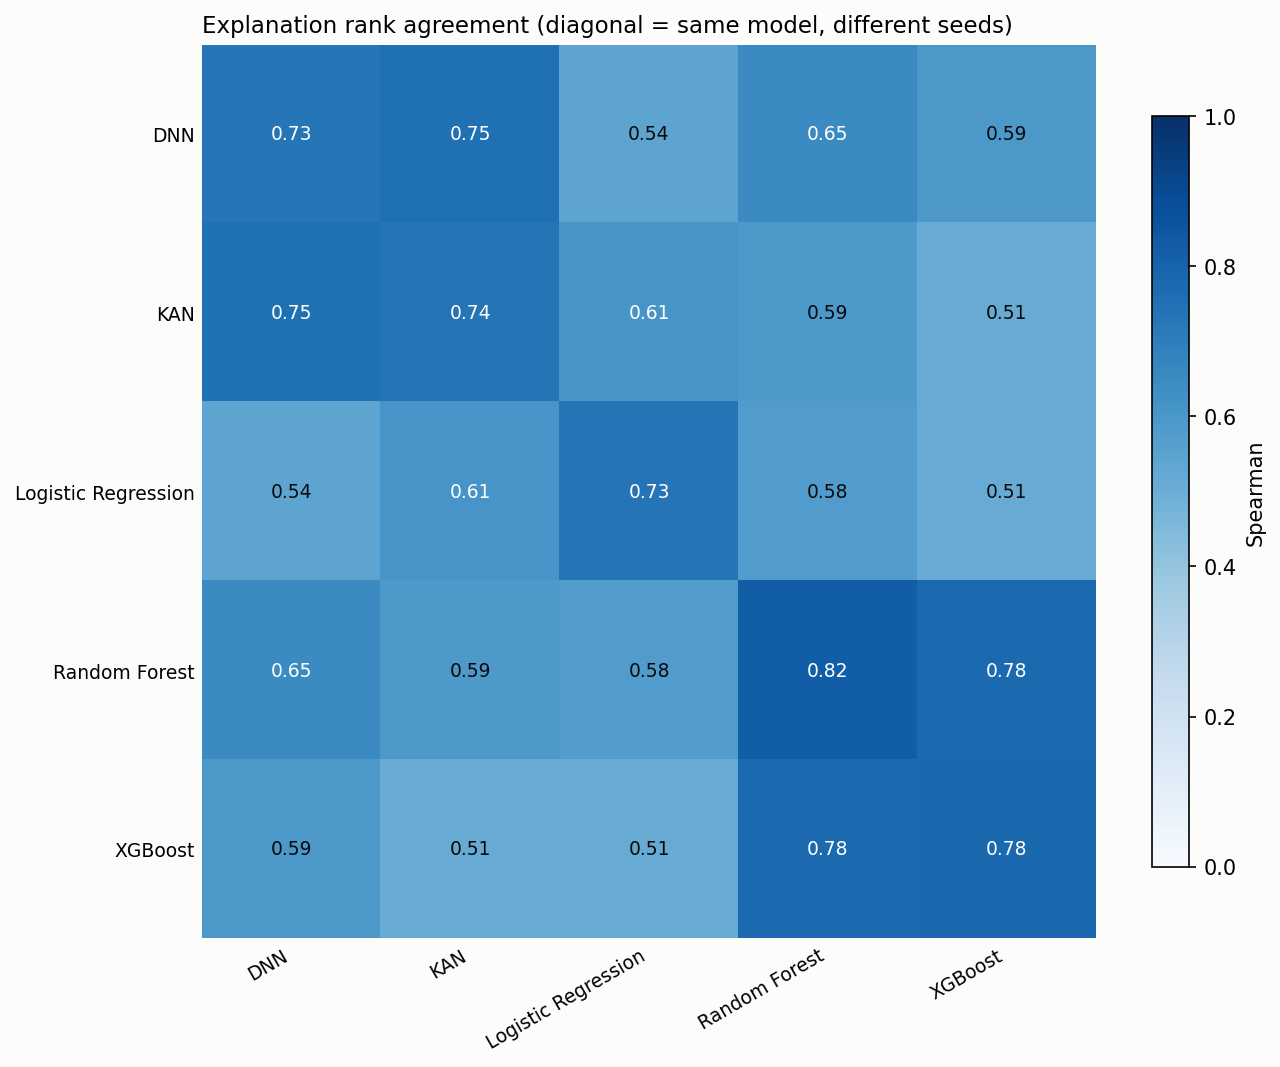

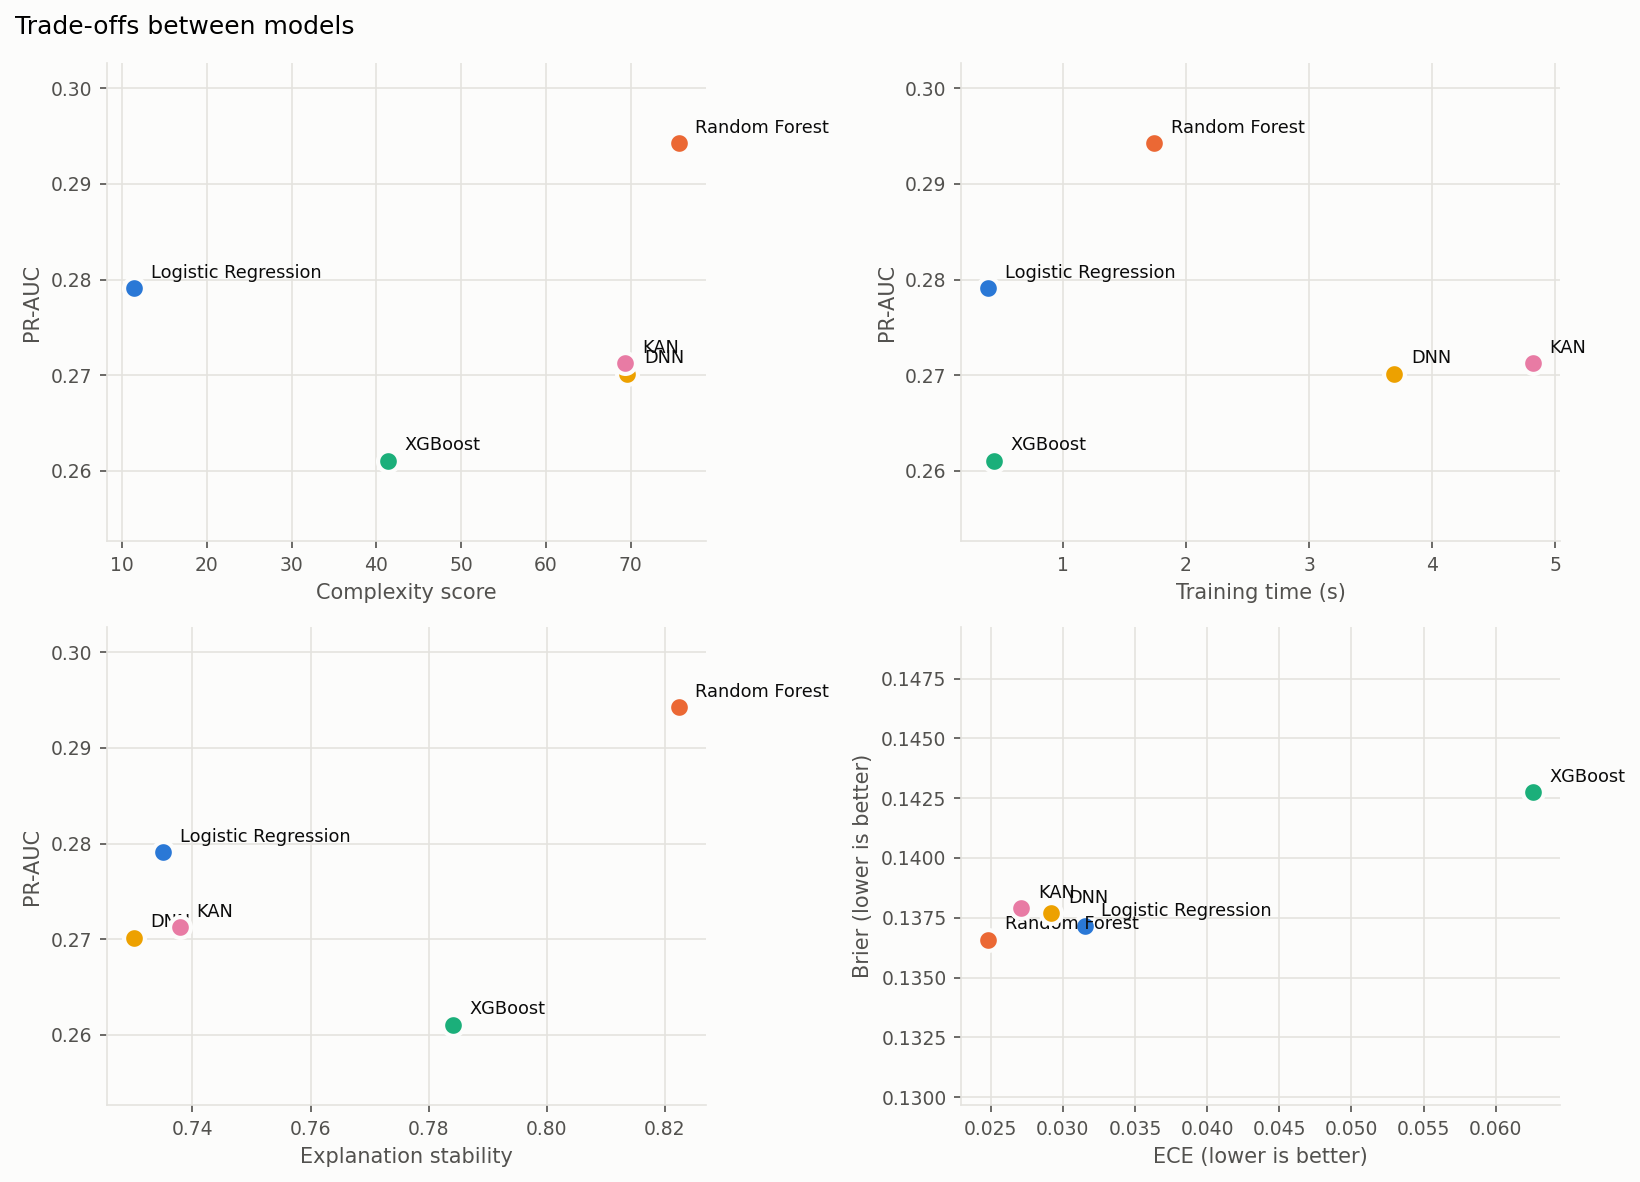

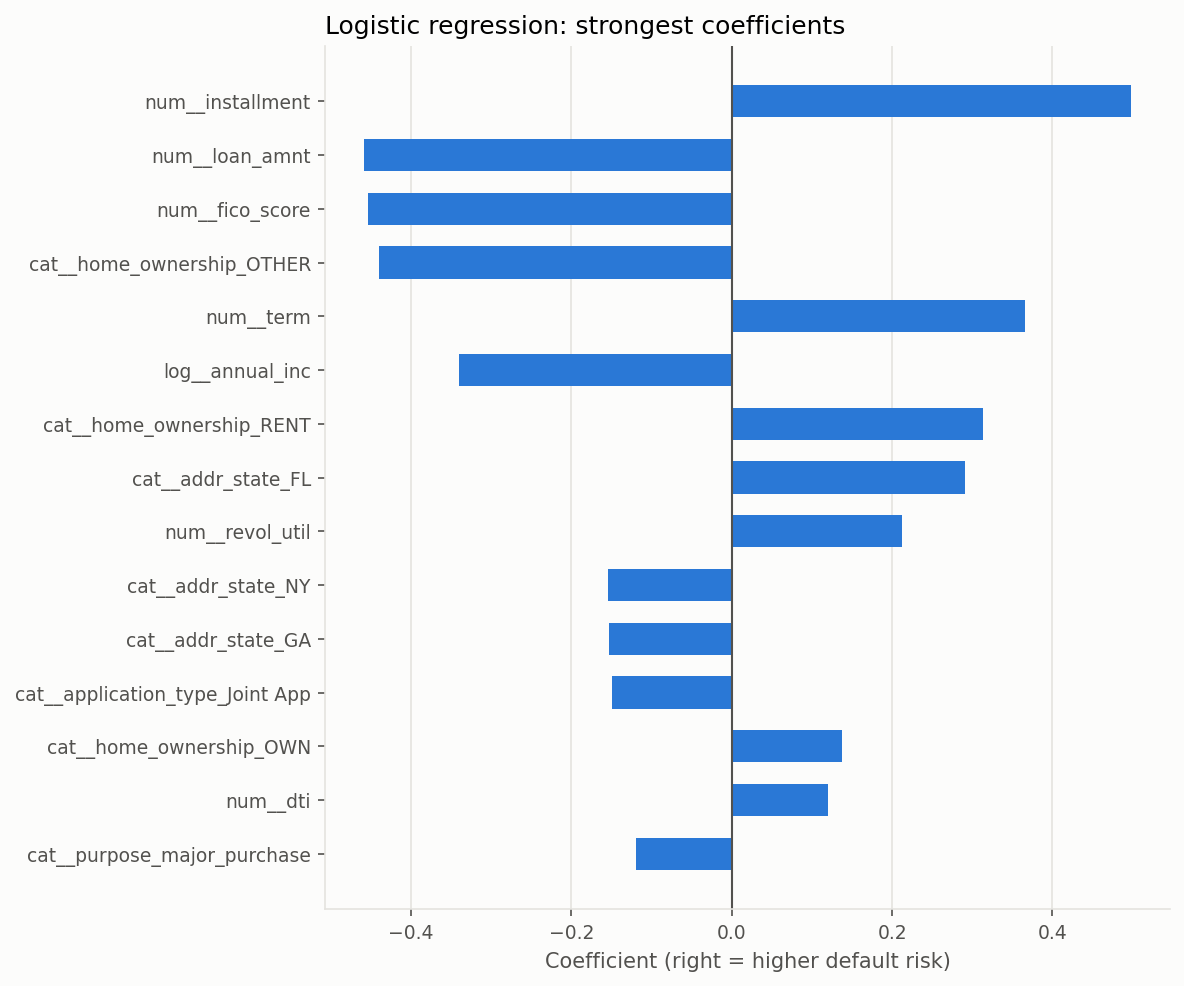

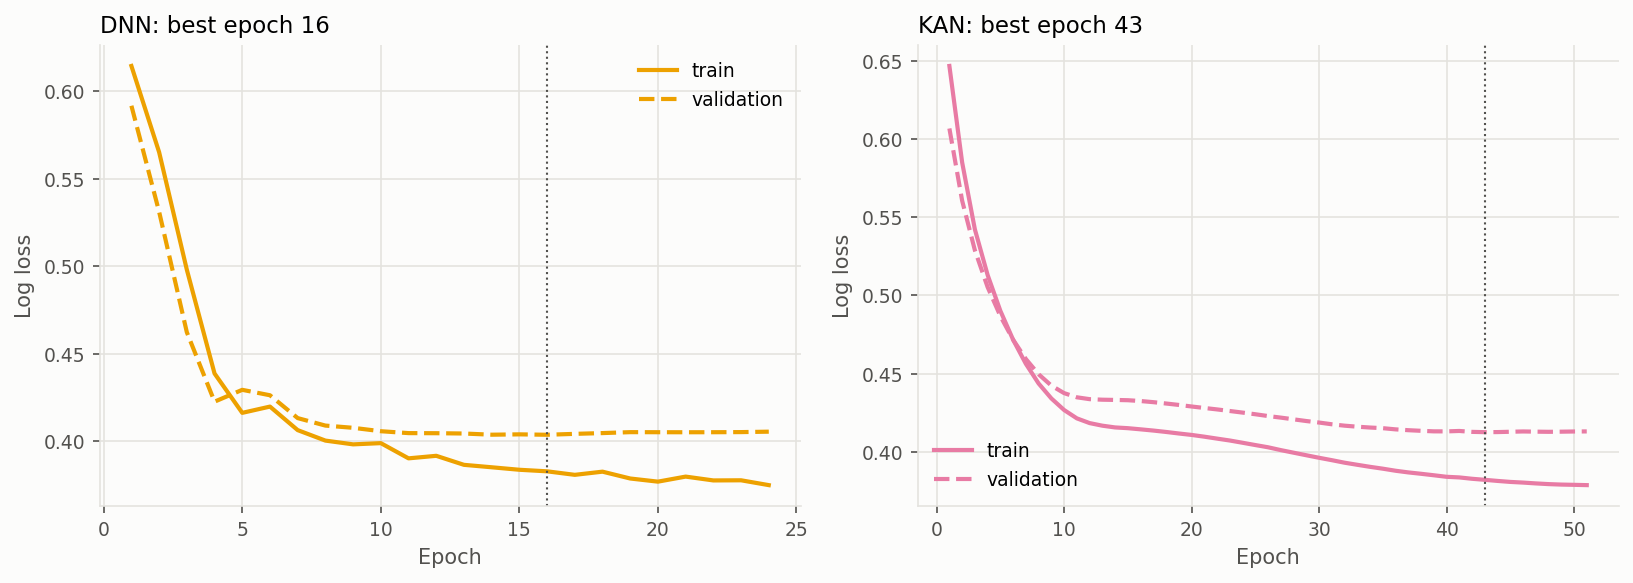

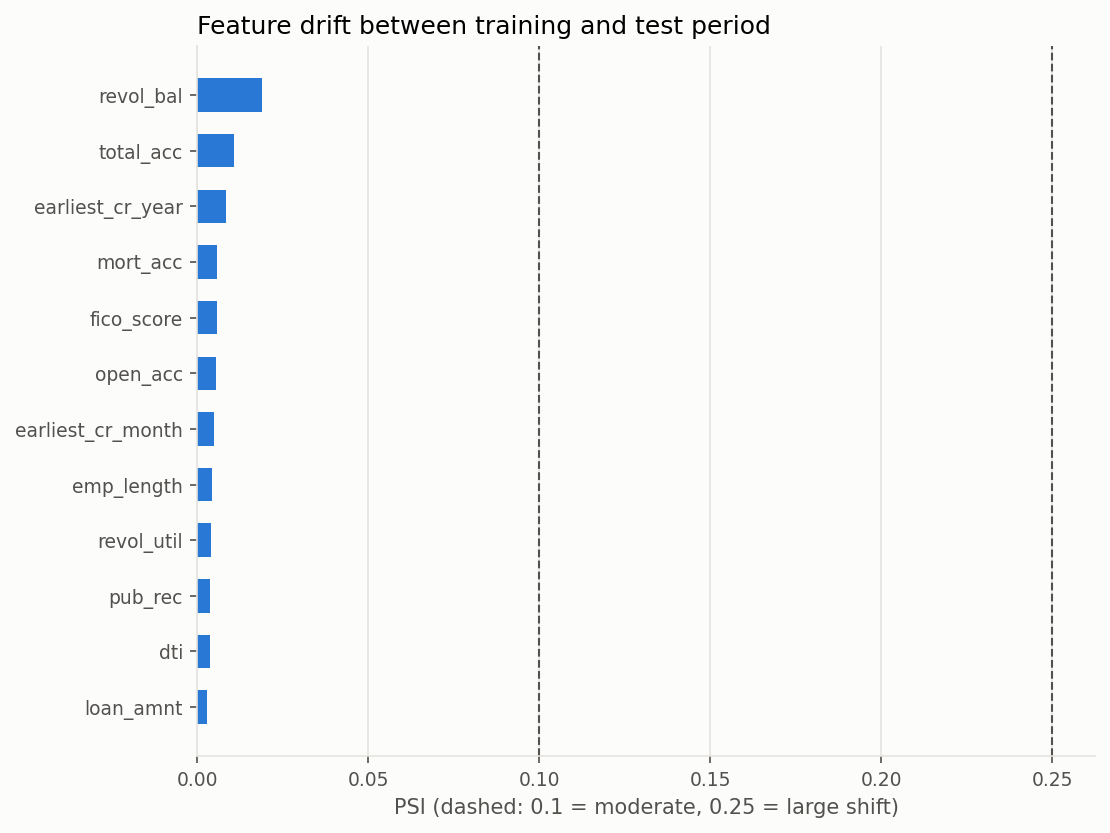

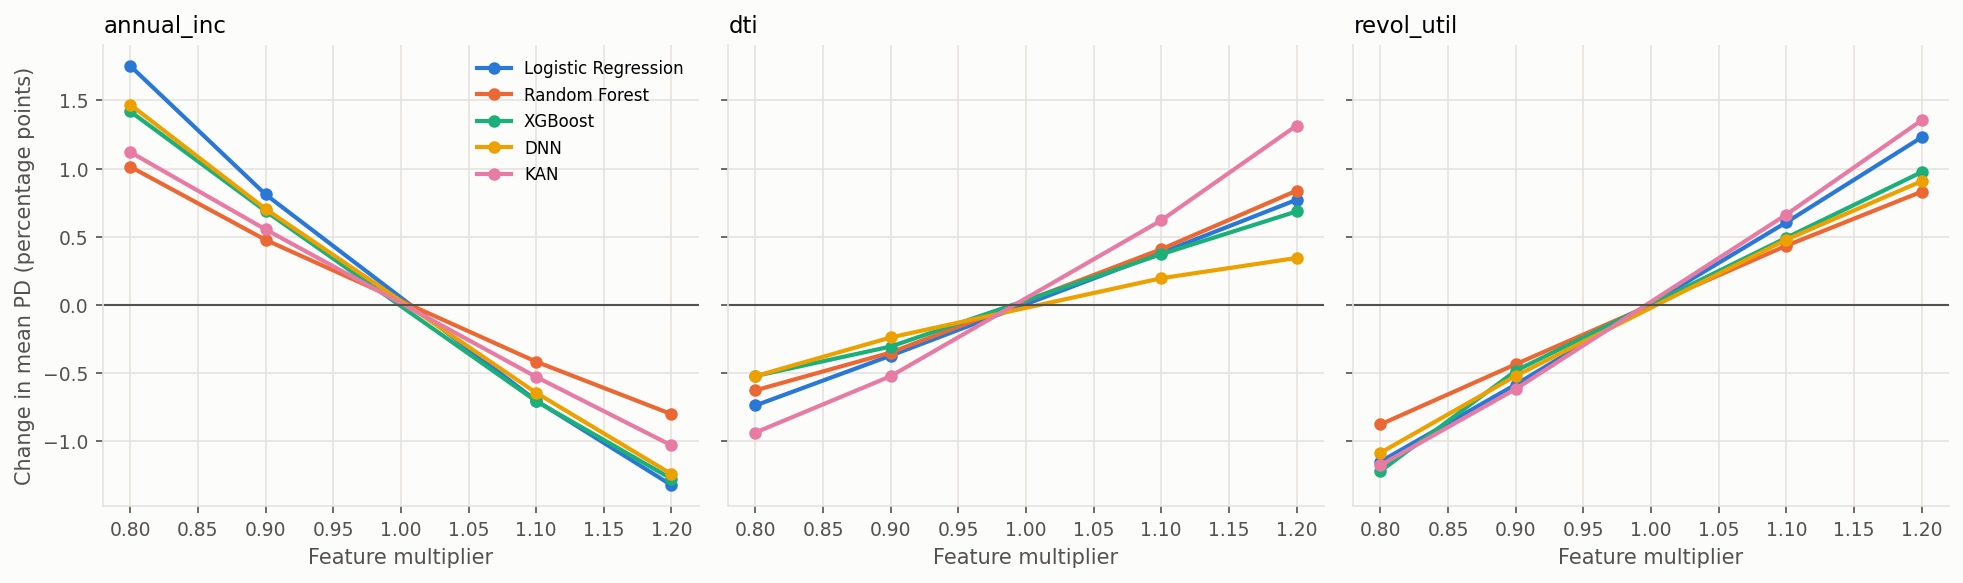

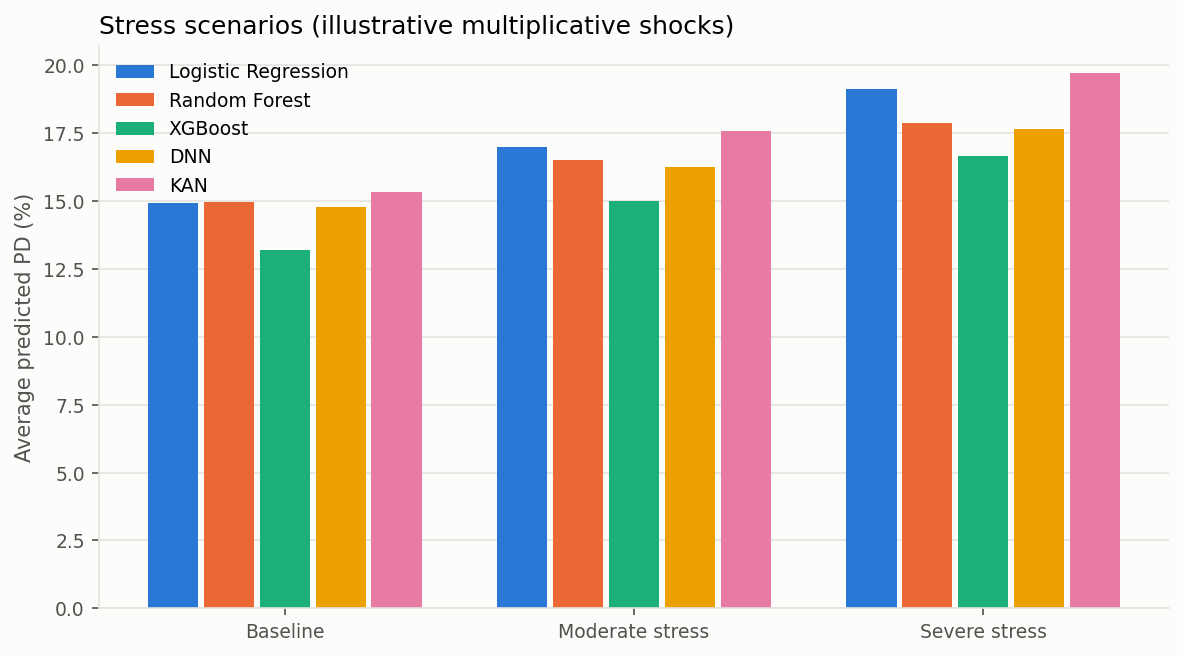

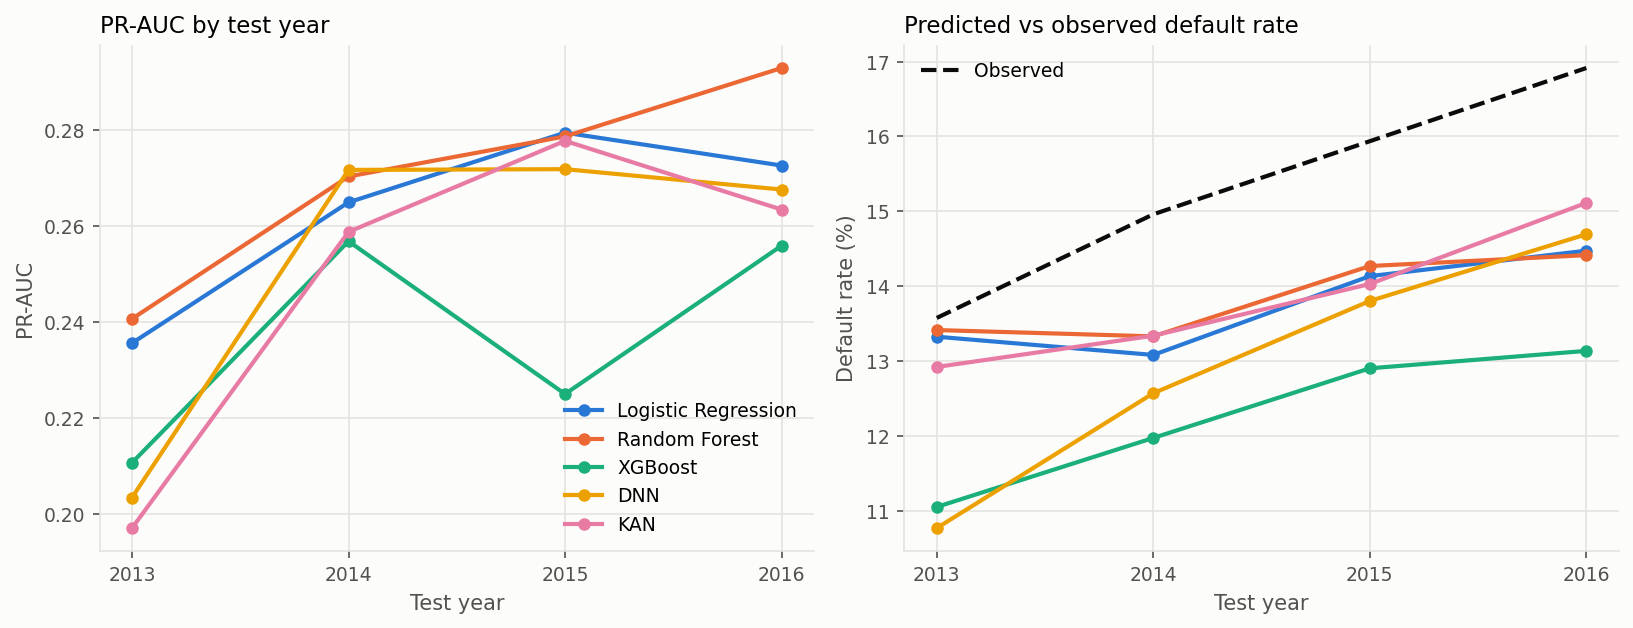

In [ ]:
from src.experiments import run_robustness
from src.visualization import save_all

frame = load_frame(cfg, USE_SYNTHETIC)
cfg_fig = replace(cfg, backtest_first_year=2013, backtest_min_train=500, backtest_min_test=100) if USE_SYNTHETIC else cfg
robustness = run_robustness(grid, splits, frame, cfg_fig, verbose=False)
result = {"grid": grid, "tests": tests, "summary": summary, "scorecard": scorecard, "robustness": robustness}
from src.eda import numeric_default_correlation, univariate_vs_explanation
gap = univariate_vs_explanation(numeric_default_correlation(frame), grid["importances"])
print("Features where a one-at-a-time ranking and the model explanation disagree most:")
display(gap.reindex(gap["Rank_gap"].abs().sort_values(ascending=False).index).head(8).round(3))
paths = save_all(result, ROOT / "outputs" / "figures")
print(f"Wrote {len(paths)} figures to outputs/figures/")
from IPython.display import Image, display as _d
for p in paths:
    _d(Image(filename=str(p), width=800))

### Reading the results

- An *inconclusive* H1 verdict means the data cannot show equivalence **or** a difference; it is not evidence of "no difference".
- H3 is only meaningful when H1 says *equivalent* and H2 survives Holm correction.
- SHAP explains model behaviour, not causes. The scorecard is relative: keep the raw tables next to it.